# IT462 — EDAgent: Consolidated Exploratory & Road-Safety Analysis (v6 — corrected run-ready release)
## Allegheny County Crash Data (2004–2024)

**Group B8:** Vishesh Shah (202403050), Atharv Trivedi (202401230), Darshan Talati (202401046), Dharmesh Upadhyay (202401049).

**Dataset file expected:** `2c13021f-74a9-4289-a1e5-fe0472c89881.csv` (complete 2004–2024 file; approximately 248,810 rows and 191 columns). The loader checks the actual year range and row count so an older extract cannot be mistaken for the full dataset.

**Dataset source:** [WPRDC — Allegheny County crash data](https://data.wprdc.org/dataset/allegheny-county-crash-data/resource/2c13021f-74a9-4289-a1e5-fe0472c89881). Historical code definitions should be checked against the relevant data dictionary/PennDOT codebook when interpreting individual source codes.

All statistics and charts are computed from the uploaded CSV. No synthetic observations are added.

**Interpretation boundary:** These are police-reported crash records, not all traffic exposure. A larger crash count cannot by itself establish a higher crash risk. Reporting coverage, field definitions, and missingness can change over time. This notebook does not claim causal effects.

<!--
**Version 6 | single analysis notebook:** `analysis/EDA_v6.ipynb`. This notebook keeps the v5 descriptive workflow but adds controlled quality gates, defensible spatial screening, model uncertainty, and conditional site-frequency / intervention-evidence steps. **Do not interpret this unexecuted file as a new numerical validation.**
 -->

**Research questions:** (1) What patterns are present among reported crashes? (2) Which recorded circumstances are associated with serious/fatal outcomes after the 2016 severity-standard change? (3) Where is historical crash concentration suitable for further site investigation? (4) Can eligible site-year crash frequency be estimated with defensible exposure? (5) What countermeasure scenario is supported by reviewed Crash Modification Factor (CMF) evidence?

**Target and time contract:** Known severity classes **1/2 = serious or fatal**, **0/3/4 = other known severity**; 8/9/missing/unmapped remain unknown. Severity models estimate outcomes **conditional on an already reported crash**, and never an imminent crash forecast. Data scope is **2004–2024 only** (no 2025). The original v5 numbers are historical reference evidence, not v6 output.

**Execution guide:** Run from top to bottom after placing the cumulative CSV in Colab `/content/` or in the repository `data/raw/`. County boundary lookup requires internet the first time or a cached boundary file. Optional network, exposure, SPF and CMF analyses explicitly skip when required approved reference data is absent. Outputs from an initial run require human review before website use.


## 1. Environment and reproducible setup

The notebook mainly uses Python, NumPy, pandas, Matplotlib, and Seaborn—the tools practised in the course labs. Scikit-learn supports supervised and exploratory models; SciPy and statsmodels support inference; GeoPandas/Shapely handle county geometry when available.

In [45]:
# Set consistent plot styling so charts across sections are easy to compare.
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)
plt.rcParams["figure.dpi"] = 110
# v6: fix the seed and record runtime versions without changing the original plot defaults.
import sys, json, hashlib, platform
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

def installed_version(package):
    """Report a dependency's installed version; missing optional packages are explicit."""
    try:
        return version(package)
    except PackageNotFoundError:
        return "not installed"

PACKAGE_VERSIONS = {p: installed_version(p) for p in
                    ["numpy", "pandas", "matplotlib", "seaborn", "scipy",
                     "statsmodels", "scikit-learn", "shapely", "geopandas", "joblib"]}
print("Python:", sys.version.split()[0], "| Platform:", platform.system())
print("Package versions:")
display(pd.Series(PACKAGE_VERSIONS, name="installed_version").to_frame())

# Detect an actual EDAgent repository instead of assuming Colab and local paths match.
# Running Jupyter from either the repo root or repo/analysis resolves to the same root.
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "analysis").is_dir() and (p / "data").is_dir()), None)
WORK_ROOT = REPO_ROOT if REPO_ROOT is not None else Path.cwd()
OUTPUT_ROOT = WORK_ROOT / "analysis" / "outputs"
REFERENCE_ROOT = WORK_ROOT / "data" / "reference"
print("Repository detected:", REPO_ROOT if REPO_ROOT else "None (standalone / Colab mode)")


Python: 3.13.18 | Platform: Linux
Package versions:


,installed_version
numpy,2.4.6
pandas,2.2.3
matplotlib,3.10.0
seaborn,0.13.2
scipy,1.16.3
statsmodels,0.15.0
scikit-learn,1.6.1
shapely,2.2.0
geopandas,1.2.0
joblib,1.6.0


Repository detected: /content


## 2. Load and validate the complete dataset

Upload the CSV resource file to Colab with the filename `2c13021f-74a9-4289-a1e5-fe0472c89881.csv`. The loader also accepts the same resource ID without the `.csv` suffix. It checks only this resource ID (including a duplicate-upload suffix), rather than selecting an unrelated CSV.

We retain the original columns. We do not fill missing values at this stage because a blank value is not necessarily zero or an unknown category.

### What this code does — loading and validating the complete dataset

This block locates the uploaded WPRDC resource using its exact resource ID, reads the complete CSV, and checks that the expected columns exist. It then checks the actual year range and number of rows. This is important because a file can have the correct resource name but still be an older extract.

The final displays confirm which file was loaded, how many records and columns it contains, how many records belong to each year, and what the first five rows look like. No sampling or year filtering is performed here.

In [46]:
# Use the WPRDC resource ID supplied for this project.
DATA_RESOURCE_ID = "2c13021f-74a9-4289-a1e5-fe0472c89881"

# Check exact filenames first, then allow a single Colab duplicate-upload suffix.
search_directories = list(dict.fromkeys([
    Path.cwd(), Path.cwd() / "data" / "raw",
    Path.cwd().parent / "data" / "raw",
    WORK_ROOT / "data" / "raw", Path("/content"), Path("/mnt/data")
]))
preferred_names = [
    f"{DATA_RESOURCE_ID}.csv",
    DATA_RESOURCE_ID,
    f"{DATA_RESOURCE_ID}.CSV"
]
csv_matches = []
for directory in search_directories:
    for filename in preferred_names:
        candidate = directory / filename
        if candidate.is_file() and candidate not in csv_matches:
            csv_matches.append(candidate)

if not csv_matches:
    for directory in search_directories:
        for candidate in directory.glob(f"{DATA_RESOURCE_ID}*.csv"):
            if candidate.is_file() and candidate not in csv_matches:
                csv_matches.append(candidate)

if len(csv_matches) == 1:
    csv_path = csv_matches[0]
elif len(csv_matches) > 1:
    exact_matches = [p for p in csv_matches if p.name == f"{DATA_RESOURCE_ID}.csv"]
    if len(exact_matches) == 1:
        csv_path = exact_matches[0]
    else:
        raise RuntimeError(
            "More than one file matches the supplied dataset resource ID. "
            f"Keep only the intended CSV or rename it exactly to {DATA_RESOURCE_ID}.csv. "
            f"Matches: {[p.name for p in csv_matches]}"
        )
else:
    raise FileNotFoundError(
        f"Could not find {DATA_RESOURCE_ID}.csv. Upload the complete CSV to Colab's Files panel "
        f"using the filename {DATA_RESOURCE_ID}.csv."
    )

# Read the complete CSV. No row limit, sampling, or year filter is applied.
data = pd.read_csv(csv_path, low_memory=False)

required_columns = [
    "CRASH_CRN", "CRASH_YEAR", "CRASH_MONTH", "MAX_SEVERITY_LEVEL",
    "WEATHER", "ROAD_CONDITION", "PERSON_COUNT", "VEHICLE_COUNT"
]
missing_required = [column for column in required_columns if column not in data.columns]
if missing_required:
    raise ValueError(f"The CSV is missing required columns: {missing_required}")

# Validate the actual contents, not just the filename.
years = pd.to_numeric(data["CRASH_YEAR"], errors="coerce")
first_year = years.min()
last_year = years.max()
row_count = len(data)

if (first_year != 2004 or last_year != 2024 or row_count < 200000
        or years.isna().any() or set(years.unique()) != set(range(2004, 2025))):
    raise ValueError(
        f"'{csv_path.name}' is not the complete project dataset. "
        f"It contains {row_count:,} rows and years {first_year}–{last_year}. "
        "The complete file should contain approximately 248,810 rows "
        "covering 2004–2024. Check the selected WPRDC resource file."
    )

print(f"Loaded complete dataset: {csv_path}")
print(f"Rows: {row_count:,} | Columns: {len(data.columns):,}")
print(f"Year range: {int(first_year)}–{int(last_year)}")
print("\nNumber of crash records by year:")
display(years.value_counts().sort_index().rename("crash_records").to_frame())
print("\nFirst five records:")
display(data.head())

# The fixed resource ID and full-period test protect against using the separate 2025 file.
# The previous v5 run had 248,810 rows; deviations are flagged rather than silently hidden.
BASELINE_V5_ROWS = 248810
if row_count != BASELINE_V5_ROWS:
    warnings.warn(f"Source row count ({row_count:,}) differs from v5 ({BASELINE_V5_ROWS:,}). "
                  "Verify the publisher's resource revision before interpreting trends.")
if data["CRASH_CRN"].isna().any() or data["CRASH_CRN"].duplicated().any():
    raise ValueError("CRASH_CRN must be populated and unique: inspect source before proceeding.")

# Stream the checksum so the exact input file can be traced without duplicating a large CSV.
source_hash = hashlib.sha256()
with csv_path.open("rb") as source_stream:
    for binary_block in iter(lambda: source_stream.read(1024 * 1024), b""):
        source_hash.update(binary_block)
SOURCE_METADATA = {
    "resource_id": DATA_RESOURCE_ID, "filename": csv_path.name,
    "source_url": "https://data.wprdc.org/dataset/allegheny-county-crash-data/resource/" + DATA_RESOURCE_ID,
    "sha256": source_hash.hexdigest(), "size_bytes": csv_path.stat().st_size,
    "rows": int(len(data)), "columns": int(len(data.columns)),
    "first_year": int(first_year), "last_year": int(last_year),
    "source_checked_utc": datetime.now(timezone.utc).isoformat(),
    "reference_baseline_v5_rows": BASELINE_V5_ROWS
}
print("Source SHA-256:", SOURCE_METADATA["sha256"])
print("Unique CRASH_CRN:", data["CRASH_CRN"].nunique())


Loaded complete dataset: /content/2c13021f-74a9-4289-a1e5-fe0472c89881.csv
Rows: 248,810 | Columns: 191
Year range: 2004–2024

Number of crash records by year:


,crash_records
CRASH_YEAR,
2004,12535
2005,12215
2006,11747
2007,12238
2008,11858
2009,11677
2010,11320
2011,12189
2012,12230



First five records:


,_id,CRASH_CRN,DISTRICT,CRASH_COUNTY,MUNICIPALITY,POLICE_AGCY,CRASH_YEAR,CRASH_MONTH,DAY_OF_WEEK,TIME_OF_DAY,HOUR_OF_DAY,ILLUMINATION,WEATHER,ROAD_CONDITION,COLLISION_TYPE,RELATION_TO_ROAD,INTERSECT_TYPE,TCD_TYPE,URBAN_RURAL,LOCATION_TYPE,...,NHTSA_AGG_DRIVING,PSP_REPORTED,RUNNING_STOP_SIGN,TRAIN,TROLLEY,ROADWAY_CRN,RDWY_SEQ_NUM,ADJ_RDWY_SEQ,ACCESS_CTRL,ROADWAY_COUNTY,LANE_COUNT,RDWY_ORIENT,ROAD_OWNER,ROUTE,SPEED_LIMIT,SEGMENT,OFFSET,STREET_NAME,TOT_INJ_COUNT,SCHOOL_BUS_UNIT
0,1,2004000001,11,2,2454,02454,2004,1,5,257.0,2.0,2.0,1.0,0.0,7,2,0,0,3,0,...,0.0,0.0,0.0,0.0,0.0,2.004000e+09,3.0,3.0,3.0,2.0,2.0,E,2.0,2032,35.0,10.0,1000.0,LEWIS RUN RD,NaN,NaN
1,2,2004000010,11,2,2440,02440,2004,1,5,1027.0,10.0,1.0,1.0,6.0,7,5,0,0,3,0,...,0.0,0.0,0.0,0.0,0.0,2.004000e+09,3.0,3.0,NaN,2.0,2.0,W,3.0,NaN,35.0,NaN,NaN,COAL VALLEY RD,NaN,NaN
2,3,2004000016,11,2,2203,02203,2004,1,5,1839.0,18.0,2.0,1.0,0.0,7,5,3,3,3,0,...,0.0,0.0,0.0,0.0,0.0,2.004000e+09,3.0,4.0,NaN,2.0,2.0,W,2.0,3082,35.0,NaN,NaN,CLINTON FRANKFORT RD,NaN,NaN
3,4,2004000022,11,2,2404,02404,2004,1,6,914.0,9.0,1.0,1.0,1.0,4,1,1,2,3,0,...,0.0,0.0,0.0,0.0,0.0,2.004000e+09,3.0,4.0,NaN,2.0,2.0,N,4.0,NaN,25.0,NaN,NaN,NORTH BALPH AV,NaN,NaN
4,5,2004000030,11,2,2419,02419,2004,1,5,2230.0,22.0,3.0,1.0,0.0,1,1,0,0,3,0,...,0.0,0.0,0.0,0.0,0.0,2.004000e+09,3.0,3.0,NaN,2.0,2.0,S,4.0,NaN,20.0,NaN,NaN,THORNBERRY DR,NaN,NaN


Source SHA-256: c58a3901ee9aa845f5b33a9a3e930a2b95027367e5b2fef0225d4539db884511
Unique CRASH_CRN: 248810


## 3. Initial inspection

Before plotting, we check the shape, column types, unique crash identifiers, and a compact statistical summary. A numeric storage type does not automatically mean that a variable is a measurement: many fields are numeric category codes.

### What this code does — initial dataset inspection

This block gives a first overview before any cleaning or analysis:

- `data.shape` reports the number of rows and columns.
- `nunique()` checks how many distinct crash IDs exist, which helps identify repeated identifiers.
- `dtypes.value_counts()` summarises the storage types used by the columns.
- `describe()` gives basic statistics for numeric columns, such as count, mean, standard deviation, minimum and quartiles.
- `groupby("CRASH_YEAR").size()` counts how many crash records are present in each year.

The purpose is to understand the size, structure and basic numerical behaviour of the raw dataset.

In [47]:
print("Dataset shape:", data.shape)
print("Unique crash IDs:", data["CRASH_CRN"].nunique(), "out of", len(data))
print("\nData types:")
display(data.dtypes.value_counts().rename("number_of_columns").to_frame())

print("\nStatistical summary of numeric columns:")
display(data.describe().T.round(2).head(35))

print("\nCrash records by year:")
year_counts = data.groupby("CRASH_YEAR").size()
display(year_counts.rename("crash_records").to_frame())

Dataset shape: (248810, 191)
Unique crash IDs: 248810 out of 248810

Data types:


,number_of_columns
float64,117
int64,54
object,20



Statistical summary of numeric columns:


,count,mean,std,min,25%,50%,75%,max
_id,248810.0,1.244058e+05,71825.95,1.000000e+00,6.220325e+04,1.244055e+05,1.866078e+05,2.488180e+05
CRASH_CRN,248810.0,2.013944e+09,5914584.80,2.004000e+09,2.009026e+09,2.014049e+09,2.019045e+09,2.025050e+09
DISTRICT,248810.0,1.100000e+01,0.00,1.100000e+01,1.100000e+01,1.100000e+01,1.100000e+01,1.100000e+01
CRASH_COUNTY,248810.0,2.000000e+00,0.00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00
MUNICIPALITY,248810.0,2.288490e+03,120.66,2.101000e+03,2.207000e+03,2.301000e+03,2.408000e+03,2.491000e+03
CRASH_YEAR,248810.0,2.013810e+03,5.97,2.004000e+03,2.009000e+03,2.014000e+03,2.019000e+03,2.024000e+03
CRASH_MONTH,248810.0,6.580000e+00,3.56,1.000000e+00,3.000000e+00,7.000000e+00,1.000000e+01,1.200000e+01
DAY_OF_WEEK,248810.0,4.140000e+00,1.97,1.000000e+00,2.000000e+00,4.000000e+00,6.000000e+00,7.000000e+00
TIME_OF_DAY,238822.0,1.445520e+03,1241.05,0.000000e+00,8.510000e+02,1.422000e+03,1.759000e+03,9.999000e+03
HOUR_OF_DAY,238822.0,1.416000e+01,12.33,0.000000e+00,8.000000e+00,1.400000e+01,1.700000e+01,9.900000e+01



Crash records by year:


,crash_records
CRASH_YEAR,
2004,12535
2005,12215
2006,11747
2007,12238
2008,11858
2009,11677
2010,11320
2011,12189
2012,12230


## 4. Variable roles and source dictionary

For this project, we separate:
- **Categorical variables:** weather, road condition, collision type, illumination, intersection type, and severity class. Some are stored as numbers, but the numbers are labels/codes.
- **Numerical/count variables:** people, vehicles, injuries, fatalities, and posted speed limit.
- **Identifiers:** crash reference numbers identify records; they are not quantities to analyse with averages or correlations.

This distinction prevents misleading calculations such as taking the average of a weather code.

### What this code does — classifying variables by their analytical role

The lists separate columns into categorical fields, numerical measurements/counts, and identifiers. This is an analytical classification, not simply a reflection of pandas data types.

The loop visits each listed column that actually exists in the dataset and records its storage type, number of distinct non-missing values, and percentage of missing values. The resulting table helps us avoid treating category codes (for example, weather codes) as continuous numerical measurements.

In [48]:
categorical_fields = [
    "WEATHER", "ROAD_CONDITION", "ILLUMINATION", "COLLISION_TYPE",
    "RELATION_TO_ROAD", "INTERSECT_TYPE", "MAX_SEVERITY_LEVEL",
    "CRASH_MONTH", "DAY_OF_WEEK", "URBAN_RURAL"
]
numerical_fields = [
    "PERSON_COUNT", "VEHICLE_COUNT", "TOTAL_UNITS", "INJURY_COUNT",
    "FATAL_COUNT", "MAJ_INJ_COUNT", "SPEED_LIMIT"
]
identifier_fields = ["CRASH_CRN", "_id"]

variable_summary = []
for col in categorical_fields + numerical_fields + identifier_fields:
    if col in data.columns:
        variable_summary.append({
            "variable": col,
            "role_in_this_analysis": (
                "Categorical/code" if col in categorical_fields else
                "Count/measurement" if col in numerical_fields else "Identifier"
            ),
            "storage_type": str(data[col].dtype),
            "unique_values": data[col].nunique(dropna=True),
            "missing_percent": data[col].isna().mean() * 100
        })

variable_summary = pd.DataFrame(variable_summary)
display(variable_summary.round(2))

# v6: distinguish roadway references, units, and fields that would leak an outcome.
# Original categorical/count/ID lists above stay intact for direct v5 comparison.
additional_roles = {
    "DEC_LAT": ("State-route decimal latitude", "degrees north; SR-derived location"),
    "DEC_LONG": ("State-route decimal longitude", "degrees east; SR-derived location"),
    "LATITUDE": ("Police GPS latitude", "source text; parse/validate before spatial use"),
    "LONGITUDE": ("Police GPS longitude", "source text; parse/validate before spatial use"),
    "ROUTE": ("Road-network key", "route identifier; string, not a measurement"),
    "SEGMENT": ("Road-network key", "state-road segment identifier; string"),
    "OFFSET": ("Road-network reference", "linear reference offset; check codebook units"),
    "STREET_NAME": ("Unverified local-street reference", "name; not globally unique"),
    "LANE_COUNT": ("Roadway measurement", "travel lanes; data-quality validation required"),
    "SPEED_LIMIT": ("Roadway measurement", "mph, 5–85 retained for analysis"),
    "HOUR_OF_DAY": ("Time code", "0–23, invalid/sentinel values remain missing"),
    "MAX_SEVERITY_LEVEL": ("Target source", "category code; never used as a predictor"),
    "INJURY_COUNT": ("Outcome leakage", "crash injury total; do not predict severity with this"),
    "FATAL_COUNT": ("Outcome leakage", "fatalities; do not use in severity classifier"),
    "MAJ_INJ_COUNT": ("Outcome leakage", "serious injury count; do not use as predictor"),
    "TOT_INJ_COUNT": ("Outcome leakage / consistency audit", "highly incomplete injury total")
}
role_dictionary = pd.DataFrame([
    {"column": col, "analytical_role": role, "meaning_or_unit": meaning,
     "present": col in data.columns,
     "coverage_percent": round(100 * data[col].notna().mean(), 2) if col in data else np.nan}
    for col, (role, meaning) in additional_roles.items()
])
print("Supplementary v6 field roles, measurement units and leakage controls:")
display(role_dictionary)


,variable,role_in_this_analysis,storage_type,unique_values,missing_percent
0,WEATHER,Categorical/code,float64,12,0.05
1,ROAD_CONDITION,Categorical/code,float64,13,0.00
2,ILLUMINATION,Categorical/code,float64,8,4.11
3,COLLISION_TYPE,Categorical/code,int64,12,0.00
4,RELATION_TO_ROAD,Categorical/code,int64,8,0.00
5,INTERSECT_TYPE,Categorical/code,int64,15,0.00
6,MAX_SEVERITY_LEVEL,Categorical/code,int64,7,0.00
7,CRASH_MONTH,Categorical/code,int64,12,0.00
8,DAY_OF_WEEK,Categorical/code,int64,7,0.00
9,URBAN_RURAL,Categorical/code,int64,4,0.00


Supplementary v6 field roles, measurement units and leakage controls:


,column,analytical_role,meaning_or_unit,present,coverage_percent
0,DEC_LAT,State-route decimal latitude,degrees north; SR-derived location,True,95.90
1,DEC_LONG,State-route decimal longitude,degrees east; SR-derived location,True,95.90
2,LATITUDE,Police GPS latitude,source text; parse/validate before spatial use,True,95.95
3,LONGITUDE,Police GPS longitude,source text; parse/validate before spatial use,True,95.94
4,ROUTE,Road-network key,"route identifier; string, not a measurement",True,58.88
5,SEGMENT,Road-network key,state-road segment identifier; string,True,55.70
6,OFFSET,Road-network reference,linear reference offset; check codebook units,True,61.40
7,STREET_NAME,Unverified local-street reference,name; not globally unique,True,95.05
8,LANE_COUNT,Roadway measurement,travel lanes; data-quality validation required,True,93.97
9,SPEED_LIMIT,Roadway measurement,"mph, 5–85 retained for analysis",True,94.64


## 5. Missingness and observation coverage

We first quantify missingness, then look at whether the availability of selected fields changes over time. This matters because a field may be absent in particular years due to changes in collection or reporting.

We do **not** label missingness as definitely MCAR, MAR, or MNAR from a plot alone. Those mechanisms require assumptions and evidence that this dataset may not provide.

### What this code does — measuring missing values across columns

The first block calculates, for every original column, both the number and percentage of missing entries. Sorting by percentage places the least complete fields at the top.

The second block selects the 20 fields with the most missing data and draws a horizontal bar chart. This makes it easier to identify which variables are substantially incomplete. The original data is not imputed or changed in this section.

,missing_count,missing_percent
SPEC_JURIS_CD,247332,99.41
RDWY_SURF_TYPE_CD,247324,99.40
WZ_CLOSE_DETOUR,246935,99.25
WZ_OTHER,246839,99.21
WZ_FLAGGER,246822,99.20
WZ_MOVING,246775,99.18
WZ_SHLDER_MDN,246396,99.03
WZ_LN_CLOSURE,245922,98.84
CONS_ZONE_SPD_LIM,244625,98.32
WZ_LAW_OFFCR_IND,244623,98.32


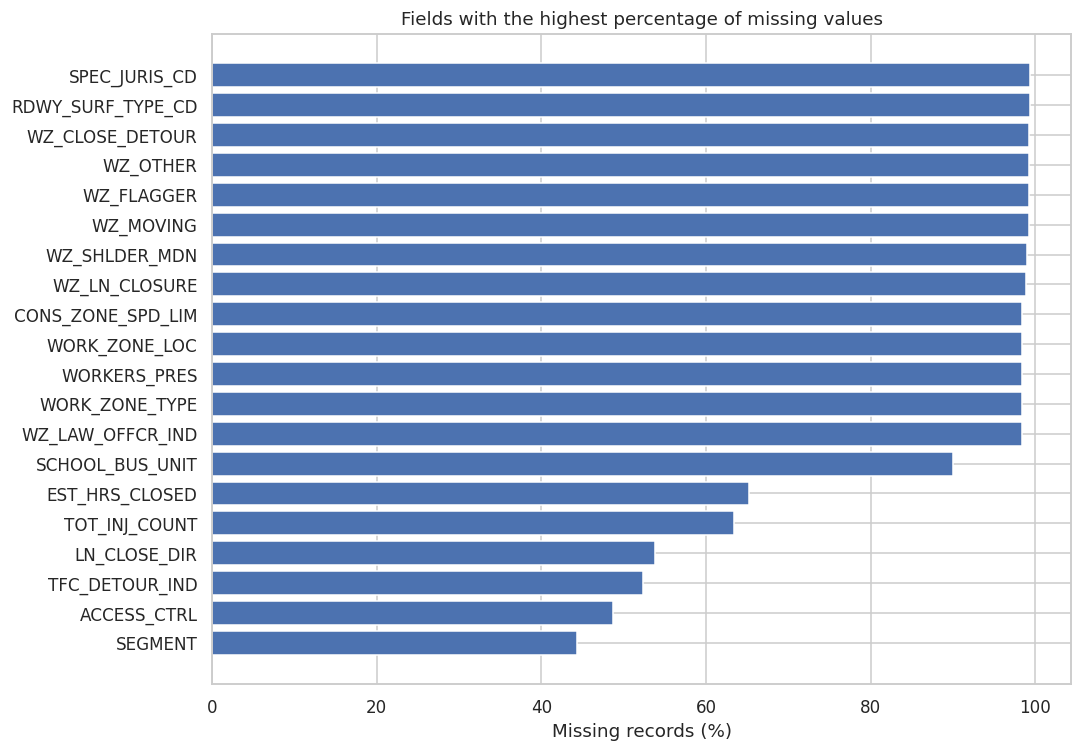

In [49]:
# Missingness is measured on the original fields; no imputation is performed for descriptive EDA.
missing_summary = pd.DataFrame({
    "missing_count": data.isna().sum(),
    "missing_percent": data.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

display(missing_summary.head(30).round(2))

top_missing = missing_summary.head(20).sort_values("missing_percent")
plt.figure(figsize=(10, 7))
plt.barh(top_missing.index, top_missing["missing_percent"])
plt.xlabel("Missing records (%)")
plt.title("Fields with the highest percentage of missing values")
plt.tight_layout()
plt.show()

### What this code does — checking whether missingness changes by year

The list selects important fields for which we want to inspect missing values. The `groupby("CRASH_YEAR")` operation then calculates the percentage missing in each selected field separately for every year.

The heatmap places years along one axis and fields along the other. Each cell represents the percentage of records in that year for which that field is missing. This can reveal changes in data collection or reporting over time; it cannot, by itself, prove the reason for those changes.

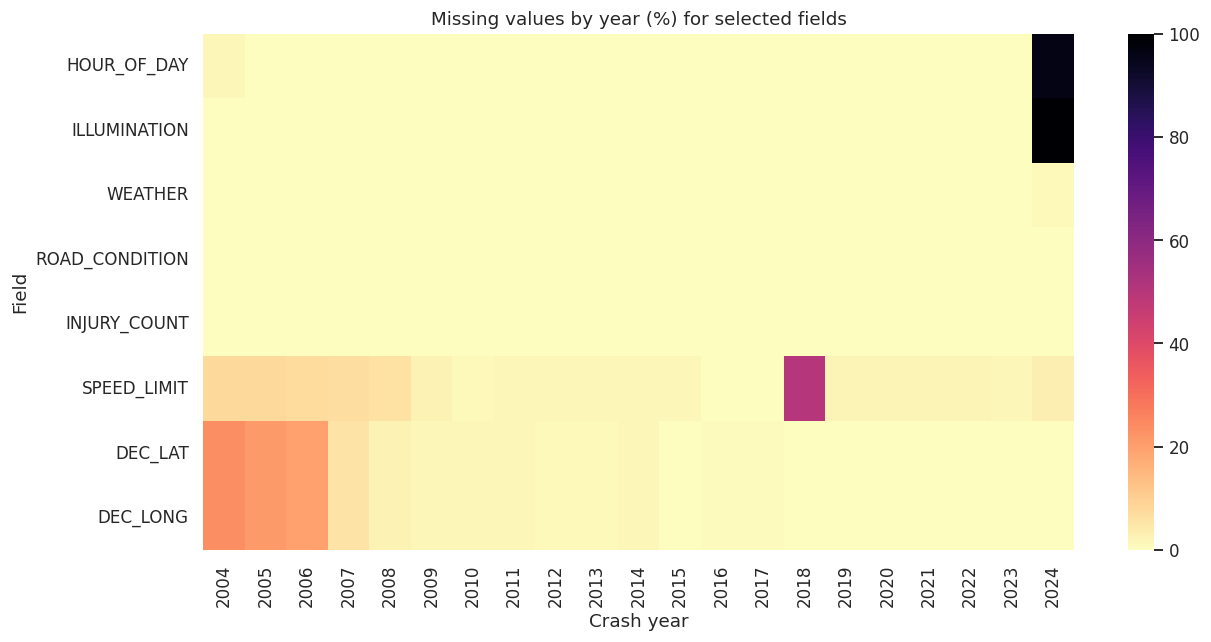

The heatmap shows when information is unavailable; it does not by itself explain why.


In [50]:
fields_to_check = [
    col for col in [
        "HOUR_OF_DAY", "ILLUMINATION", "WEATHER", "ROAD_CONDITION",
        "INJURY_COUNT", "SPEED_LIMIT", "DEC_LAT", "DEC_LONG"
    ] if col in data.columns
]

missing_by_year = data.groupby("CRASH_YEAR")[fields_to_check].apply(
    lambda frame: frame.isna().mean() * 100
)

plt.figure(figsize=(12, 6))
sns.heatmap(missing_by_year.T, cmap="magma_r", vmin=0, vmax=100)
plt.title("Missing values by year (%) for selected fields")
plt.xlabel("Crash year")
plt.ylabel("Field")
plt.tight_layout()
plt.show()

print("The heatmap shows when information is unavailable; it does not by itself explain why.")

### 5.1. Co-missingness across key fields

This check compares binary missing/not-missing indicators for selected source fields. It identifies fields whose missing values tend to occur together; it does not measure correlation between the underlying crash characteristics.

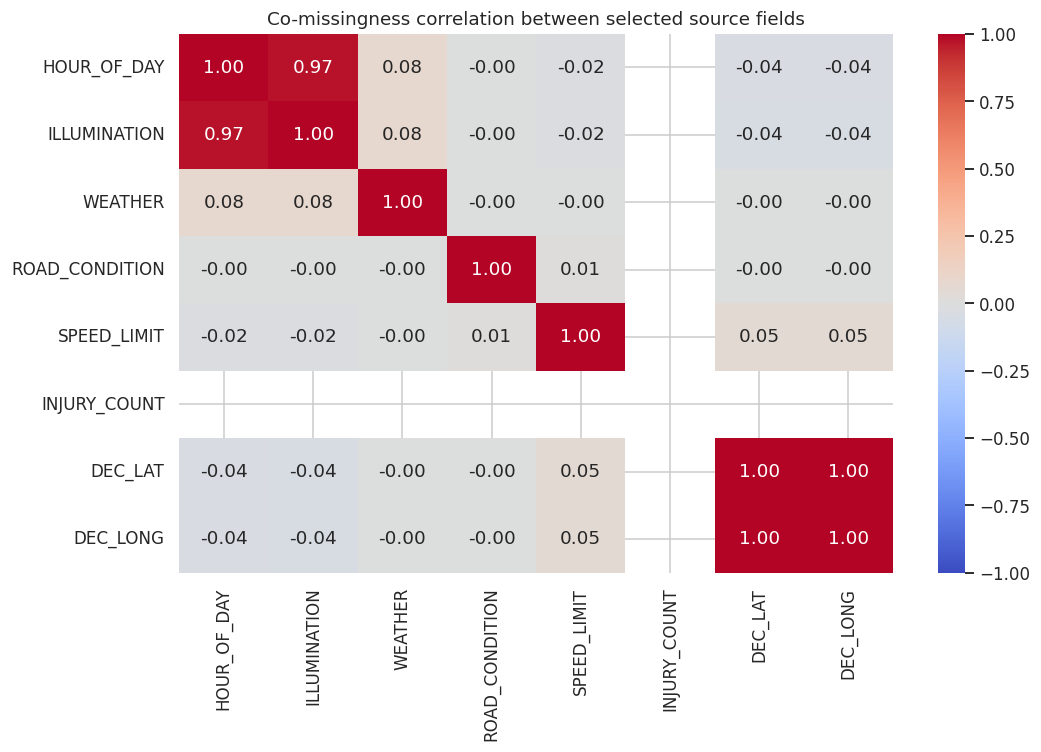

Crash records by number of selected fields missing:


,crash_records
0,216378
1,12380
2,18457
3,1577
4,15
5,3


In [51]:
# Compare missingness indicators to detect fields that become unavailable together.
co_missing_columns = [
    col for col in [
        "HOUR_OF_DAY", "ILLUMINATION", "WEATHER", "ROAD_CONDITION",
        "SPEED_LIMIT", "INJURY_COUNT", "DEC_LAT", "DEC_LONG"
    ] if col in data.columns
]

if len(co_missing_columns) >= 2:
    missing_indicators = data[co_missing_columns].isna().astype(int)
    co_missing_correlation = missing_indicators.corr(method="pearson")
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        co_missing_correlation, annot=True, fmt=".2f",
        cmap="coolwarm", vmin=-1, vmax=1
    )
    plt.title("Co-missingness correlation between selected source fields")
    plt.tight_layout()
    plt.show()

    row_missing_count = missing_indicators.sum(axis=1).value_counts().sort_index()
    print("Crash records by number of selected fields missing:")
    display(row_missing_count.rename("crash_records").to_frame())
else:
    print("Fewer than two selected fields are available for a co-missingness comparison.")

**Coverage rule for later sections.** Every conditional severity percentage uses a denominator of **known-severity crashes**; spatial percentages distinguish *all located crashes* from *located crashes with known severity*. Site-frequency estimates require a complete exposed site-year panel, including zero-crash sites. The original missingness tables above remain the source-of-truth for field-specific limitations.

## 6. Duplicates, consistency and source-quality gates

We check exact duplicate rows and repeated crash IDs separately. Exact duplicate rows can be removed from the working copy; repeated crash IDs are flagged for investigation rather than automatically deleted.

For historical weather and road-condition codes, we create broad groups using the year-specific code mappings already used in the project. These groups make broad comparisons easier, but they deliberately do not claim that every individual code is identical across reporting eras.

### What this code does — checking duplicates and creating the working copy

`data.duplicated()` identifies rows that are exact copies of earlier rows. The separate `CRASH_CRN` check counts repeated crash identifiers; repeated IDs are not automatically deleted because they may need investigation.

The code then creates `df`, the working copy used in later analysis, after removing only exact duplicate rows. The original `data` remains unchanged, so we can still refer back to the imported dataset.

In [52]:
# Exact duplicate rows and repeated IDs are different checks; repeated IDs need investigation.
exact_duplicates = int(data.duplicated().sum())
duplicate_crash_ids = int(data["CRASH_CRN"].duplicated().sum())

print("Exact duplicate rows:", exact_duplicates)
print("Repeated crash IDs:", duplicate_crash_ids)

# Remove only fully identical rows, and keep the count visible.
df = data.drop_duplicates().copy()
print(f"Working dataset: {len(df):,} rows (removed {len(data) - len(df):,} exact duplicates)")

Exact duplicate rows: 0
Repeated crash IDs: 0
Working dataset: 248,810 rows (removed 0 exact duplicates)


In [53]:
# Check injuries and fatalities against component fields without assigning missing values to zero.
# Compare sums only where all required component fields are present in that row.
injury_components = ["MAJ_INJ_COUNT", "MOD_INJ_COUNT", "MIN_INJ_COUNT", "UNK_INJ_DEG_COUNT"]
injury_year = pd.to_numeric(df["CRASH_YEAR"], errors="coerce")
check_frames = []
for parent, parts in [("INJURY_COUNT", injury_components),
                      ("TOT_INJ_COUNT", injury_components)]:
    available = [c for c in [parent] + parts if c in df]
    if len(available) != len(parts) + 1:
        print(f"{parent}: cannot reconcile; missing source columns {sorted(set([parent]+parts)-set(available))}")
        continue
    vals = df[available].apply(pd.to_numeric, errors="coerce")
    comparable = vals.notna().all(axis=1)
    difference = vals[parent] - vals[parts].sum(axis=1, min_count=len(parts))
    check_frames.append(pd.DataFrame({
        "year": injury_year, "comparison": parent + " vs component sum",
        "comparable": comparable,
        "mismatch": comparable & difference.ne(0),
        "absolute_difference": difference.abs().where(comparable)
    }))
# Fatalities by road-user category are subsets of FATAL_COUNT and must NOT be added
# together as if they partitioned all deaths (they can overlap or omit other users).
for parent, upper in [("INJURY_COUNT", "PERSON_COUNT"),
                      ("FATAL_COUNT", "PERSON_COUNT")]:
    if parent in df and upper in df:
        x = pd.to_numeric(df[parent], errors="coerce")
        y = pd.to_numeric(df[upper], errors="coerce")
        valid = x.notna() & y.notna()
        check_frames.append(pd.DataFrame({
            "year": injury_year, "comparison": f"{parent} > {upper} (logical flag)",
            "comparable": valid, "mismatch": valid & x.gt(y),
            "absolute_difference": (x - y).clip(lower=0).where(valid)
        }))
if check_frames:
    injury_audit_rows = pd.concat(check_frames, ignore_index=True)
    injury_audit = injury_audit_rows.groupby(["comparison", "year"], dropna=False).agg(
        eligible_records=("comparable", "sum"), flagged_records=("mismatch", "sum"),
        largest_abs_difference=("absolute_difference", "max")
    ).reset_index()
    injury_audit["flag_percent_of_eligible"] = (
        100 * injury_audit["flagged_records"] / injury_audit["eligible_records"].replace(0, np.nan))
    print("Injury reconciliation and logical-consistency coverage by year:")
    display(injury_audit.round(2))
else:
    print("No injury components were jointly available for reconciliation.")


Injury reconciliation and logical-consistency coverage by year:


,comparison,year,eligible_records,flagged_records,largest_abs_difference,flag_percent_of_eligible
0,FATAL_COUNT > PERSON_COUNT (logical flag),2004,12535,0,0.0,0.00
1,FATAL_COUNT > PERSON_COUNT (logical flag),2005,12215,0,0.0,0.00
2,FATAL_COUNT > PERSON_COUNT (logical flag),2006,11747,0,0.0,0.00
3,FATAL_COUNT > PERSON_COUNT (logical flag),2007,12238,0,0.0,0.00
4,FATAL_COUNT > PERSON_COUNT (logical flag),2008,11858,0,0.0,0.00
5,FATAL_COUNT > PERSON_COUNT (logical flag),2009,11677,0,0.0,0.00
6,FATAL_COUNT > PERSON_COUNT (logical flag),2010,11320,0,0.0,0.00
7,FATAL_COUNT > PERSON_COUNT (logical flag),2011,12189,0,0.0,0.00
8,FATAL_COUNT > PERSON_COUNT (logical flag),2012,12230,0,0.0,0.00
9,FATAL_COUNT > PERSON_COUNT (logical flag),2013,11994,0,0.0,0.00


## 7. Historical code harmonisation and codebook provenance

The original grouped labels are retained for comparability **as provisional descriptive mappings**. The WPRDC data dictionary explains historical source fields, but does not, by itself, certify the original v5 assumption that weather and road-surface code meanings switch **after 2018**. This notebook therefore does **not** use these potentially mislabelled groups as model inputs until a historical PennDOT codebook review is recorded. Raw-code and unmapped-code audits are preserved below.

To authorise the grouping for inference, provide `data/reference/codebooks/historical_mapping_verification.json` recording `verified: true`, `transition_year: 2019`, and at least one authoritative `source_url` pointing to dated source codebooks. Review the *actual mappings* against the source, not just the filename; this declaration is a project-team attestation, not automatic proof.

### What this code does — converting source codes into readable categories

This is the main category-label preparation block. Many crash fields are stored as numeric codes, so the dictionaries translate those codes into readable descriptions.

- The old and new weather/road dictionaries represent the different code mappings used in different reporting periods.
- `map_by_year()` applies the appropriate mapping based on the crash year, then labels missing or unmapped entries instead of silently dropping them.
- The other dictionaries provide readable labels for severity, illumination, collision type, relation to road and intersection type.
- `add_labels()` applies each dictionary and creates a new labelled column. The original coded columns are retained.

The final part creates valid analysis versions of speed limit and hour, marking values outside the selected plausible ranges as unavailable. It also creates `SEVERE_OUTCOME`: 1 for fatal/serious injury, 0 for the selected other known severity classes, and missing for unknown severity codes. This binary variable is used later for group comparisons and the optional model.

In [54]:
WEATHER_OLD = {
    1: "Clear/no adverse", 2: "Rain", 3: "Winter precipitation",
    4: "Winter precipitation", 5: "Fog/smoke", 6: "Rain",
    7: "Winter precipitation", 8: "Other", 9: "Unknown/other"
}
WEATHER_NEW = {
    1: "Wind/blowing", 2: "Winter precipitation", 3: "Clear/no adverse",
    4: "Cloudy", 5: "Fog/smoke", 6: "Winter precipitation",
    7: "Rain", 8: "Wind/blowing", 9: "Winter precipitation",
    10: "Winter precipitation", 98: "Other", 99: "Unknown/other"
}
ROAD_OLD = {
    0: "Dry", 1: "Wet", 2: "Debris/other", 3: "Snow/ice/slush",
    4: "Snow/ice/slush", 5: "Snow/ice/slush", 6: "Snow/ice/slush",
    7: "Standing water", 8: "Other", 9: "Unknown/other"
}
ROAD_NEW = {
    1: "Dry", 2: "Snow/ice/slush", 3: "Debris/other", 4: "Debris/other",
    5: "Debris/other", 6: "Snow/ice/slush", 7: "Snow/ice/slush",
    8: "Standing water", 9: "Wet", 22: "Debris/other",
    98: "Other", 99: "Unknown/other"
}

def map_by_year(frame, column, old_codes, new_codes, new_column):
    # Convert the year and source code to numeric values before applying the historical mapping.
    years = pd.to_numeric(frame["CRASH_YEAR"], errors="coerce")
    # Translate the stored numeric code into a readable category label.
    values = pd.to_numeric(frame[column], errors="coerce")
    old_labels = values.map(old_codes)
    new_labels = values.map(new_codes)
    # Use the older codebook through 2018 and the newer codebook after 2018.
    labels = old_labels.where(years <= 2018, new_labels)
    # Keep missing source values distinct from codes that were not found in the mapping.
    frame[new_column] = labels.fillna("Unmapped code")
    frame.loc[values.isna(), new_column] = "Missing"

map_by_year(df, "WEATHER", WEATHER_OLD, WEATHER_NEW, "WEATHER_GROUP")
map_by_year(df, "ROAD_CONDITION", ROAD_OLD, ROAD_NEW, "ROAD_SURFACE_GROUP")

SEVERITY_LABELS = {
    0: "Property damage only", 1: "Fatal", 2: "Serious injury",
    3: "Minor injury", 4: "Possible injury",
    8: "Injury severity unknown", 9: "Injury status unknown"
}
ILLUMINATION_LABELS = {
    1: "Daylight", 2: "Dark: no streetlights", 3: "Dark: streetlights",
    4: "Dusk", 5: "Dawn", 6: "Dark: lighting unknown",
    8: "Other", 9: "Unknown"
}
COLLISION_LABELS = {
    0: "Noncollision", 1: "Rear-end", 2: "Head-on", 3: "Backing",
    4: "Angle", 5: "Sideswipe same direction",
    6: "Sideswipe opposite direction", 7: "Fixed object",
    8: "Pedestrian", 9: "Other/unknown", 98: "Other", 99: "Unknown"
}
RELATION_LABELS = {
    1: "On roadway", 2: "Shoulder", 3: "Median", 4: "Roadside",
    5: "Outside trafficway", 6: "Parking lane", 7: "Gore", 9: "Unknown"
}
INTERSECTION_LABELS = {
    0: "Midblock", 1: "Four-way", 2: "T intersection", 3: "Y intersection",
    4: "Traffic circle (old)", 5: "Multileg", 6: "Ramp end",
    7: "Ramp begin", 8: "Crossover", 9: "Railroad crossing",
    10: "Other", 11: "L intersection", 12: "Traffic circle",
    13: "Roundabout", 99: "Unknown"
}

def add_labels(frame, source_column, mapping, output_column):
    values = pd.to_numeric(frame[source_column], errors="coerce")
    frame[output_column] = values.map(mapping).fillna("Missing/unknown")

add_labels(df, "MAX_SEVERITY_LEVEL", SEVERITY_LABELS, "SEVERITY_LABEL")
add_labels(df, "ILLUMINATION", ILLUMINATION_LABELS, "ILLUMINATION_LABEL")
add_labels(df, "COLLISION_TYPE", COLLISION_LABELS, "COLLISION_LABEL")
add_labels(df, "RELATION_TO_ROAD", RELATION_LABELS, "ROAD_RELATION_LABEL")
add_labels(df, "INTERSECT_TYPE", INTERSECTION_LABELS, "INTERSECTION_LABEL")

# Treat special/invalid values as unavailable instead of treating them as real measurements.
df["SPEED_LIMIT_VALID"] = pd.to_numeric(df["SPEED_LIMIT"], errors="coerce").where(
    lambda values: values.between(5, 85)
)
df["HOUR_VALID"] = pd.to_numeric(df["HOUR_OF_DAY"], errors="coerce").where(
    lambda values: values.between(0, 23)
)

# Only severity classes 0–4 are used for the binary outcome.
severity_code = pd.to_numeric(df["MAX_SEVERITY_LEVEL"], errors="coerce")
df["SEVERE_OUTCOME"] = np.where(
    severity_code.isin([1, 2]), 1,
    np.where(severity_code.isin([0, 3, 4]), 0, np.nan)
)

print("Working rows:", len(df))
print("Missing values in original source columns remain:", int(df[data.columns].isna().sum().sum()))
print("New analysis fields:", ["WEATHER_GROUP", "ROAD_SURFACE_GROUP", "SEVERITY_LABEL",
                               "SPEED_LIMIT_VALID", "HOUR_VALID", "SEVERE_OUTCOME"])

# A documented/manual source-codebook review is required before using groups in models.
CODEBOOK_VERIFIED = False
codebook_manifest = REFERENCE_ROOT / "codebooks" / "historical_mapping_verification.json"
if codebook_manifest.is_file():
    try:
        evidence = json.loads(codebook_manifest.read_text(encoding="utf-8"))
        urls = evidence.get("source_urls", [])
        CODEBOOK_VERIFIED = (evidence.get("verified") is True
                             and evidence.get("transition_year") == 2019
                             and isinstance(urls, list) and len(urls) >= 1
                             and all(str(u).startswith("https://") for u in urls))
    except (ValueError, OSError, TypeError) as error:
        warnings.warn(f"Could not parse codebook verification declaration: {error}")
print("Historical mapping verification:", "team-attested" if CODEBOOK_VERIFIED else "UNVERIFIED; groups excluded from inferential models")


Working rows: 248810
Missing values in original source columns remain: 4793642
New analysis fields: ['WEATHER_GROUP', 'ROAD_SURFACE_GROUP', 'SEVERITY_LABEL', 'SPEED_LIMIT_VALID', 'HOUR_VALID', 'SEVERE_OUTCOME']
Historical mapping verification: UNVERIFIED; groups excluded from inferential models


### 7.1 Historical source-code audit

The year-aware weather and road-surface mappings already used above are retained. This audit reports source codes that are not covered by the selected historical mapping and displays the raw `URBAN_RURAL` codes by year. Unmapped codes are surfaced for verification; they are not assigned invented meanings.

In [55]:
# Audit source-code coverage without changing the existing category mappings.

year_numeric = pd.to_numeric(df["CRASH_YEAR"], errors="coerce")
mapping_specs = [
    ("WEATHER", WEATHER_OLD, WEATHER_NEW),
    ("ROAD_CONDITION", ROAD_OLD, ROAD_NEW),
]
static_mapping_specs = [
    ("MAX_SEVERITY_LEVEL", SEVERITY_LABELS),
    ("ILLUMINATION", ILLUMINATION_LABELS),
    ("COLLISION_TYPE", COLLISION_LABELS),
    ("RELATION_TO_ROAD", RELATION_LABELS),
    ("INTERSECT_TYPE", INTERSECTION_LABELS),
]

unmapped_rows = []
for column, old_mapping, new_mapping in mapping_specs:
    if column not in df.columns:
        continue
    source_values = pd.to_numeric(df[column], errors="coerce")
    for year in sorted(year_numeric.dropna().unique()):
        year_mask = year_numeric.eq(year)
        year_values = source_values.loc[year_mask].dropna()
        active_mapping = old_mapping if year <= 2018 else new_mapping
        unmapped = year_values.loc[~year_values.isin(active_mapping.keys())]
        for code_value, count in unmapped.value_counts().items():
            unmapped_rows.append({
                "field": column,
                "year": int(year),
                "unmapped_source_code": code_value,
                "records": int(count)
            })

for column, mapping in static_mapping_specs:
    if column not in df.columns:
        continue
    source_values = pd.to_numeric(df[column], errors="coerce")
    unmapped = source_values.dropna().loc[~source_values.dropna().isin(mapping.keys())]
    for code_value, count in unmapped.value_counts().items():
        unmapped_rows.append({
            "field": column,
            "year": "all years",
            "unmapped_source_code": code_value,
            "records": int(count)
        })

unmapped_audit = pd.DataFrame(
    unmapped_rows,
    columns=["field", "year", "unmapped_source_code", "records"]
)
if len(unmapped_audit):
    display(unmapped_audit.sort_values(["field", "records"], ascending=[True, False]))
else:
    print("No unmapped non-missing source codes were found in the audited fields.")

if "URBAN_RURAL" in df.columns:
    urban_code_audit = pd.crosstab(
        year_numeric,
        df["URBAN_RURAL"].astype("string").fillna("Missing"),
        margins=False
    )
    urban_code_audit.index.name = "CRASH_YEAR"
    print("Raw URBAN_RURAL code counts by year (labels are intentionally not inferred):")
    display(urban_code_audit)


,field,year,unmapped_source_code,records
0,ROAD_CONDITION,2019,0.0,1


Raw URBAN_RURAL code counts by year (labels are intentionally not inferred):


URBAN_RURAL,1,2,3,4
CRASH_YEAR,,,,
2004,311,0,12224,0
2005,289,0,11926,0
2006,289,0,11458,0
2007,306,0,11932,0
2008,319,0,11539,0
2009,322,0,11355,0
2010,322,0,10998,0
2011,305,0,11884,0
2012,325,0,11905,0


## 8. Cleaning and feature engineering

The earlier mapping cell already builds `SPEED_LIMIT_VALID`, `HOUR_VALID` and the **known-severity-only** binary target. This section completes time bands, sentinel handling and vulnerable-road-user indicators; missing outcomes remain missing. No source rows are deleted because of plausible high injury/vehicle counts.

### What this code does — creating and analysing time-of-day groups

The function `time_period()` converts a valid hour into one of four understandable time bands: morning, afternoon, evening or night. Missing hours are explicitly labelled as missing.

Applying the function creates a new `TIME_PERIOD` column in the working dataset. The first table counts records in each time band. The second uses the same severity-rate function from the earlier section to compare serious/fatal shares across the time bands, while also reporting each group's sample size.

In [56]:
# Define the already-used v5 group-rate helper before time-band creation (the v5 cell
# that later draws grouped comparisons redefines the same function unchanged).
def severity_rate_table(frame, group_column, minimum_n=100):
    valid = frame[[group_column, "SEVERE_OUTCOME"]].dropna()
    result = valid.groupby(group_column)["SEVERE_OUTCOME"].agg(
        crashes="size", serious_or_fatal="sum", severe_share="mean")
    result["severe_percent"] = result["severe_share"] * 100
    return result[result["crashes"] >= minimum_n].sort_values(
        "severe_percent", ascending=False)


In [57]:
def time_period(hour):
    # Keep missing hours visible instead of assigning them to a time band.
    if pd.isna(hour):
        return "Missing"
    # Assign each valid hour to one descriptive part of the day.
    if 5 <= hour < 12:
        return "Morning"
    if 12 <= hour < 17:
        return "Afternoon"
    if 17 <= hour < 21:
        return "Evening"
    return "Night"

df["TIME_PERIOD"] = df["HOUR_VALID"].apply(time_period)

print("Crash records by derived time period:")
display(df["TIME_PERIOD"].value_counts().to_frame("crash_records"))

time_severity = severity_rate_table(df, "TIME_PERIOD", minimum_n=100)
display(time_severity[["crashes", "serious_or_fatal", "severe_percent"]].round(2))

# A 9999 or non-hour TIME_OF_DAY value is not a midnight event. It is retained
# as a source sentinel, while time bands use only the validated 0–23 hour.
if "TIME_OF_DAY" in df:
    raw_time = pd.to_numeric(df["TIME_OF_DAY"], errors="coerce")
    df["TIME_SENTINEL_FLAG"] = raw_time.isin([9999, 999, 99])
else:
    df["TIME_SENTINEL_FLAG"] = False
for count_col, flag_col in [("PED_COUNT", "PEDESTRIAN_INVOLVED"),
                            ("BICYCLE_COUNT", "BICYCLIST_INVOLVED"),
                            ("MOTORCYCLE_COUNT", "MOTORCYCLIST_INVOLVED")]:
    source_count = pd.to_numeric(df[count_col], errors="coerce") if count_col in df else pd.Series(np.nan, index=df.index)
    # Nullable Int64 preserves unknown road-user presence where the source count is absent.
    df[flag_col] = source_count.gt(0).where(source_count.notna()).astype("Int64")
print("Derived time/road-user fields: TIME_PERIOD, TIME_SENTINEL_FLAG, PEDESTRIAN_INVOLVED, BICYCLIST_INVOLVED, MOTORCYCLIST_INVOLVED")


Crash records by derived time period:


,crash_records
TIME_PERIOD,
Afternoon,71268
Morning,62788
Night,51092
Evening,49893
Missing,13769


,crashes,serious_or_fatal,severe_percent
TIME_PERIOD,,,
Night,41881,2088.0,4.99
Missing,11450,445.0,3.89
Evening,41666,1454.0,3.49
Afternoon,58657,1708.0,2.91
Morning,51890,1357.0,2.62


Derived time/road-user fields: TIME_PERIOD, TIME_SENTINEL_FLAG, PEDESTRIAN_INVOLVED, BICYCLIST_INVOLVED, MOTORCYCLIST_INVOLVED


## 9. Univariate severity and temporal EDA

We begin with the distribution of the recorded severity classes. Unknown severity categories are shown rather than silently removed.

### What this code does — showing the distribution of crash severity

`value_counts()` counts the number of records in each readable severity category. The horizontal bar chart displays these counts so categories with larger numbers of recorded crashes are easy to compare.

The table below the chart gives the exact counts. Unknown severity categories remain included, so the chart represents the recorded severity labels rather than only a filtered subset.

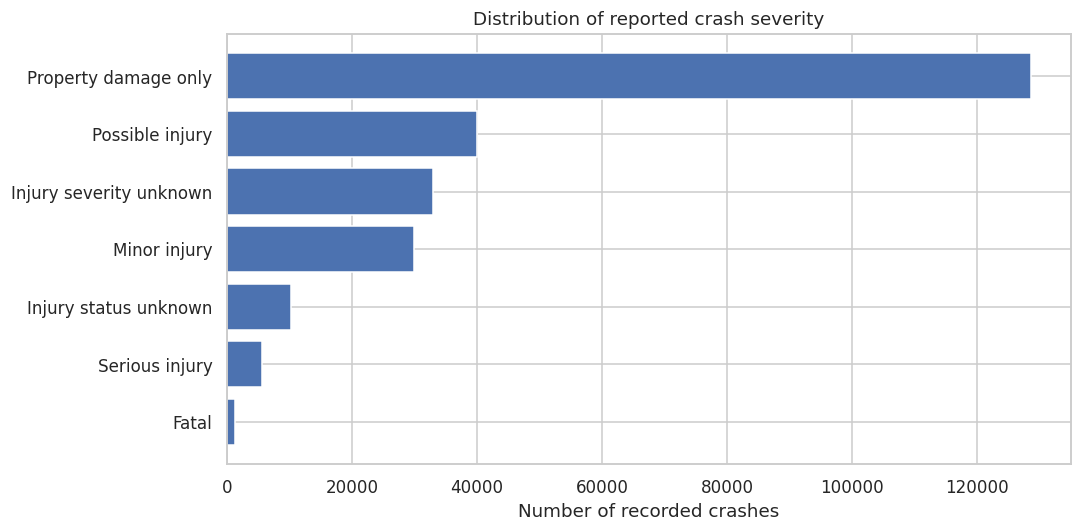

,crash_records
SEVERITY_LABEL,
Property damage only,128621
Possible injury,39979
Injury severity unknown,32946
Minor injury,29892
Injury status unknown,10320
Serious injury,5656
Fatal,1396


In [58]:
severity_counts = df["SEVERITY_LABEL"].value_counts()
plt.figure(figsize=(10, 5))
plt.barh(severity_counts.index[::-1], severity_counts.values[::-1])
plt.xlabel("Number of recorded crashes")
plt.title("Distribution of reported crash severity")
plt.tight_layout()
plt.show()
display(severity_counts.rename("crash_records").to_frame())

### 9.1 Crash counts by year, month, weekday and recorded hour

The first chart compares annual crash-record counts. The remaining charts look at month, day of week, and hour of day.

These are counts of reported crashes, not rates. Differences can reflect changes in travel exposure, reporting practices, and the COVID-19 period as well as changes in crash occurrence.

### What this code does — exploring when crashes are recorded

This cell creates four charts in one figure:

1. Annual counts: `groupby("CRASH_YEAR").size()` counts records for each year, and the line plot shows how the count changes over time.
2. Monthly counts: `value_counts()` counts records for each month, sorted into calendar order.
3. Day-of-week counts: counts each recorded day code. The x-axis deliberately says “code” because this plot does not assume the code numbering itself is a weekday name.
4. Hourly counts: counts records for each valid hour from 0 to 23.

The final print statement reports how many records have a valid hour. All four charts show record counts, not exposure-adjusted crash rates.

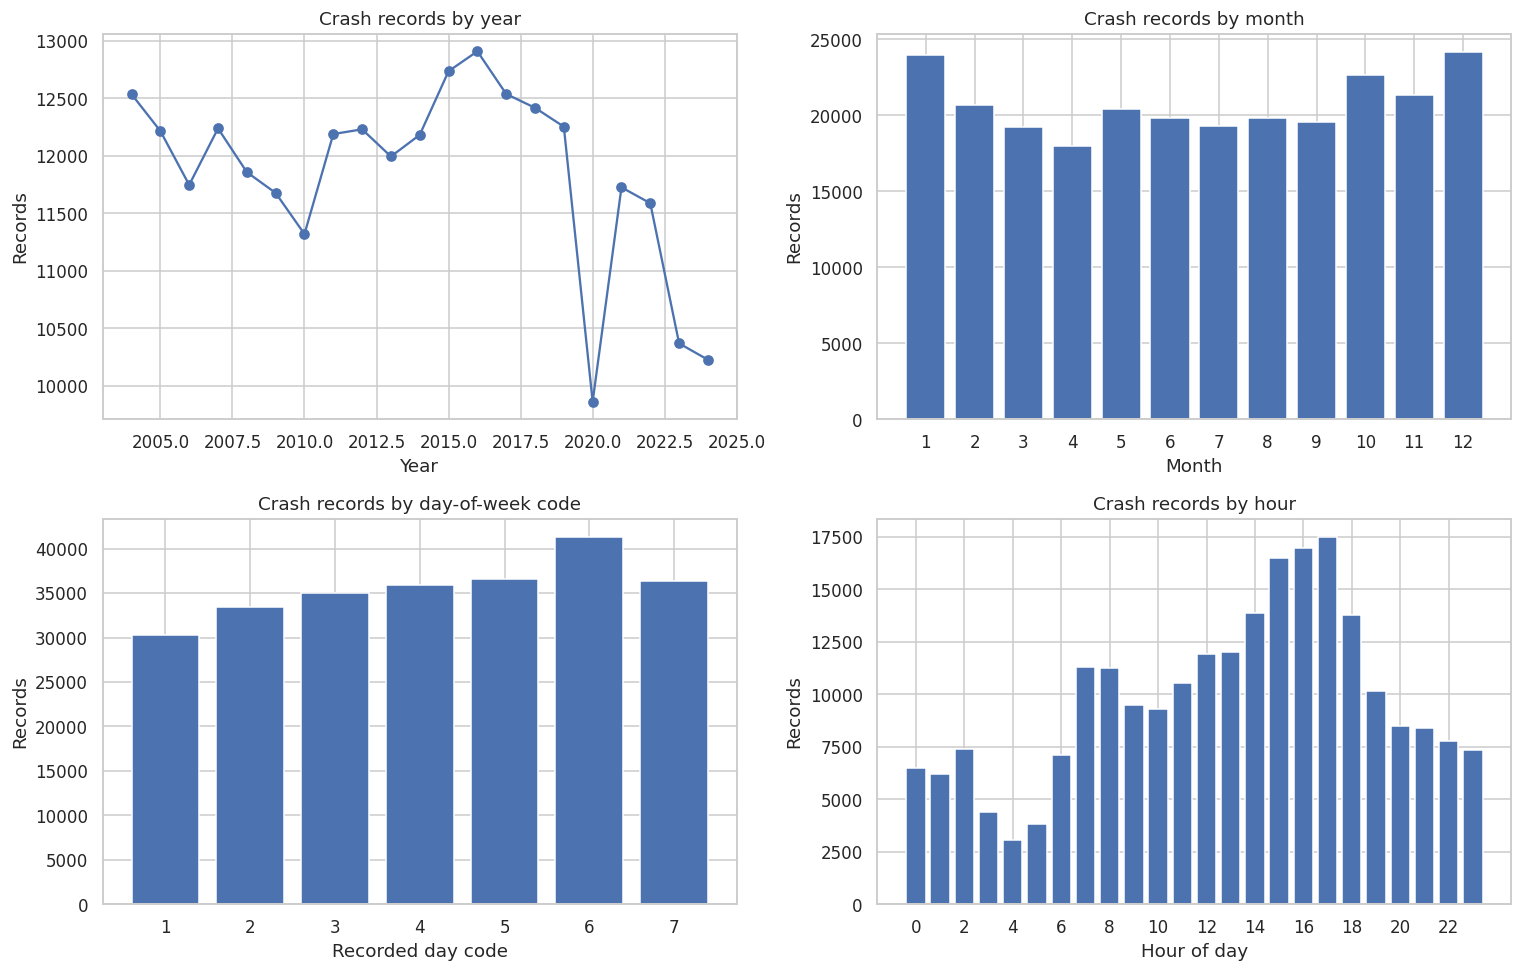

Valid recorded hours: 235041 of 248810


In [59]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

annual_counts = df.groupby("CRASH_YEAR").size()
axes[0, 0].plot(annual_counts.index, annual_counts.values, marker="o")
axes[0, 0].set(title="Crash records by year", xlabel="Year", ylabel="Records")

month_counts = df["CRASH_MONTH"].value_counts().sort_index()
axes[0, 1].bar(month_counts.index, month_counts.values)
axes[0, 1].set(title="Crash records by month", xlabel="Month", ylabel="Records",
               xticks=range(1, 13))

weekday_counts = df["DAY_OF_WEEK"].value_counts().sort_index()
axes[1, 0].bar(weekday_counts.index.astype(str), weekday_counts.values)
axes[1, 0].set(title="Crash records by day-of-week code", xlabel="Recorded day code",
               ylabel="Records")

hour_counts = df["HOUR_VALID"].value_counts().sort_index()
axes[1, 1].bar(hour_counts.index, hour_counts.values)
axes[1, 1].set(title="Crash records by hour", xlabel="Hour of day", ylabel="Records",
               xticks=range(0, 24, 2))

plt.tight_layout()
plt.show()
print("Valid recorded hours:", int(df["HOUR_VALID"].notna().sum()), "of", len(df))

### 9.2 Historical severity break and time recording diagnostics

PennDOT adopted the federal injury-severity reporting standard on **1 January 2016**. PennDOT cautions that serious, minor, and possible injury categories are not directly comparable before and after that date. This section therefore displays the full annual code composition, a fatal-only long-run trend, and the serious/fatal trend within 2016–2024. It also investigates the 02:00 hour spike without automatically deleting or reclassifying records.

Source: [PennDOT 2016 Crash Facts and Statistics](https://www.penndot.pa.gov/TravelInPA/Safety/Documents/2016_CFB_linked.pdf).

Annual severity coverage, fatal share, and post-2016 serious/fatal share (pre-2016 serious/fatal percentages are intentionally blank):


,crash_records,known_severity_records,fatal_records,serious_fatal_records,known_severity_percent,fatal_percent_of_known,serious_fatal_percent_of_known
CRASH_YEAR,,,,,,,
2004,12535,10885,69,305,86.84,0.63,NaN
2005,12215,10378,99,320,84.96,0.95,NaN
2006,11747,9720,70,299,82.74,0.72,NaN
2007,12238,10104,74,322,82.56,0.73,NaN
2008,11858,9733,70,290,82.08,0.72,NaN
2009,11677,9542,58,275,81.72,0.61,NaN
2010,11320,9198,64,278,81.25,0.70,NaN
2011,12189,9900,57,234,81.22,0.58,NaN
2012,12230,9866,64,324,80.67,0.65,NaN


Known-severity composition by year (%):


SEVERITY_CODE,0,1,2,3,4
CRASH_YEAR,,,,,
2004,54.23,0.63,2.17,11.90,31.07
2005,56.48,0.95,2.13,11.26,29.17
2006,57.04,0.72,2.36,10.45,29.43
2007,59.37,0.73,2.45,10.48,26.96
2008,61.27,0.72,2.26,9.84,25.91
2009,60.22,0.61,2.27,9.75,27.15
2010,59.94,0.70,2.33,10.14,26.90
2011,62.27,0.58,1.79,9.80,25.57
2012,62.43,0.65,2.64,9.63,24.66


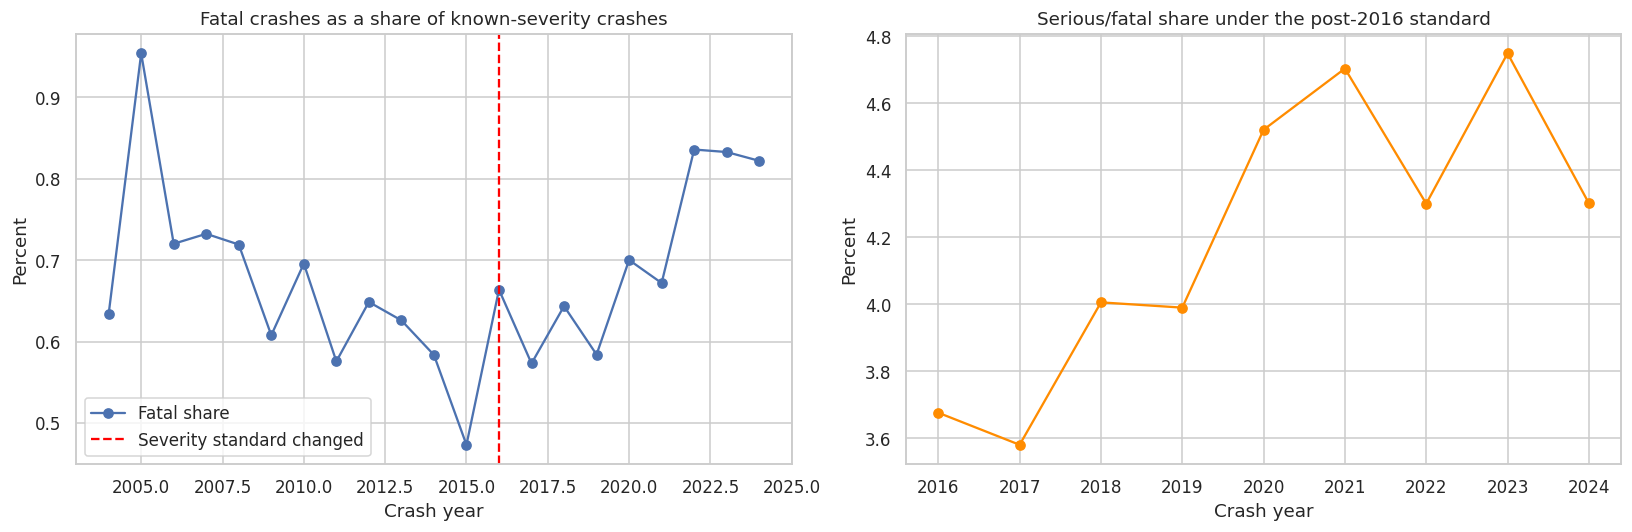

02:00 records by year:


,valid_hour_records,records_at_0200,percent_at_0200_of_valid_hours
CRASH_YEAR,,,
2004,12200,408,3.34
2005,11801,446,3.78
2006,11391,417,3.66
2007,11828,431,3.64
2008,11518,403,3.50
2009,11415,376,3.29
2010,11094,378,3.41
2011,11964,382,3.19
2012,12034,410,3.41


Most frequent raw TIME_OF_DAY values (inspect format and round-time concentrations):


,records
TIME_OF_DAY,
NaN,9988
9999.0,3781
1600.0,933
1700.0,916
1500.0,871
1800.0,857
1730.0,841
1630.0,809
1530.0,777


In [60]:
# Recalculate severity trends directly from the original severity codes.
severity_numeric = pd.to_numeric(df["MAX_SEVERITY_LEVEL"], errors="coerce")
crash_year_numeric = pd.to_numeric(df["CRASH_YEAR"], errors="coerce")
known_severity_mask = severity_numeric.isin([0, 1, 2, 3, 4])
trend_frame = pd.DataFrame({
    "CRASH_YEAR": crash_year_numeric,
    "SEVERITY_CODE": severity_numeric,
    "KNOWN_SEVERITY": known_severity_mask.astype(int),
    "FATAL_FLAG": severity_numeric.eq(1).astype(int),
    "SERIOUS_FATAL_FLAG": severity_numeric.isin([1, 2]).astype(int)
}).dropna(subset=["CRASH_YEAR"])

annual_severity = trend_frame.groupby("CRASH_YEAR").agg(
    crash_records=("SEVERITY_CODE", "size"),
    known_severity_records=("KNOWN_SEVERITY", "sum"),
    fatal_records=("FATAL_FLAG", "sum"),
    serious_fatal_records=("SERIOUS_FATAL_FLAG", "sum")
)
annual_severity["known_severity_percent"] = (
    100 * annual_severity["known_severity_records"] / annual_severity["crash_records"]
)
annual_severity["fatal_percent_of_known"] = (
    100 * annual_severity["fatal_records"] / annual_severity["known_severity_records"].replace(0, np.nan)
)
annual_severity["serious_fatal_percent_of_known"] = (
    100 * annual_severity["serious_fatal_records"]
    / annual_severity["known_severity_records"].replace(0, np.nan)
)
annual_severity.loc[annual_severity.index < 2016, "serious_fatal_percent_of_known"] = np.nan
print("Annual severity coverage, fatal share, and post-2016 serious/fatal share (pre-2016 serious/fatal percentages are intentionally blank):")
display(annual_severity.round(2))

severity_composition = pd.crosstab(
    trend_frame.loc[known_severity_mask.reindex(trend_frame.index, fill_value=False), "CRASH_YEAR"],
    trend_frame.loc[known_severity_mask.reindex(trend_frame.index, fill_value=False), "SEVERITY_CODE"],
    normalize="index"
) * 100
severity_composition = severity_composition.reindex(columns=[0, 1, 2, 3, 4], fill_value=0)
print("Known-severity composition by year (%):")
display(severity_composition.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(annual_severity.index, annual_severity["fatal_percent_of_known"],
             marker="o", label="Fatal share")
axes[0].axvline(2016, color="red", linestyle="--", label="Severity standard changed")
axes[0].set(title="Fatal crashes as a share of known-severity crashes",
            xlabel="Crash year", ylabel="Percent")
axes[0].legend()
post_2016 = annual_severity.loc[annual_severity.index >= 2016]
axes[1].plot(post_2016.index, post_2016["serious_fatal_percent_of_known"],
             marker="o", color="darkorange")
axes[1].set(title="Serious/fatal share under the post-2016 standard",
            xlabel="Crash year", ylabel="Percent")
plt.tight_layout()
plt.show()

# Investigate the 02:00 concentration without assuming it is a data error.
hour_diagnostic = df[["CRASH_YEAR", "HOUR_VALID"]].copy()
hour_diagnostic["CRASH_YEAR"] = pd.to_numeric(hour_diagnostic["CRASH_YEAR"], errors="coerce")
hour_diagnostic["IS_0200"] = pd.to_numeric(hour_diagnostic["HOUR_VALID"], errors="coerce").eq(2)
hour_by_year = hour_diagnostic.groupby("CRASH_YEAR").agg(
    valid_hour_records=("HOUR_VALID", "count"),
    records_at_0200=("IS_0200", "sum")
)
hour_by_year["percent_at_0200_of_valid_hours"] = (
    100 * hour_by_year["records_at_0200"] / hour_by_year["valid_hour_records"].replace(0, np.nan)
)
print("02:00 records by year:")
display(hour_by_year.round(2))

if "TIME_OF_DAY" in df.columns:
    print("Most frequent raw TIME_OF_DAY values (inspect format and round-time concentrations):")
    display(df["TIME_OF_DAY"].value_counts(dropna=False).head(20).rename("records").to_frame())
else:
    print("TIME_OF_DAY is not present; the diagnostic is limited to HOUR_OF_DAY.")


**Interpretation checkpoint:** 2004–2024 annual values are numbers of **reported crashes**, not exposure-adjusted incidence. The 2016 severity-standard boundary prevents direct pooling of serious-injury trends across eras. `HOUR_VALID` coverage in **2024 is only about 4%** in v5, and illumination is absent; any v6 plot using these fields must report its own covered denominator. The raw-time heaping check above highlights that apparent 02:00 patterns may be partly reporting behaviour.

## 10. Environmental, collision and roadway EDA

We compare lighting, weather, and road-surface categories. Weather and road-surface groups use broad year-aware mappings; they remain provisional source-code groupings pending historical codebook verification, not as a perfect reconstruction of every historical codebook.

### What this code does — comparing recorded environmental conditions

The code selects three labelled fields: illumination, grouped weather and grouped road surface. For each field, `value_counts()` calculates how many crashes fall into each category; `.head(12)` keeps the most frequent categories so the chart remains readable.

The loop draws one horizontal bar chart per field. This is a descriptive comparison of how often each condition appears in the crash records, not a measure of the risk associated with that condition.

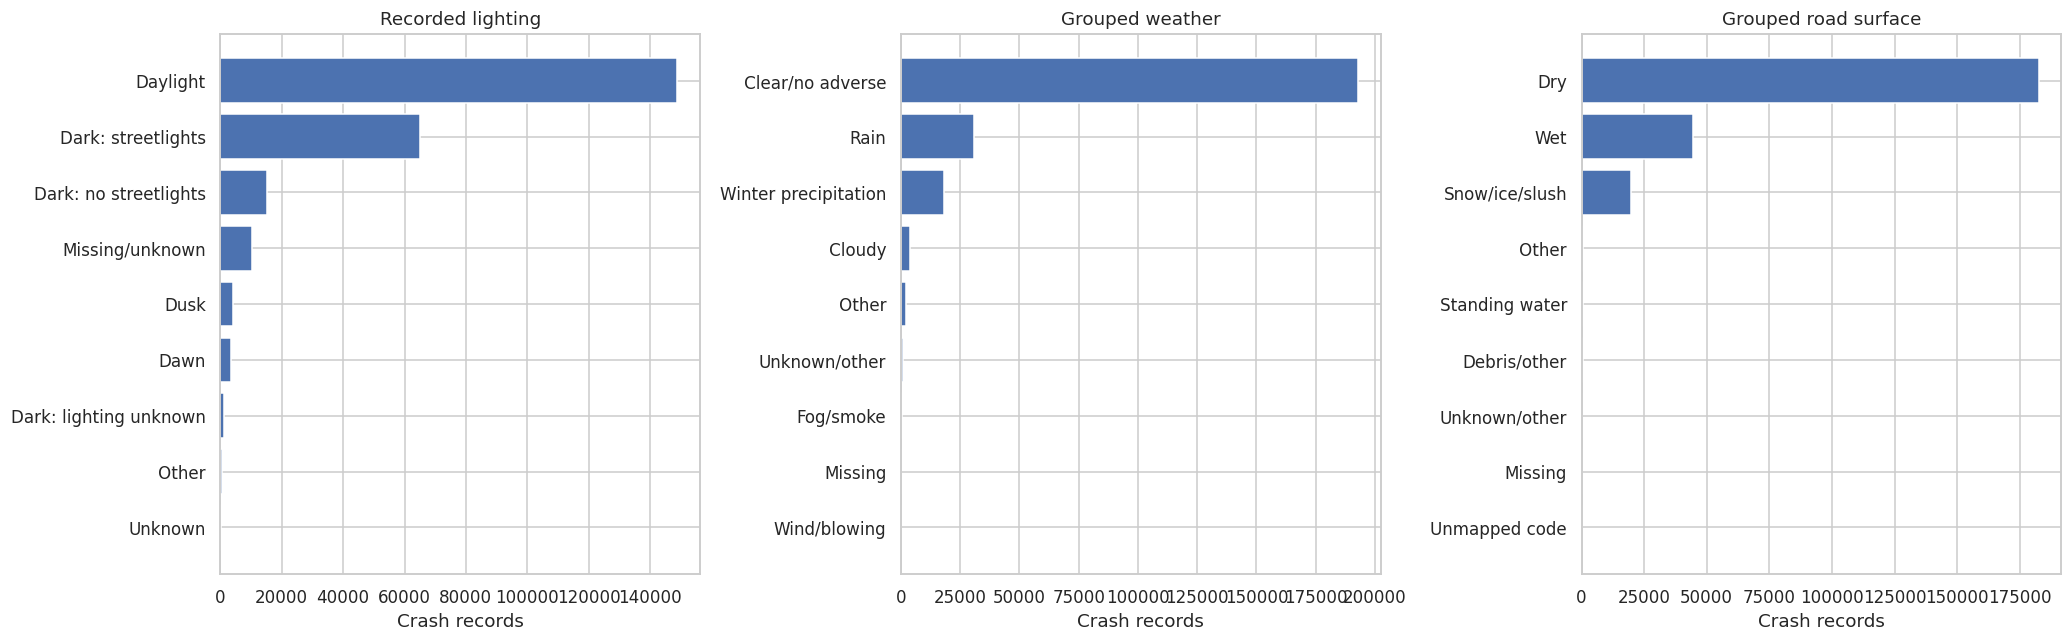

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
condition_columns = ["ILLUMINATION_LABEL", "WEATHER_GROUP", "ROAD_SURFACE_GROUP"]
condition_titles = ["Recorded lighting", "Grouped weather", "Grouped road surface"]

for ax, column, title in zip(axes, condition_columns, condition_titles):
    counts = df[column].value_counts().head(12)
    ax.barh(counts.index[::-1], counts.values[::-1])
    ax.set(title=title, xlabel="Crash records")

plt.tight_layout()
plt.show()

### 10.1 Collision and roadway context

These plots describe the most frequently recorded collision types and road/intersection contexts. The labels are based on the recorded code values; unknown or missing values remain visible.

### What this code does — examining collision and roadway context

The `context_columns` list pairs each source/labelled field with the title that should appear on its chart. The loop counts the most frequent values in each field and draws four horizontal bar charts.

These charts show the most common recorded collision types, road relationships, intersection types and urban/rural codes. The urban/rural field is displayed as its source code, so it should not be interpreted as a descriptive label unless the corresponding codebook is consulted.

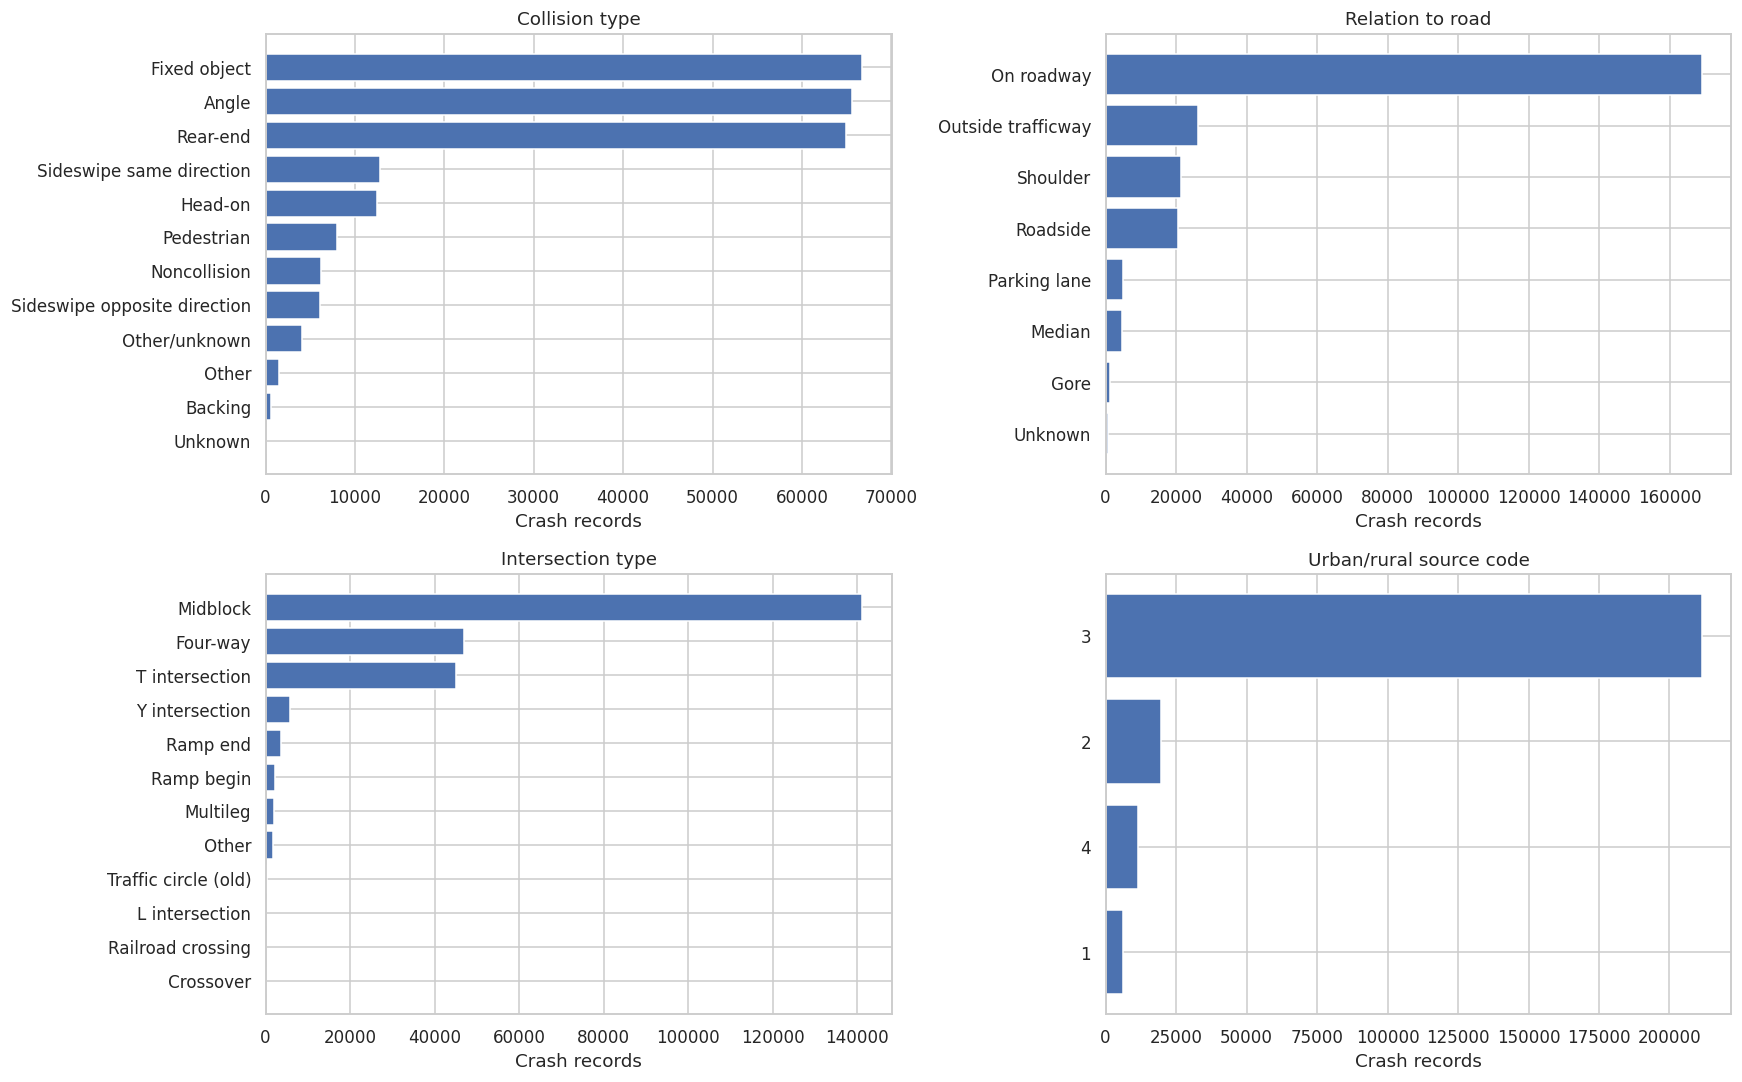

In [62]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
context_columns = [
    ("COLLISION_LABEL", "Collision type"),
    ("ROAD_RELATION_LABEL", "Relation to road"),
    ("INTERSECTION_LABEL", "Intersection type"),
    ("URBAN_RURAL", "Urban/rural source code")
]

for ax, (column, title) in zip(axes.flat, context_columns):
    counts = df[column].value_counts().head(12)
    ax.barh(counts.index.astype(str)[::-1], counts.values[::-1])
    ax.set(title=title, xlabel="Crash records")

plt.tight_layout()
plt.show()

In [63]:
# Show the available denominator of roadway context variables before comparing levels.
roadway_fields = [c for c in ["SPEED_LIMIT", "LANE_COUNT", "WORK_ZONE",
                              "EST_HRS_CLOSED", "ROUTE", "SEGMENT", "ILLUMINATION"] if c in df]
roadway_coverage = pd.DataFrame({
    "field": roadway_fields,
    "observed_records": [int(df[c].notna().sum()) for c in roadway_fields],
    "coverage_percent": [round(100 * df[c].notna().mean(), 2) for c in roadway_fields]
})
print("Roadway and lighting field availability (2024 illumination must be assessed separately):")
display(roadway_coverage)
if "ILLUMINATION" in df:
    display(df.assign(YEAR=pd.to_numeric(df["CRASH_YEAR"], errors="coerce"))
            .groupby("YEAR")["ILLUMINATION"].agg(
                source_records="size", observed_records="count"))


Roadway and lighting field availability (2024 illumination must be assessed separately):


,field,observed_records,coverage_percent
0,SPEED_LIMIT,235474,94.64
1,LANE_COUNT,233803,93.97
2,WORK_ZONE,248809,100.00
3,EST_HRS_CLOSED,86457,34.75
4,ROUTE,146488,58.88
5,SEGMENT,138584,55.70
6,ILLUMINATION,238582,95.89


,source_records,observed_records
YEAR,,
2004,12535,12535
2005,12215,12215
2006,11747,11747
2007,12238,12238
2008,11858,11858
2009,11677,11677
2010,11320,11320
2011,12189,12189
2012,12230,12230


## 11. People, vehicles and vulnerable-road-user EDA

The following summaries use crash-level counts. A crash with multiple people or vehicles contributes its recorded count to the relevant total. Missing counts are not automatically replaced by zero.

### What this code does — summarising people and injury counts

The list contains crash-level count fields such as the number of people, vehicles, injuries and fatalities. The code first keeps only columns that are present in the dataset.

For each available field, it converts values to numeric form and calculates the number of non-missing records, missing records, mean, median and maximum. These summaries describe the counts recorded for each crash. Missing values are not treated as zero.

In [64]:
count_columns = [
    "PERSON_COUNT", "VEHICLE_COUNT", "FATAL_COUNT",
    "INJURY_COUNT", "MAJ_INJ_COUNT", "PED_COUNT", "BICYCLE_COUNT"
]
available_count_columns = [col for col in count_columns if col in df.columns]

summary_rows = []
for col in available_count_columns:
    values = pd.to_numeric(df[col], errors="coerce")
    summary_rows.append({
        "variable": col,
        "non_missing_records": values.notna().sum(),
        "missing_records": values.isna().sum(),
        "mean": values.mean(),
        "median": values.median(),
        "maximum": values.max()
    })

display(pd.DataFrame(summary_rows).round(2))

,variable,non_missing_records,missing_records,mean,median,maximum
0,PERSON_COUNT,248810,0,2.40,2.0,99
1,VEHICLE_COUNT,248810,0,1.83,2.0,16
2,FATAL_COUNT,248810,0,0.01,0.0,3
3,INJURY_COUNT,248810,0,0.60,0.0,44
4,MAJ_INJ_COUNT,248810,0,0.03,0.0,7
5,PED_COUNT,248810,0,0.03,0.0,9
6,BICYCLE_COUNT,248810,0,0.01,0.0,4


### What this code does — visualising the distribution of count variables

This cell draws a separate frequency chart for each selected count variable. It first removes missing values, then counts how many crash records have each recorded value.

Very large values can make the common values difficult to see. To keep the chart readable, the code groups the upper tail (values at or above a chosen threshold based on the 99th percentile) into one final `10+`-style category. This grouping is only for display; it does not modify the dataset or remove those records.

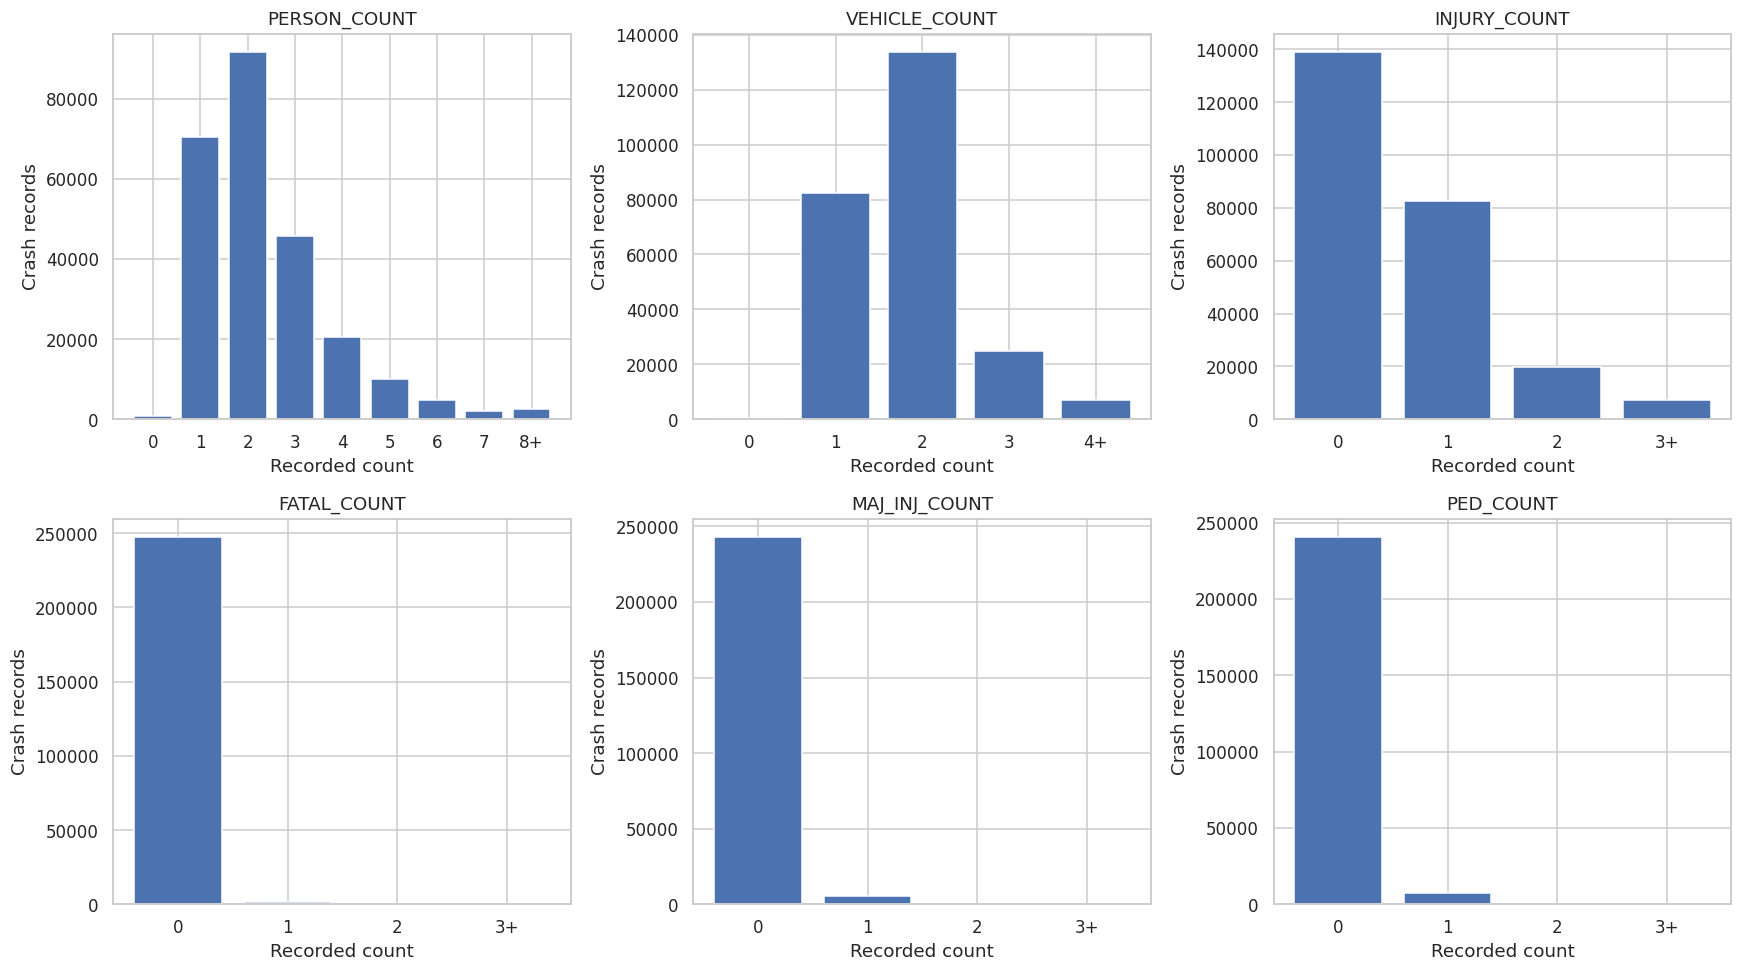

In [65]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plot_columns = ["PERSON_COUNT", "VEHICLE_COUNT", "INJURY_COUNT",
                "FATAL_COUNT", "MAJ_INJ_COUNT", "PED_COUNT"]

for ax, col in zip(axes.flat, plot_columns):
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    counts = values.value_counts().sort_index()
    # Combine the upper tail so that a few large counts do not hide the common values.
    upper = min(10, int(values.quantile(0.99))) if len(values) else 10
    upper = max(3, upper)
    displayed = counts[counts.index < upper].copy()
    displayed.loc[f"{upper}+"] = counts[counts.index >= upper].sum()
    ax.bar(displayed.index.astype(str), displayed.values)
    ax.set(title=col, xlabel="Recorded count", ylabel="Crash records")

plt.tight_layout()
plt.show()

In [66]:
# Do not interpret absent source values as zero road users.
road_user_cols = [c for c in ["PED_COUNT", "BICYCLE_COUNT", "MOTORCYCLE_COUNT",
                              "PED_DEATH_COUNT", "BICYCLE_DEATH_COUNT", "MCYCLE_DEATH_COUNT",
                              "INJURY_COUNT", "FATAL_COUNT"] if c in df]
road_user_coverage = df[road_user_cols].agg(["count", "size"]).T.rename(
    columns={"count": "nonmissing_records", "size": "total_records"})
road_user_coverage["percent_available"] = (100 * road_user_coverage["nonmissing_records"]
                                               / road_user_coverage["total_records"])
print("Vulnerable-road-user and injury field coverage:")
display(road_user_coverage.round(2))


Vulnerable-road-user and injury field coverage:


,nonmissing_records,total_records,percent_available
PED_COUNT,248810,248810,100.0
BICYCLE_COUNT,248810,248810,100.0
MOTORCYCLE_COUNT,248810,248810,100.0
PED_DEATH_COUNT,248810,248810,100.0
BICYCLE_DEATH_COUNT,248810,248810,100.0
MCYCLE_DEATH_COUNT,248810,248810,100.0
INJURY_COUNT,248810,248810,100.0
FATAL_COUNT,248810,248810,100.0


## 12. Statistical associations, uncertainty and adjusted severity

### 12.0 Descriptive IQR outlier flags

The IQR method is practised in the EDA labs. For each selected numerical variable:

- \(Q1\) is the 25th percentile and \(Q3\) is the 75th percentile.
- \(IQR = Q3 - Q1\).
- Values below \(Q1 - 1.5(IQR)\) or above \(Q3 + 1.5(IQR)\) are flagged.

A flagged value is not automatically an error. For crash data, a high number of people, vehicles, or injuries may represent a genuine unusual event. We therefore identify and describe outliers rather than deleting them automatically.

### What this code does — identifying possible outliers with the IQR rule

For each selected numerical variable, the code calculates the first quartile (Q1), third quartile (Q3), and interquartile range (IQR = Q3 − Q1). It then calculates the usual lower and upper IQR fences: Q1 − 1.5 × IQR and Q3 + 1.5 × IQR.

Values outside those fences are counted as potential outliers. The output table reports the quartiles, fences, number of flagged values and percentage flagged for each variable. The records are not deleted or capped: the rule identifies unusual observations, not necessarily data errors.

In [67]:
# IQR flags unusual observations; it is not a rule for deleting genuine crash records.
outlier_columns = ["PERSON_COUNT", "VEHICLE_COUNT", "INJURY_COUNT"]
outlier_rows = []

for col in outlier_columns:
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_count = ((values < lower) | (values > upper)).sum()

    outlier_rows.append({
        "variable": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_bound": lower, "upper_bound": upper,
        "outlier_count": outlier_count,
        "outlier_percent": 100 * outlier_count / len(values)
    })

display(pd.DataFrame(outlier_rows).round(2))

,variable,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percent
0,PERSON_COUNT,1.0,3.0,2.0,-2.0,6.0,4652,1.87
1,VEHICLE_COUNT,1.0,2.0,1.0,-0.5,3.5,7189,2.89
2,INJURY_COUNT,0.0,1.0,1.0,-1.5,2.5,7287,2.93


### What this code does — displaying the outliers with boxplots

A boxplot gives a visual summary of each selected variable. The box represents the middle 50% of values (from Q1 to Q3), the line inside it is the median, and the whiskers show the main spread under the plotting convention. Individual points beyond the whiskers are displayed as potential outliers.

The four plots let us visually compare the distributions of people, vehicles, injuries and posted speed limits. As in the previous cell, unusual crash records are retained.

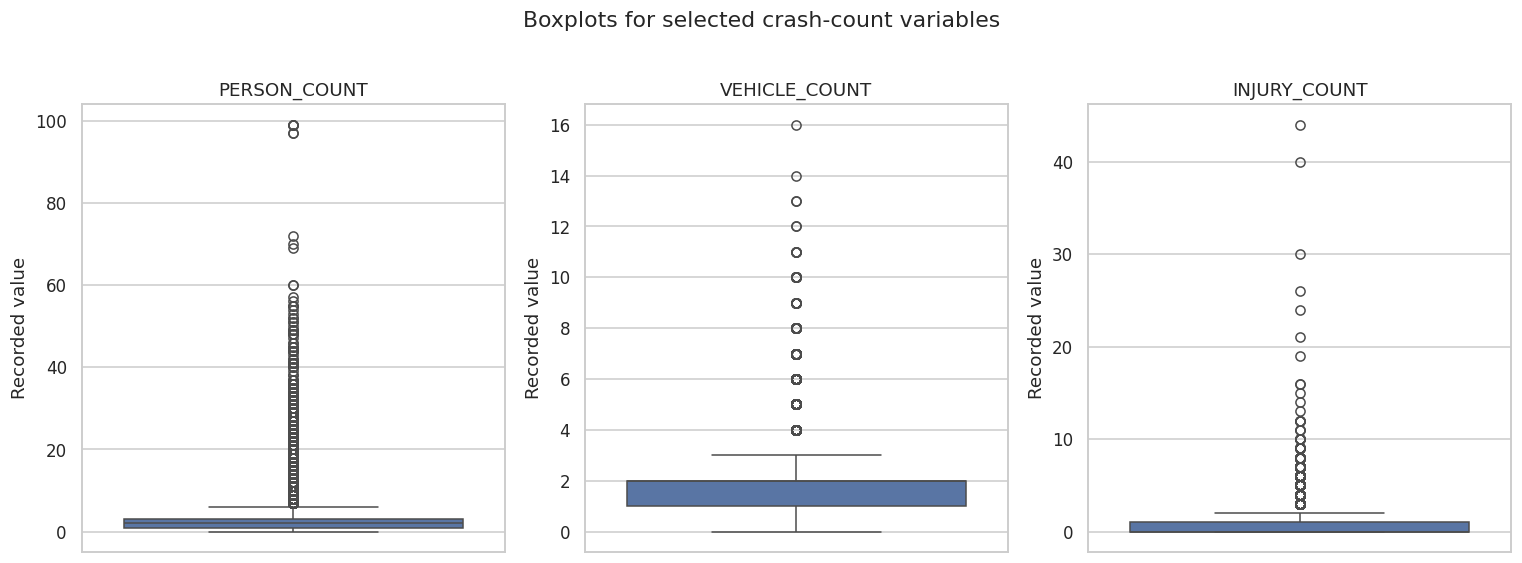

Outliers are retained: the IQR rule flags unusual values, not necessarily incorrect records.


In [68]:
fig, axes = plt.subplots(1, len(outlier_columns), figsize=(14, 5))
for ax, col in zip(axes, outlier_columns):
    sns.boxplot(y=pd.to_numeric(df[col], errors="coerce"), ax=ax, showfliers=True)
    ax.set_title(col)
    ax.set_ylabel("Recorded value")
plt.suptitle("Boxplots for selected crash-count variables", y=1.02)
plt.tight_layout()
plt.show()

print("Outliers are retained: the IQR rule flags unusual values, not necessarily incorrect records.")

### 12.1 Correlations among genuine quantities

Correlation is used only for quantities and measurements—not numeric category codes or crash IDs. We show both Pearson and Spearman correlation:

- **Pearson** measures linear association.
- **Spearman** measures rank-based, monotonic association and is less dependent on a linear relationship.

The results are descriptive. A correlation does not establish that one variable causes another. Some count variables may also be mechanically related because they describe the same crash.

### What this code does — comparing Pearson and Spearman correlations

The selected columns are numerical counts or measurements. Identifiers and numeric category codes are excluded because correlations between arbitrary codes would not have a meaningful interpretation.

The code converts the selected fields to numeric form and calculates two correlation matrices:
- Pearson correlation measures the strength and direction of a linear relationship.
- Spearman correlation measures the strength and direction of a monotonic relationship using ranks.

The heatmaps display values from −1 to +1. Values near +1 indicate positive association, values near −1 indicate negative association, and values near 0 indicate weak association under the relevant measure. Correlation does not establish causation.

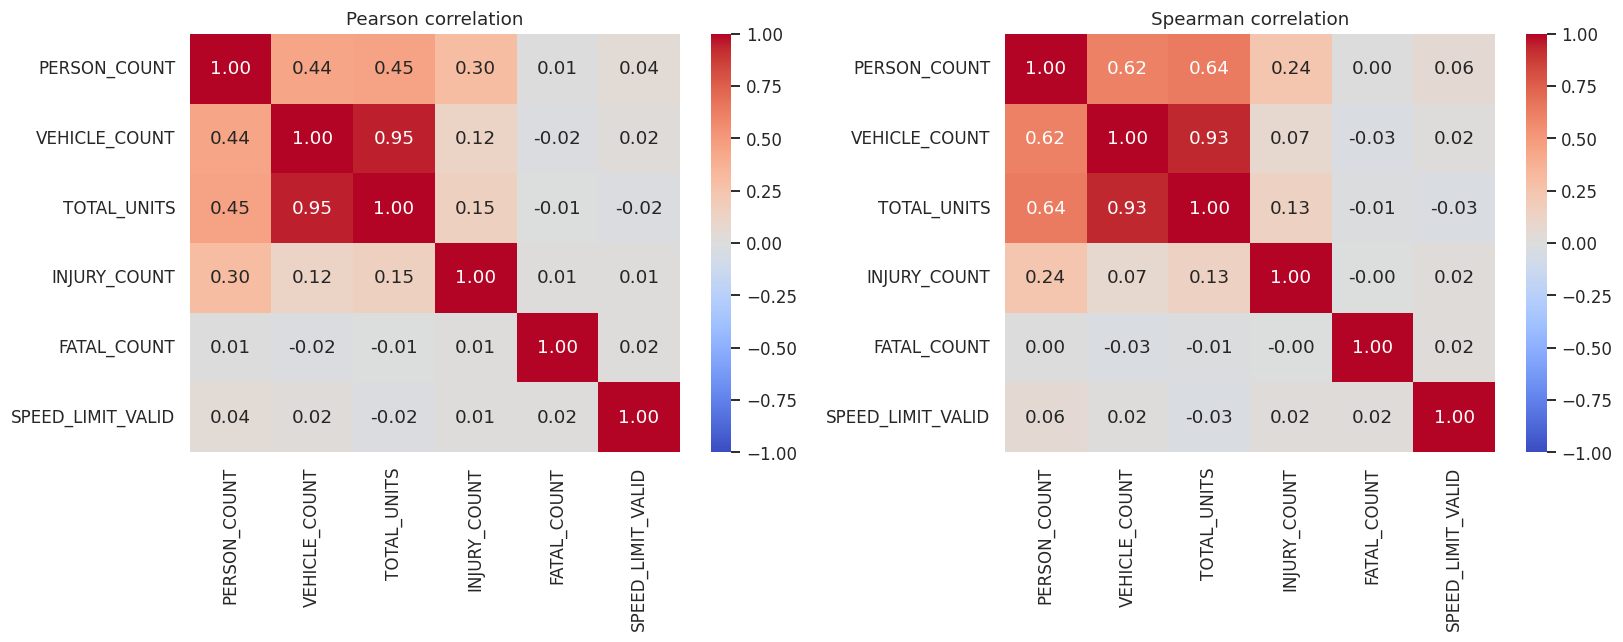

In [69]:
# Exclude identifiers and numeric category codes: correlation is only meaningful for quantities.
correlation_columns = [
    "PERSON_COUNT", "VEHICLE_COUNT", "TOTAL_UNITS",
    "INJURY_COUNT", "FATAL_COUNT", "SPEED_LIMIT_VALID"
]
correlation_columns = [col for col in correlation_columns if col in df.columns]
numeric_for_corr = df[correlation_columns].apply(pd.to_numeric, errors="coerce")

pearson_corr = numeric_for_corr.corr(method="pearson")
spearman_corr = numeric_for_corr.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson correlation")
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman correlation")
plt.tight_layout()
plt.show()

### 12.2 Conditional severity rates by recorded context

For a more meaningful comparison than raw category counts, we calculate the percentage of known-severity crashes that are serious or fatal within each group.

The binary outcome is defined only for severity codes 0–4:
- Serious/fatal: codes 1 and 2.
- Other known severity: codes 0, 3 and 4.
- Codes 8 and 9 are treated as unknown and excluded from this particular comparison.

Each group is shown with its sample size. Small groups are excluded from the plot to avoid over-interpreting unstable percentages.

**Interpretation rule:** The original 2004–2024 visual comparisons are retained for continuity, but post-2016 severity shares (with clearly stated known-outcome denominators) appear immediately after the existing plots and should be the primary substantive claims.


### What this code does — comparing serious/fatal shares across groups

The function `severity_rate_table()` first keeps rows with both a group label and a known binary severity outcome. It then groups the rows by category and calculates:
- `crashes`: number of eligible records in that category;
- `serious_or_fatal`: number whose binary outcome is 1;
- `severe_share`: proportion whose outcome is 1;
- `severe_percent`: the same proportion expressed as a percentage.

The `minimum_n` condition removes very small groups from the comparison, where percentages can be unstable. The loop repeats this calculation for weather, road surface, illumination and collision type, prints the supporting counts, and plots the serious/fatal percentage. The percentages are conditional on the recorded crash sample, not exposure-adjusted risks.


 WEATHER_GROUP


,crashes,serious_or_fatal,severe_percent
WEATHER_GROUP,,,
Unknown/other,492,28.0,5.69
Fog/smoke,453,23.0,5.08
Cloudy,3108,128.0,4.12
Clear/no adverse,158181,5940.0,3.76
Missing,121,4.0,3.31
Rain,25737,647.0,2.51
Other,1753,41.0,2.34
Winter precipitation,15678,241.0,1.54


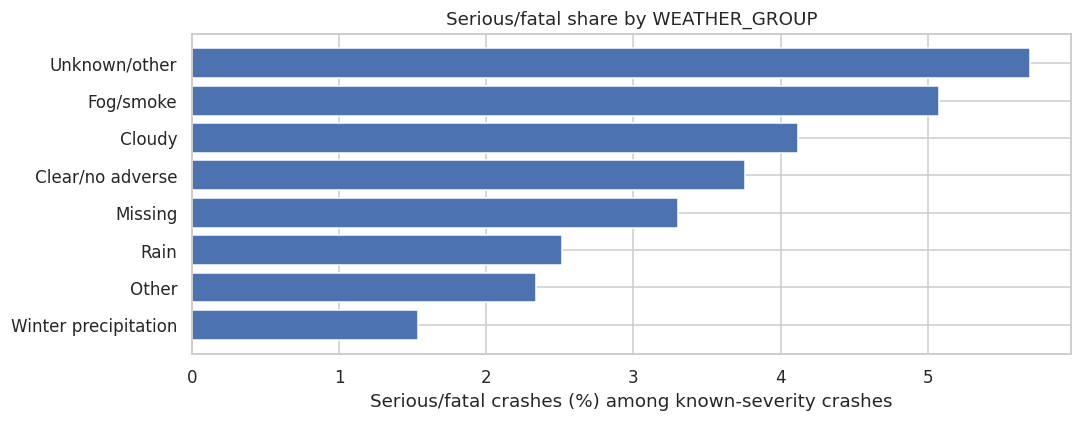


 ROAD_SURFACE_GROUP


,crashes,serious_or_fatal,severe_percent
ROAD_SURFACE_GROUP,,,
Debris/other,379,20.0,5.28
Other,440,21.0,4.77
Unknown/other,150,7.0,4.67
Dry,149448,5734.0,3.84
Wet,37264,1024.0,2.75
Standing water,500,10.0,2.00
Snow/ice/slush,17361,236.0,1.36


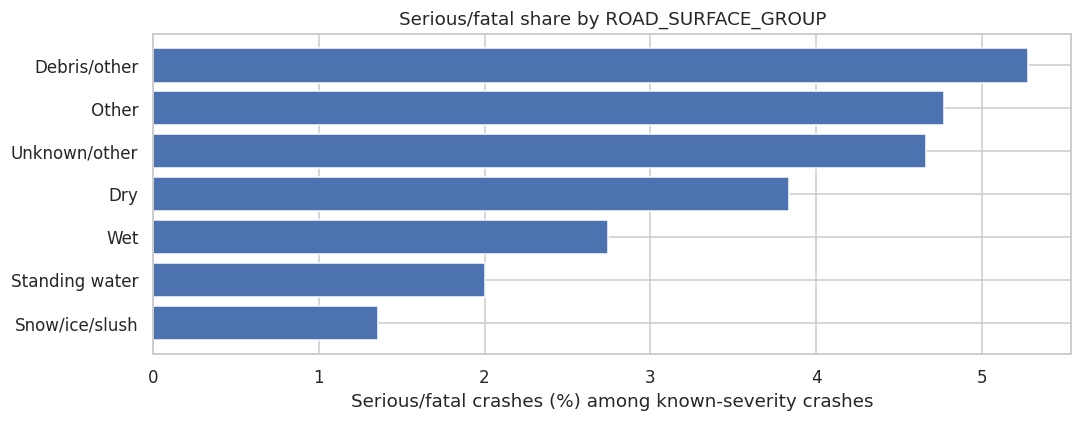


 ILLUMINATION_LABEL


,crashes,serious_or_fatal,severe_percent
ILLUMINATION_LABEL,,,
Dark: lighting unknown,945,53.0,5.61
Dark: no streetlights,13104,590.0,4.50
Missing/unknown,8881,382.0,4.30
Dark: streetlights,53300,2282.0,4.28
Dusk,3337,132.0,3.96
Dawn,3011,89.0,2.96
Daylight,122610,3514.0,2.87
Other,329,8.0,2.43


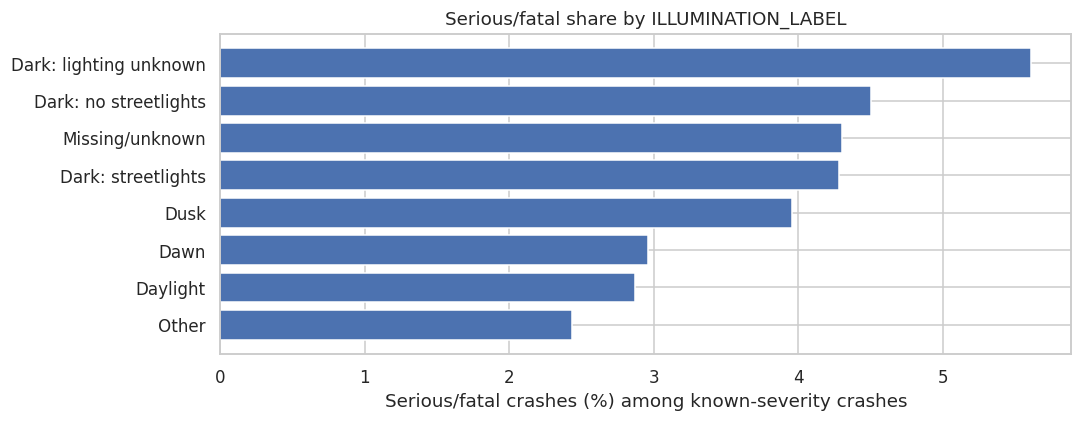


 COLLISION_LABEL


,crashes,serious_or_fatal,severe_percent
COLLISION_LABEL,,,
Pedestrian,5272,1046.0,19.84
Head-on,10014,809.0,8.08
Noncollision,5231,338.0,6.46
Fixed object,56016,2222.0,3.97
Angle,54434,1473.0,2.71
Sideswipe opposite direction,5039,132.0,2.62
Backing,501,11.0,2.20
Sideswipe same direction,10728,198.0,1.85
Other,1347,23.0,1.71


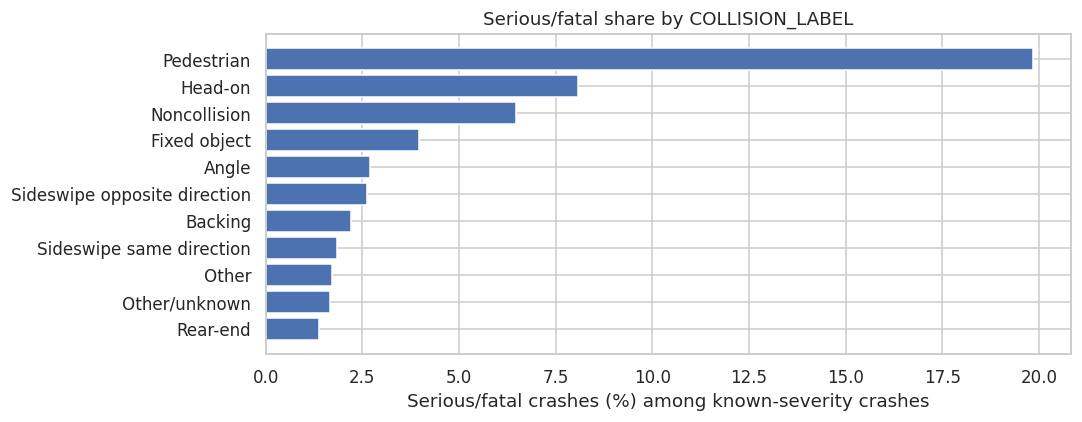

These are conditional percentages among reported crashes, not exposure-adjusted risk.
Post-2016 common-era severity comparisons (2016–2023; 2024 omitted for context coverage):
COLLISION_LABEL: denominator = 77,476 known-outcome records (category-specific n below)


,known_severity_n,serious_fatal_n,serious_fatal_share,serious_fatal_percent
COLLISION_LABEL,,,,
Angle,20940,697.0,0.033,3.329
Fixed object,20257,960.0,0.047,4.739
Rear-end,20066,350.0,0.017,1.744
Sideswipe same direction,4453,102.0,0.023,2.291
Head-on,4042,383.0,0.095,9.476
Sideswipe opposite direction,1920,61.0,0.032,3.177
Pedestrian,1846,496.0,0.269,26.869
Noncollision,1683,141.0,0.084,8.378
Other,1097,21.0,0.019,1.914


ILLUMINATION_LABEL: denominator = 77,476 known-outcome records (category-specific n below)


,known_severity_n,serious_fatal_n,serious_fatal_share,serious_fatal_percent
ILLUMINATION_LABEL,,,,
Daylight,48209,1757.0,0.036,3.645
Dark: streetlights,21380,1090.0,0.051,5.098
Dark: no streetlights,4745,255.0,0.054,5.374
Dusk,1361,65.0,0.048,4.776
Dawn,1236,40.0,0.032,3.236
Dark: lighting unknown,399,24.0,0.060,6.015
Other,138,2.0,0.014,1.449
Unknown,8,0.0,0.000,0.000


TIME_PERIOD: denominator = 77,476 known-outcome records (category-specific n below)


,known_severity_n,serious_fatal_n,serious_fatal_share,serious_fatal_percent
TIME_PERIOD,,,,
Afternoon,23397,885.0,0.038,3.783
Morning,20565,649.0,0.032,3.156
Evening,16819,732.0,0.044,4.352
Night,16295,955.0,0.059,5.861
Missing,400,12.0,0.030,3.000


INTERSECTION_LABEL: denominator = 77,476 known-outcome records (category-specific n below)


,known_severity_n,serious_fatal_n,serious_fatal_share,serious_fatal_percent
INTERSECTION_LABEL,,,,
Midblock,44291,1948.0,0.044,4.398
Four-way,14363,525.0,0.037,3.655
T intersection,14015,591.0,0.042,4.217
Y intersection,1816,82.0,0.045,4.515
Ramp end,1126,20.0,0.018,1.776
Ramp begin,654,15.0,0.023,2.294
Multileg,507,23.0,0.045,4.536
Other,501,20.0,0.040,3.992
L intersection,135,6.0,0.044,4.444


In [70]:
# Use only records with a known binary outcome; report group size alongside percentages.
def severity_rate_table(frame, group_column, minimum_n=100):
    # Exclude records without a group label or a known severe/non-severe outcome.
    valid = frame[[group_column, "SEVERE_OUTCOME"]].dropna()
    # Summarise the number of crashes and the share classified as serious/fatal.
    result = valid.groupby(group_column)["SEVERE_OUTCOME"].agg(
        crashes="size", serious_or_fatal="sum", severe_share="mean"
    )
    result["severe_percent"] = result["severe_share"] * 100
    # Ignore very small groups so their percentages are not over-interpreted.
    return result[result["crashes"] >= minimum_n].sort_values("severe_percent", ascending=False)

comparison_columns = [
    "WEATHER_GROUP", "ROAD_SURFACE_GROUP",
    "ILLUMINATION_LABEL", "COLLISION_LABEL"
]

for col in comparison_columns:
    table = severity_rate_table(df, col, minimum_n=100)
    print("\n", col)
    display(table[["crashes", "serious_or_fatal", "severe_percent"]].round(2))
    if len(table):
        plt.figure(figsize=(10, max(4, 0.35 * len(table))))
        plt.barh(table.index.astype(str)[::-1], table["severe_percent"].values[::-1])
        plt.xlabel("Serious/fatal crashes (%) among known-severity crashes")
        plt.title(f"Serious/fatal share by {col}")
        plt.tight_layout()
        plt.show()

print("These are conditional percentages among reported crashes, not exposure-adjusted risk.")

# Main severity comparison for the project: use only the post-2016 coding era.
# The unchanged v5 charts above are historical descriptions covering 2004–2024.
# They are not the principal source for post-2016 outcome comparisons.
post2016_known = df.loc[
    pd.to_numeric(df["CRASH_YEAR"],errors="coerce").between(2016,2023)
    & df["SEVERE_OUTCOME"].notna()
].copy()
print("Post-2016 common-era severity comparisons (2016–2023; 2024 omitted for context coverage):")
for col in ["COLLISION_LABEL", "ILLUMINATION_LABEL", "TIME_PERIOD", "INTERSECTION_LABEL"]:
    if col not in post2016_known:
        continue
    rates = post2016_known.groupby(col,dropna=False)["SEVERE_OUTCOME"].agg(
        known_severity_n="size",serious_fatal_n="sum",serious_fatal_share="mean")
    rates["serious_fatal_percent"] = 100*rates["serious_fatal_share"]
    print(f"{col}: denominator = {len(post2016_known):,} known-outcome records (category-specific n below)")
    display(rates.sort_values("known_severity_n",ascending=False).round(3))


### 12.3 Weather-by-severity cross-tabulation

Cross-tabulation is a pandas technique covered in the labs. The first table contains counts; the second gives row percentages, which answer: *within each weather group, how are the known-severity crashes distributed?*

### What this code does — using a cross-tabulation for weather and severity

The first statement keeps only records with one of the five known severity labels used in this comparison. `pd.crosstab()` then creates a table of counts: rows are weather groups and columns are severity categories.

The second cross-tabulation uses `normalize="index"`, which divides each row by its own total. Multiplying by 100 converts those proportions into percentages. Therefore, each row in the percentage table adds to approximately 100%, and shows the severity composition within that weather group.

In [71]:
weather_severity = df.loc[
    df["SEVERITY_LABEL"].isin([
        "Property damage only", "Fatal", "Serious injury",
        "Minor injury", "Possible injury"
    ]),
    ["WEATHER_GROUP", "SEVERITY_LABEL"]
]

weather_counts = pd.crosstab(
    weather_severity["WEATHER_GROUP"],
    weather_severity["SEVERITY_LABEL"]
)
weather_percent = pd.crosstab(
    weather_severity["WEATHER_GROUP"],
    weather_severity["SEVERITY_LABEL"],
    normalize="index"
) * 100

print("Crash counts:")
display(weather_counts)
print("Row percentages:")
display(weather_percent.round(2))

Crash counts:


SEVERITY_LABEL,Fatal,Minor injury,Possible injury,Property damage only,Serious injury
WEATHER_GROUP,,,,,
Clear/no adverse,1136,24005,31785,96451,4804
Cloudy,28,686,303,1991,100
Fog/smoke,8,64,71,295,15
Missing,0,22,8,87,4
Other,10,180,261,1271,31
Rain,143,3446,4989,16655,504
Unknown/other,9,68,87,309,19
Wind/blowing,0,6,0,15,0
Winter precipitation,62,1415,2475,11547,179


Row percentages:


SEVERITY_LABEL,Fatal,Minor injury,Possible injury,Property damage only,Serious injury
WEATHER_GROUP,,,,,
Clear/no adverse,0.72,15.18,20.09,60.98,3.04
Cloudy,0.90,22.07,9.75,64.06,3.22
Fog/smoke,1.77,14.13,15.67,65.12,3.31
Missing,0.00,18.18,6.61,71.90,3.31
Other,0.57,10.27,14.89,72.50,1.77
Rain,0.56,13.39,19.38,64.71,1.96
Unknown/other,1.83,13.82,17.68,62.80,3.86
Wind/blowing,0.00,28.57,0.00,71.43,0.00
Winter precipitation,0.40,9.03,15.79,73.65,1.14


In [72]:
# Formal post-2016 categorical associations. These are NOT causal effects.
# We use 2016–2023 consistently for context comparisons because 2024 illumination
# is fully missing and hour coverage is exceptionally poor. 2024 remains included
# in the separate, explicitly labelled 2022–2024 classifier test window.
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

def wilson_interval(successes, sample_size, z=1.95996398454):
    """Wilson binomial 95% interval; small-sample safe, unlike p +/- 1.96*SE."""
    n = float(sample_size)
    if n <= 0:
        return (np.nan, np.nan)
    p = float(successes) / n
    denom = 1.0 + z*z/n
    center = (p + z*z/(2*n))/denom
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/denom
    return (max(0., center-half), min(1., center+half))

# Explicit analytical population: severity-known crashes in a comparable
# injury-code era, before the 2024 illumination/hour reporting collapse.
association_years = pd.to_numeric(df["CRASH_YEAR"], errors="coerce")
association_population = df.loc[
    association_years.between(2016, 2023) & df["SEVERE_OUTCOME"].notna()
].copy()
association_population_n = len(association_population)
assert association_population_n > 0, "No post-2016 known-severity records for association testing."
print(f"Association inference: 2016–2023 known-severity records = {association_population_n:,}.")


def sparse_safe_chisquare(frame, feature, minimum_level_n=100, min_expected=5.0):
    """Test a feature only after transparently grouping statistically sparse levels.

    Step 1: keep original levels for a descriptive audit. Initially group categories
    with <minimum_level_n records into 'Other (pooled for test)'.
    Step 2: check *all expected cell counts*. When any are too small, merge the
    smallest remaining non-largest category into the pooled level and retry.
    This rule is independent of individual outcomes after the initial grouping;
    it is a practical asymptotic-table safeguard, not an optimisation of p-values.
    If a valid two-category table is impossible, return a skip reason—never emit
    a misleading chi-square p-value.
    """
    base = frame[[feature, "SEVERE_OUTCOME"]].copy()
    # Source missing and unmapped values remain distinct whenever their size
    # permits; otherwise they appear in the visible pooled-count audit below.
    levels = base[feature].astype("string").fillna("Missing").astype(str)
    original_counts = levels.value_counts(dropna=False)
    small_levels = original_counts.index[original_counts < minimum_level_n]
    grouped = levels.where(~levels.isin(small_levels), "Other (pooled for test)")
    grouped_levels = sorted(set(small_levels))
    original_k = int(original_counts.size)
    for _ in range(original_k + 2):
        table = pd.crosstab(grouped, base["SEVERE_OUTCOME"])
        if table.shape[0] < 2 or table.shape[1] != 2:
            return None, {"feature":feature, "reason":"<2 categories or outcomes after pooling",
                          "pooled_original_levels":grouped_levels}
        # correction=False is relevant only for 2x2 and is specified for consistency.
        chi2, p, dof, expected = chi2_contingency(table, correction=False)
        if np.all(expected >= min_expected):
            n = int(table.to_numpy().sum())
            v = float(np.sqrt(chi2/(n*min(table.shape[0]-1, table.shape[1]-1))))
            result = {"feature": feature, "analysis_years": "2016–2023",
                      "known_severity_population_n": association_population_n,
                      "tested_known_severity_n": n,
                      "within_population_coverage_percent":round(100*n/association_population_n,2),
                      "overall_source_fraction_percent":round(100*n/len(df),2),
                      "original_levels":original_k, "tested_levels":table.shape[0],
                      "pooled_source_levels":len(grouped_levels),
                      "min_expected_cell":float(expected.min()),
                      "cramers_v":v, "chi2_stat":float(chi2),
                      "degrees_freedom":int(dof), "raw_p":float(p)}
            return result, {"feature":feature, "pooled_original_levels":grouped_levels,
                            "contingency":table, "reason":"valid"}
        # Merge the smallest category other than the existing pooled category
        # or the largest remaining category; stop if no valid comparison remains.
        level_counts = grouped.value_counts()
        candidates = level_counts.drop(labels=["Other (pooled for test)"], errors="ignore")
        if len(candidates) <= 1:
            break
        smallest = candidates.idxmin()
        grouped = grouped.mask(grouped == smallest, "Other (pooled for test)")
        grouped_levels.append(str(smallest))
    return None, {"feature":feature,"reason":"expected counts remain <5 after pooling",
                  "pooled_original_levels":grouped_levels}

association_rows, association_diagnostics = [], []
for field in ["COLLISION_LABEL", "ILLUMINATION_LABEL", "WEATHER_GROUP",
              "ROAD_SURFACE_GROUP", "TIME_PERIOD", "INTERSECTION_LABEL"]:
    if field in {"WEATHER_GROUP", "ROAD_SURFACE_GROUP"} and not CODEBOOK_VERIFIED:
        print(f"{field}: descriptive only; unverified historical mappings cannot be formally tested.")
        association_diagnostics.append({"feature":field,"reason":"unverified historical codebook"})
        continue
    result, audit = sparse_safe_chisquare(association_population, field)
    association_diagnostics.append({"feature":field,
        "reason":audit["reason"],"pooled_original_levels":", ".join(audit.get("pooled_original_levels",[]))})
    if result is not None:
        association_rows.append(result)
        print(f"{field}: chi-square valid; {result['tested_levels']} levels, "
              f"minimum expected cell {result['min_expected_cell']:.1f}; "
              f"original levels pooled: {result['pooled_source_levels']}.")
    else:
        print(f"{field}: inference skipped — {audit['reason']}.")
association_results = pd.DataFrame(association_rows)
association_audit = pd.DataFrame(association_diagnostics)
if len(association_results):
    # BH correction uses the family of ALL successfully tested hypotheses.
    association_results["fdr_bh_q"] = multipletests(association_results["raw_p"], method="fdr_bh")[1]
    display(association_results.sort_values("cramers_v",ascending=False).round(5))
print("Category pooling and exclusion audit (pooled levels require substantive review):")
display(association_audit)

# These group shares are descriptive and include EVERY level, including small-n
# values omitted from significance testing. Do not interpret '0 of 21' as proof
# of zero risk; Wilson intervals make the uncertainty visible.
for group_col in ["COLLISION_LABEL", "WEATHER_GROUP"]:
    denominator = association_population[[group_col,"SEVERE_OUTCOME"]].copy()
    denominator[group_col] = denominator[group_col].fillna("Missing")
    rate_table = denominator.groupby(group_col)["SEVERE_OUTCOME"].agg(n="size",serious_fatal="sum")
    limits = [wilson_interval(r.serious_fatal,r.n) for r in rate_table.itertuples()]
    rate_table["share_percent"] = 100*rate_table["serious_fatal"]/rate_table["n"]
    rate_table["ci_lower_95_percent"] = [100*x[0] for x in limits]
    rate_table["ci_upper_95_percent"] = [100*x[1] for x in limits]
    print(f"{group_col}: conditional serious/fatal share among 2016–2023 known-severity crashes; descriptive only:")
    display(rate_table.sort_values("n",ascending=False).round(2))


Association inference: 2016–2023 known-severity records = 77,476.
COLLISION_LABEL: chi-square valid; 11 levels, minimum expected cell 14.3; original levels pooled: 2.
ILLUMINATION_LABEL: chi-square valid; 7 levels, minimum expected cell 6.1; original levels pooled: 2.
WEATHER_GROUP: descriptive only; unverified historical mappings cannot be formally tested.
ROAD_SURFACE_GROUP: descriptive only; unverified historical mappings cannot be formally tested.
TIME_PERIOD: chi-square valid; 5 levels, minimum expected cell 16.7; original levels pooled: 0.
INTERSECTION_LABEL: chi-square valid; 9 levels, minimum expected cell 8.5; original levels pooled: 6.


,feature,analysis_years,known_severity_population_n,tested_known_severity_n,within_population_coverage_percent,overall_source_fraction_percent,original_levels,tested_levels,pooled_source_levels,min_expected_cell,cramers_v,chi2_stat,degrees_freedom,raw_p,fdr_bh_q
0,COLLISION_LABEL,2016–2023,77476,77476,100.0,31.14,12,11,2,14.27134,0.20195,3159.83990,10,0.00000,0.00000
2,TIME_PERIOD,2016–2023,77476,77476,100.0,31.14,5,5,0,16.69162,0.04832,180.92419,4,0.00000,0.00000
1,ILLUMINATION_LABEL,2016–2023,77476,77476,100.0,31.14,8,7,2,6.09244,0.03712,106.75884,6,0.00000,0.00000
3,INTERSECTION_LABEL,2016–2023,77476,77476,100.0,31.14,14,9,6,8.47100,0.02216,38.04212,8,0.00001,0.00001


Category pooling and exclusion audit (pooled levels require substantive review):


,feature,reason,pooled_original_levels
0,COLLISION_LABEL,valid,"Unknown, Backing"
1,ILLUMINATION_LABEL,valid,"Unknown, Other"
2,WEATHER_GROUP,unverified historical codebook,NaN
3,ROAD_SURFACE_GROUP,unverified historical codebook,NaN
4,TIME_PERIOD,valid,
5,INTERSECTION_LABEL,valid,"Crossover, Railroad crossing, Roundabout, Traf..."


COLLISION_LABEL: conditional serious/fatal share among 2016–2023 known-severity crashes; descriptive only:


,n,serious_fatal,share_percent,ci_lower_95_percent,ci_upper_95_percent
COLLISION_LABEL,,,,,
Angle,20940,697.0,3.33,3.09,3.58
Fixed object,20257,960.0,4.74,4.45,5.04
Rear-end,20066,350.0,1.74,1.57,1.93
Sideswipe same direction,4453,102.0,2.29,1.89,2.77
Head-on,4042,383.0,9.48,8.61,10.42
Sideswipe opposite direction,1920,61.0,3.18,2.48,4.06
Pedestrian,1846,496.0,26.87,24.90,28.94
Noncollision,1683,141.0,8.38,7.15,9.80
Other,1097,21.0,1.91,1.26,2.91


WEATHER_GROUP: conditional serious/fatal share among 2016–2023 known-severity crashes; descriptive only:


,n,serious_fatal,share_percent,ci_lower_95_percent,ci_upper_95_percent
WEATHER_GROUP,,,,,
Clear/no adverse,59740,2708.0,4.53,4.37,4.70
Rain,9444,298.0,3.16,2.82,3.53
Winter precipitation,4658,89.0,1.91,1.56,2.35
Cloudy,2511,99.0,3.94,3.25,4.78
Other,642,19.0,2.96,1.90,4.58
Unknown/other,266,9.0,3.38,1.79,6.30
Fog/smoke,176,11.0,6.25,3.53,10.84
Missing,20,0.0,0.00,0.00,16.11
Wind/blowing,19,0.0,0.00,0.00,16.82


### 12.4 Adjusted post-2016 severity associations

A binomial Logistic Regression estimates adjusted associations between recorded crash circumstances and the serious/fatal outcome. The analysis uses 2016–2023, includes year fixed effects, merges very small category levels into an explicit low-frequency group, and reports odds ratios with HC0 robust 95% confidence intervals. It is an association model, not a causal estimate. The 2024 records are excluded because hour and illumination are structurally unavailable for that year.

In [73]:
# Estimate adjusted associations only within the post-2016 severity-definition period.
try:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf

    adjusted_columns = [
        "SEVERE_OUTCOME", "CRASH_YEAR", "CRASH_MONTH", "COLLISION_LABEL", "ILLUMINATION_LABEL",
        "WEATHER_GROUP", "ROAD_SURFACE_GROUP", "TIME_PERIOD",
        "INTERSECTION_LABEL", "SPEED_LIMIT_VALID"
    ]
    adjusted_columns = [c for c in adjusted_columns if c not in {"WEATHER_GROUP", "ROAD_SURFACE_GROUP"} or CODEBOOK_VERIFIED]
    adjusted_data = df.loc[
        pd.to_numeric(df["CRASH_YEAR"], errors="coerce").between(2016, 2023)
        & df["SEVERE_OUTCOME"].notna(),
        adjusted_columns
    ].copy()
    adjusted_data["CRASH_YEAR"] = pd.to_numeric(adjusted_data["CRASH_YEAR"], errors="coerce").astype(int)

    adjusted_categorical = [
        "COLLISION_LABEL", "ILLUMINATION_LABEL", "WEATHER_GROUP",
        "ROAD_SURFACE_GROUP", "TIME_PERIOD", "INTERSECTION_LABEL",
        "CRASH_MONTH"
    ]
    # Unverified historical code groups are not reliable regressors.
    if not CODEBOOK_VERIFIED:
        adjusted_categorical = [x for x in adjusted_categorical
                                if x not in {"WEATHER_GROUP", "ROAD_SURFACE_GROUP"}]
    for column in adjusted_categorical:
        adjusted_data[column] = adjusted_data[column].astype("string").fillna("Missing").astype(str)
        category_counts = adjusted_data[column].value_counts()
        # Collapse rare levels and levels with <5 events or <5 nonevents.
        # In v5, a no-event level produced 0.000 odds ratios despite convergence.
        event_counts = adjusted_data.groupby(column)["SEVERE_OUTCOME"].agg(["size", "sum"])
        low_event = event_counts.index[(event_counts["sum"] < 5)
                                       | ((event_counts["size"] - event_counts["sum"]) < 5)]
        low_frequency = category_counts.index[category_counts < 100].union(low_event)
        adjusted_data[column] = adjusted_data[column].where(
            ~adjusted_data[column].isin(low_frequency), "Other/low-frequency"
        )

    adjusted_data["SPEED_LIMIT_VALID"] = pd.to_numeric(
        adjusted_data["SPEED_LIMIT_VALID"], errors="coerce"
    )
    speed_median = adjusted_data["SPEED_LIMIT_VALID"].median()
    if pd.isna(speed_median):
        raise ValueError("No valid SPEED_LIMIT entries are available for the adjusted model.")
    adjusted_data["SPEED_LIMIT_VALID"] = adjusted_data["SPEED_LIMIT_VALID"].fillna(speed_median)

    # Audit non-events and severe events for each level after regrouping.
    rare_level_audit = pd.concat([
        adjusted_data.groupby(c)["SEVERE_OUTCOME"].agg(
            n="size", serious_fatal="sum").assign(variable=c, level=lambda t: t.index)
        for c in adjusted_categorical
    ], ignore_index=True)
    rare_level_audit["non_severe"] = rare_level_audit["n"] - rare_level_audit["serious_fatal"]
    print("Adjusted-model event count / separation audit by level:")
    display(rare_level_audit[["variable", "level", "n", "serious_fatal", "non_severe"]])
    formula_terms = []
    reference_levels = {}
    for column in adjusted_categorical:
        reference_level = adjusted_data[column].value_counts().index[0]
        reference_levels[column] = reference_level
        formula_terms.append(f"C({column}, Treatment(reference={reference_level!r}))")
    formula_terms.extend(["SPEED_LIMIT_VALID", "C(CRASH_YEAR)"])
    adjusted_formula = "SEVERE_OUTCOME ~ " + " + ".join(formula_terms)

    print(f"Records used: {len(adjusted_data):,}")
    print(f"Serious/fatal records: {int(adjusted_data['SEVERE_OUTCOME'].sum()):,}")
    print("Reference categories:")
    display(pd.Series(reference_levels, name="reference_category").to_frame())

    adjusted_result = smf.glm(
        formula=adjusted_formula,
        data=adjusted_data,
        family=sm.families.Binomial()
    ).fit(maxiter=100, cov_type="HC0")

    # Large coefficients or nearly zero events indicate residual separation.
    # Penalised ridge fitting is a stable descriptive fallback, but frequentist
    # standard errors from a regularised fit are not available from this method.
    unstable = (not np.isfinite(adjusted_result.params).all()
                or (adjusted_result.params.abs() > 12).any()
                or not getattr(adjusted_result, "converged", False))
    if unstable:
        print("Separation/instability detected: fitting L2-penalised logistic GLM; do not report unregularised CIs.")
        adjusted_result_penalized = smf.glm(
            formula=adjusted_formula, data=adjusted_data,
            family=sm.families.Binomial()
        ).fit_regularized(alpha=0.01, L1_wt=0.0, maxiter=300)
        adjusted_penalised_or = pd.DataFrame({
            "penalised_odds_ratio": np.exp(adjusted_result_penalized.params.clip(-20, 20))
        }).drop(index="Intercept", errors="ignore")
        display(adjusted_penalised_or.round(3))
        adjusted_or = pd.DataFrame()
    else:
        adjusted_ci = adjusted_result.conf_int()
        adjusted_or = pd.DataFrame({
            "odds_ratio": np.exp(adjusted_result.params.clip(-20, 20)),
            "ci_lower_95": np.exp(adjusted_ci[0].clip(-20, 20)),
            "ci_upper_95": np.exp(adjusted_ci[1].clip(-20, 20)),
            "p_value": adjusted_result.pvalues
        }).drop(index="Intercept", errors="ignore")
        adjusted_or["fdr_bh_q"] = multipletests(adjusted_or["p_value"].fillna(1.0), method="fdr_bh")[1]
        print("Adjusted odds ratios with robust 95% confidence intervals and BH q-values:")
        display(adjusted_or.sort_values("p_value").round(3))
    print("Model converged:", getattr(adjusted_result, "converged", "Not reported by this statsmodels version"))
except ImportError:
    print("statsmodels is unavailable in this runtime. Install it with: %pip install statsmodels")
except Exception as error:
    print("The adjusted Logistic Regression could not be fitted on this runtime/data slice.")
    print(f"Diagnostic: {type(error).__name__}: {error}")


Adjusted-model event count / separation audit by level:


,variable,level,n,serious_fatal,non_severe
0,COLLISION_LABEL,Angle,20940,697.0,20243.0
1,COLLISION_LABEL,Fixed object,20257,960.0,19297.0
2,COLLISION_LABEL,Head-on,4042,383.0,3659.0
3,COLLISION_LABEL,Noncollision,1683,141.0,1542.0
4,COLLISION_LABEL,Other,1097,21.0,1076.0
5,COLLISION_LABEL,Other/low-frequency,342,7.0,335.0
6,COLLISION_LABEL,Other/unknown,830,15.0,815.0
7,COLLISION_LABEL,Pedestrian,1846,496.0,1350.0
8,COLLISION_LABEL,Rear-end,20066,350.0,19716.0
9,COLLISION_LABEL,Sideswipe opposite direction,1920,61.0,1859.0


Records used: 77,476
Serious/fatal records: 3,233
Reference categories:


,reference_category
COLLISION_LABEL,Angle
ILLUMINATION_LABEL,Daylight
TIME_PERIOD,Afternoon
INTERSECTION_LABEL,Midblock
CRASH_MONTH,1


Adjusted odds ratios with robust 95% confidence intervals and BH q-values:


,odds_ratio,ci_lower_95,ci_upper_95,p_value,fdr_bh_q
"C(COLLISION_LABEL, Treatment(reference='Angle'))[T.Pedestrian]",10.633,9.347,12.095,0.000,0.000
"C(COLLISION_LABEL, Treatment(reference='Angle'))[T.Head-on]",2.744,2.406,3.128,0.000,0.000
"C(COLLISION_LABEL, Treatment(reference='Angle'))[T.Rear-end]",0.453,0.395,0.520,0.000,0.000
"C(COLLISION_LABEL, Treatment(reference='Angle'))[T.Noncollision]",2.142,1.765,2.600,0.000,0.000
"C(INTERSECTION_LABEL, Treatment(reference='Midblock'))[T.Four-way]",0.662,0.591,0.742,0.000,0.000
"C(CRASH_MONTH, Treatment(reference='1'))[T.7]",1.910,1.593,2.291,0.000,0.000
"C(CRASH_MONTH, Treatment(reference='1'))[T.9]",1.854,1.552,2.214,0.000,0.000
"C(CRASH_MONTH, Treatment(reference='1'))[T.6]",1.755,1.463,2.106,0.000,0.000
"C(CRASH_MONTH, Treatment(reference='1'))[T.8]",1.673,1.397,2.004,0.000,0.000
"C(CRASH_MONTH, Treatment(reference='1'))[T.4]",1.640,1.362,1.975,0.000,0.000


Model converged: True


## 13. County geography and coordinate-quality audit

Two coordinate sources are available in the crash records:

- Police GPS coordinates: `LATITUDE` and `LONGITUDE`.
- State-route decimal coordinates: `DEC_LAT` and `DEC_LONG`.

The police GPS fields contain text resembling degrees, minutes and seconds, such as `40 19:05.530`. This section parses that format for a diagnostic comparison against the state-route decimal coordinates.

The comparison reports the number of valid candidate pairs, distance differences, and disagreements exceeding 500 metres.

**Coordinate-selection policy:** Diagnostic parsing alone does not establish verified source provenance. Police coordinates can become an operational source only after the format is verified using official documentation. Until then, validated state-route decimal coordinates remain the selected source.

Known placeholder coordinates are excluded. Geographic membership is determined using the actual Allegheny County polygon, not a rectangular bounding box.

All geographic results represent historical recorded-crash locations, not exposure-adjusted traffic risk.

In [74]:
# Geographic screening is intentionally in one reusable data object for all later maps.
# The only required raw source is the crash CSV; the Census boundary is a public
# reference download (or local cache), not an inferred bounding rectangle.
from shapely.geometry import Point, shape
from shapely.prepared import prep
from math import radians, sin, cos, asin, sqrt
from urllib.request import urlretrieve

def parse_decimal_coordinate(column, low, high):
    """Accept only literal decimal degrees in a plausible regional range.
    Other GPS coordinate encodings need a documented conversion before use."""
    if column not in df:
        return pd.Series(np.nan, index=df.index, dtype=float)
    raw = df[column].astype("string").str.strip()
    # Restrict to signed decimal forms, not a 6-digit DMS or a value with letters.
    formatted = raw.str.fullmatch(r"[+-]?\d{1,3}(?:\.\d+)?").fillna(False)
    return pd.to_numeric(raw.where(formatted), errors="coerce").where(
        lambda x: x.between(low, high))

def haversine_m(lat1, lon1, lat2, lon2):
    """Vectorised spherical great-circle distance in metres; coordinates in degrees."""
    rlat1, rlon1, rlat2, rlon2 = [np.radians(x) for x in (lat1, lon1, lat2, lon2)]
    a = (np.sin((rlat2-rlat1)/2)**2
         + np.cos(rlat1)*np.cos(rlat2)*np.sin((rlon2-rlon1)/2)**2)
    return 2*6371000*np.arcsin(np.sqrt(np.clip(a, 0, 1)))

# First inspect the raw police-coordinate encoding; v6's earlier decimal-only
# parser accepted zero police pairs, so that run did NOT prove agreement between
# police and state-route locations. Preserve this diagnostic independently of
# whether optional conversion metadata is available.
def police_raw_format_audit(field):
    if field not in df.columns:
        return {"field":field,"present":False}
    raw = df[field].astype("string").str.strip()
    raw = raw[raw.notna() & ~raw.isin(["", "0", "0.0", "nan", "None"])]
    numeric = pd.to_numeric(raw,errors="coerce")
    return {"field":field,"present":True,"nonblank_nonzero":len(raw),
            "numeric_entries":int(numeric.notna().sum()),
            "illustrative_distinct_raw_values":raw.drop_duplicates().head(6).tolist(),
            "numeric_p01":float(numeric.quantile(.01)) if numeric.notna().any() else np.nan,
            "numeric_median":float(numeric.median()) if numeric.notna().any() else np.nan,
            "numeric_p99":float(numeric.quantile(.99)) if numeric.notna().any() else np.nan}

police_encoding_audit = pd.DataFrame([
    police_raw_format_audit("LATITUDE"), police_raw_format_audit("LONGITUDE")
])
print("Police-coordinate raw format diagnostic (do not infer the encoding from sample values alone):")
display(police_encoding_audit)

# Optional, source-verified conversion contract:
# data/reference/coordinates/police_gps_format.json
# {"verified":true, "format":"ddmmss", "source_url":"https://...",
#  "latitude_hemisphere":"N", "longitude_hemisphere":"W"}
# Accepted formats: decimal_degrees, ddmmss (DDMMSS.s for latitude and
# DDDMMSS.s for longitude), and degrees_decimal_minutes (DDMM.m / DDDMM.m).
# This file must be populated from OFFICIAL source documentation. It is NOT
# invented or auto-activated based only on observed numeric magnitudes.
police_format_path = REFERENCE_ROOT / "coordinates" / "police_gps_format.json"
police_format = "unverified"
police_format_evidence = None
if police_format_path.is_file():
    try:
        police_format_evidence = json.loads(police_format_path.read_text(encoding="utf-8"))
        permitted = {
            "decimal_degrees",
            "ddmmss",
            "degrees_decimal_minutes",
            "dms_text"
        }
        if (police_format_evidence.get("verified") is True
            and police_format_evidence.get("format") in permitted
            and str(police_format_evidence.get("source_url", "")).startswith("https://")
            and police_format_evidence.get("latitude_hemisphere") in {"N", "S"}
            and police_format_evidence.get("longitude_hemisphere") in {"E", "W"}):
            police_format = police_format_evidence["format"]
        else:
            warnings.warn("Police GPS format declaration is incomplete/unverified; ignoring conversion.")
    except (OSError, ValueError, TypeError) as err:
        warnings.warn(f"Police GPS format declaration cannot be read: {err}")

def parse_police_dms_text(field, hemisphere, is_longitude=False):
    """
    Parse police GPS coordinates written as degrees, minutes and seconds.

    Observed examples:
        Latitude:  "40 19:05.530"
        Longitude: "79 54:27.197"

    The format represents:
        Degrees Minutes:Seconds

    Conversion:
        Decimal degrees = degrees + minutes/60 + seconds/3600

    Hemisphere controls the sign:
        N/E = positive
        S/W = negative

    IMPORTANT:
    This function parses the observed text format. Parsing does not,
    by itself, establish official verification of the source encoding.
    The main coordinate-selection workflow must retain its existing
    verification gate before using these coordinates operationally.
    """

    if field not in df.columns:
        return pd.Series(np.nan, index=df.index, dtype=float)

    raw = df[field].astype("string").str.strip()

    # Require the complete expected pattern, not a partial match.
    # This prevents malformed or unrelated coordinate values from
    # being interpreted as valid geographic positions.
    parts = raw.str.extract(
        r"^(\d{1,3})\s+(\d{1,2}):(\d{1,2}(?:\.\d+)?)$"
    )

    degrees = pd.to_numeric(
        parts[0], errors="coerce"
    ).astype(float)

    minutes = pd.to_numeric(
        parts[1], errors="coerce"
    ).astype(float)

    seconds = pd.to_numeric(
        parts[2], errors="coerce"
    ).astype(float)

    # Both minutes and seconds must lie in [0, 60).
    valid = (
        minutes.between(0, 60, inclusive="left")
        & seconds.between(0, 60, inclusive="left")
    )

    decimal = (
        degrees
        + minutes / 60.0
        + seconds / 3600.0
    )

    # Apply the explicitly supplied hemisphere.
    if hemisphere not in {"N", "S", "E", "W"}:
        raise ValueError("Unsupported coordinate hemisphere")

    if hemisphere in {"S", "W"}:
        decimal = -decimal

    # Restrict results to the broad geographic region used by
    # the existing v6 coordinate-quality checks.
    if is_longitude:
        decimal = decimal.where(
            valid & decimal.between(-82, -78)
        )
    else:
        decimal = decimal.where(
            valid & decimal.between(38, 43)
        )

    return decimal
def police_coord_degrees(field, is_longitude=False):
    """Convert ONLY an officially declared GPS encoding, with strict ranges.

    ddmmss converts DDMMSS.s (latitude) or DDDMMSS.s (longitude) by
    splitting degrees/minutes/seconds. degrees_decimal_minutes converts
    DDMM.m or DDDMM.m. Both validate that minutes and seconds are <60.
    No method turns unverified raw integers into geographic positions.
    """
    low, high = (-82.,-78.) if is_longitude else (38.,43.)
    if police_format == "unverified":
        return pd.Series(np.nan,index=df.index,dtype=float)
    if police_format == "decimal_degrees":
        return parse_decimal_coordinate(field, low, high)

    # Handle the actual degrees-minutes-seconds text encoding.
    # Only activate it when the format has passed the existing
    # official-source verification gate.
    if police_format == "dms_text":
        hemisphere = police_format_evidence[
            "longitude_hemisphere"
            if is_longitude
            else "latitude_hemisphere"
        ]

        return parse_police_dms_text(
            field,
            hemisphere=hemisphere,
            is_longitude=is_longitude
        )

    # Preserve the original numeric-format conversions.
    raw = pd.to_numeric(df[field], errors="coerce")
    positive = raw.abs()
    if police_format == "ddmmss":
        deg = np.floor(positive/10000)
        mins = np.floor((positive - deg*10000)/100)
        secs = positive - deg*10000 - mins*100
        valid_format = mins.between(0,60,inclusive="left") & secs.between(0,60,inclusive="left")
        decimal = deg + mins/60 + secs/3600
    else:  # verified degrees and decimal minutes
        deg = np.floor(positive/100)
        mins = positive-deg*100
        valid_format = mins.between(0,60,inclusive="left")
        decimal = deg + mins/60
    hemi = police_format_evidence["longitude_hemisphere" if is_longitude else "latitude_hemisphere"]
    signed = decimal if hemi in {"N", "E"} else -decimal
    return signed.where(valid_format & signed.between(low,high))

police_lat = police_coord_degrees("LATITUDE")
police_lon = police_coord_degrees("LONGITUDE",is_longitude=True)
print("Police GPS conversion:", police_format,
      "(DISABLED without verified official metadata)" if police_format == "unverified"
      else "(enabled using reviewed format metadata)")
state_lat = parse_decimal_coordinate("DEC_LAT", 38, 43)
state_lon = parse_decimal_coordinate("DEC_LONG", -82, -78)
# ------------------------------------------------------------
# Police GPS versus state-route coordinate comparison
# ------------------------------------------------------------
#
# The raw source audit identified police coordinate strings
# resembling degrees, minutes and seconds.
#
# We calculate N/W candidate coordinates for diagnostic purposes
# and compare them against the state-route decimal coordinates.
#
# These candidate coordinates are NOT automatically selected for
# mapping. The existing official-format verification gate controls
# whether police coordinates become operational.

candidate_police_lat = parse_police_dms_text(
    "LATITUDE",
    hemisphere="N"
)

candidate_police_lon = parse_police_dms_text(
    "LONGITUDE",
    hemisphere="W",
    is_longitude=True
)

# Compare only records with both complete coordinate pairs.
# Exclude the known (40.0, -80.0) placeholder from this audit.
candidate_pairs = (
    candidate_police_lat.notna()
    & candidate_police_lon.notna()
    & state_lat.notna()
    & state_lon.notna()
    & ~(
        np.isclose(candidate_police_lat, 40.0)
        & np.isclose(candidate_police_lon, -80.0)
    )
    & ~(
        np.isclose(state_lat, 40.0)
        & np.isclose(state_lon, -80.0)
    )
)

candidate_disagreement = pd.Series(
    np.nan,
    index=df.index,
    dtype=float
)

candidate_disagreement.loc[candidate_pairs] = haversine_m(
    candidate_police_lat.loc[candidate_pairs],
    candidate_police_lon.loc[candidate_pairs],
    state_lat.loc[candidate_pairs],
    state_lon.loc[candidate_pairs]
)

print("\nPOLICE GPS TEXT-FORMAT DIAGNOSTIC")
print("----------------------------------")

print(
    "Valid candidate police coordinates:",
    int(
        (
            candidate_police_lat.notna()
            & candidate_police_lon.notna()
        ).sum()
    )
)

print(
    "Comparable police/state coordinate pairs:",
    int(candidate_pairs.sum())
)

if candidate_pairs.any():

    distances = candidate_disagreement.loc[candidate_pairs]

    print("\nCoordinate differences in metres:")

    display(
        distances.describe(
            percentiles=[0.50, 0.90, 0.95, 0.99]
        ).to_frame("distance_m")
    )

    print(
        "Pairs differing by more than 500 metres:",
        int((distances > 500).sum())
    )

    # Show examples for manual review.
    comparison_examples = pd.DataFrame({
        "CRASH_CRN": df["CRASH_CRN"],
        "POLICE_LAT": candidate_police_lat,
        "POLICE_LON": candidate_police_lon,
        "STATE_LAT": state_lat,
        "STATE_LON": state_lon,
        "DIFFERENCE_M": candidate_disagreement
    })

    print("\nExample coordinate comparisons:")

    display(
        comparison_examples.loc[candidate_pairs].head(10)
    )

else:
    print(
        "No comparable coordinate pairs were available."
    )

print(
    "\nNOTE: Text-format decoding is a diagnostic hypothesis. "
    "Operational selection of police coordinates remains subject "
    "to the official source-format verification gate."
)

# Preserve the diagnostic comparison as a reproducible output.
# These are candidate DMS-decoded coordinates, not yet officially
# verified police GPS coordinates.

candidate_distance_values = (
    candidate_disagreement.loc[candidate_pairs]
    .dropna()
)

candidate_over_500 = candidate_distance_values.gt(500)

candidate_coordinate_summary = pd.DataFrame([{
    "coordinate_format_hypothesis": "DMS text, N/W",
    "official_format_verified": police_format == "dms_text",
    "comparable_candidate_pairs": int(len(candidate_distance_values)),
    "median_difference_m": (
        float(candidate_distance_values.median())
        if len(candidate_distance_values) else np.nan
    ),
    "p95_difference_m": (
        float(candidate_distance_values.quantile(0.95))
        if len(candidate_distance_values) else np.nan
    ),
    "p99_difference_m": (
        float(candidate_distance_values.quantile(0.99))
        if len(candidate_distance_values) else np.nan
    ),
    "maximum_difference_m": (
        float(candidate_distance_values.max())
        if len(candidate_distance_values) else np.nan
    ),
    "candidate_pairs_over_500m": int(candidate_over_500.sum()),
    "candidate_pairs_over_500m_percent": (
        100 * float(candidate_over_500.mean())
        if len(candidate_distance_values) else np.nan
    )
}])

# Export only the suspicious candidate pairs for manual review.
# A disagreement does not establish which source is incorrect.
candidate_coordinate_disagreements = pd.DataFrame({
    "CRASH_CRN": df["CRASH_CRN"],
    "CRASH_YEAR": df["CRASH_YEAR"],
    "candidate_police_lat": candidate_police_lat,
    "candidate_police_lon": candidate_police_lon,
    "state_decimal_lat": state_lat,
    "state_decimal_lon": state_lon,
    "difference_m": candidate_disagreement
}).loc[
    candidate_pairs & candidate_disagreement.gt(500)
].sort_values(
    "difference_m",
    ascending=False
)

print("\nCandidate coordinate comparison summary:")
display(candidate_coordinate_summary)
print(
    "Candidate disagreements requiring review:",
    len(candidate_coordinate_disagreements)
)

police_ok = police_lat.notna() & police_lon.notna()
state_ok = state_lat.notna() & state_lon.notna()
police_placeholder = police_ok & np.isclose(police_lat, 40.0) & np.isclose(police_lon, -80.0)
state_placeholder = state_ok & np.isclose(state_lat, 40.0) & np.isclose(state_lon, -80.0)
police_ok &= ~police_placeholder
state_ok &= ~state_placeholder
both_ok = police_ok & state_ok
coordinate_disagreement_m = pd.Series(np.nan, index=df.index, dtype=float)
coordinate_disagreement_m.loc[both_ok] = haversine_m(
    police_lat.loc[both_ok], police_lon.loc[both_ok],
    state_lat.loc[both_ok], state_lon.loc[both_ok])
coordinate_conflict = both_ok & coordinate_disagreement_m.gt(500)
selected_police = police_ok & ~coordinate_conflict
selected_state = ~police_ok & state_ok & ~coordinate_conflict
location_audit = pd.DataFrame({
    "CRASH_CRN": df["CRASH_CRN"],
    "CRASH_YEAR": pd.to_numeric(df["CRASH_YEAR"], errors="coerce"),
    "LAT": np.where(selected_police, police_lat, np.where(selected_state, state_lat, np.nan)),
    "LON": np.where(selected_police, police_lon, np.where(selected_state, state_lon, np.nan)),
    "LOCATION_SOURCE": np.select([selected_police, selected_state],
                                  ["police_decimal_gps", "state_route_decimal"], default="unavailable_or_ambiguous"),
    "POLICE_DECIMAL_VALID": police_ok, "STATE_DECIMAL_VALID": state_ok,
    "COORDINATE_CONFLICT": coordinate_conflict,
    "POLICE_PLACEHOLDER": police_placeholder, "STATE_PLACEHOLDER": state_placeholder,
    "PAIR_DISAGREEMENT_M": coordinate_disagreement_m
}, index=df.index)
print("Coordinate source audit (each CRN is represented once):")
display(location_audit["LOCATION_SOURCE"].value_counts().to_frame("crashes"))
print("Placeholder fields:", {"police": int(police_placeholder.sum()),
                              "state_route": int(state_placeholder.sum())})
print("Coordinate disagreement >500 m:", int(coordinate_conflict.sum()))
print("Comparable valid police/state coordinate PAIRS:", int(both_ok.sum()))
if not both_ok.any():
    print("NO SOURCE-AGREEMENT CLAIM: zero comparable coordinate pairs; state decimal coordinates only until verified conversion is available.")
else:
    print("Paired disagreement metres (including conflicts):")
    display(coordinate_disagreement_m.loc[both_ok].describe(percentiles=[.5,.9,.95,.99]).to_frame("metres"))
print("Selected location coverage by year:")
display(pd.crosstab(location_audit["CRASH_YEAR"],
                    location_audit["LOCATION_SOURCE"]))

COUNTY_BOUNDARY_AVAILABLE = False
COUNTY_GEOMETRY = None
COUNTY_BOUNDARY_SOURCE = None
boundary_dir = REFERENCE_ROOT / "municipal_boundaries"
boundary_geojson = boundary_dir / "allegheny_county.geojson"
boundary_archive = boundary_dir / "cb_2024_us_county_500k.zip"
try:
    import geopandas as gpd
    if boundary_geojson.is_file():
        county_geo = gpd.read_file(boundary_geojson)
        COUNTY_BOUNDARY_SOURCE = str(boundary_geojson)
    else:
        if not boundary_archive.is_file():
            boundary_dir.mkdir(parents=True, exist_ok=True)
            urlretrieve("https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_county_500k.zip",
                        boundary_archive)
        county_geo = gpd.read_file(boundary_archive)
        COUNTY_BOUNDARY_SOURCE = "U.S. Census, 2024 county 500k boundary (GEOID 42003)"
    if "GEOID" in county_geo:
        county_geo = county_geo.loc[county_geo["GEOID"].astype(str).eq("42003")]
    elif "NAME" in county_geo and "STATEFP" in county_geo:
        county_geo = county_geo.loc[(county_geo["NAME"] == "Allegheny")
                                    & (county_geo["STATEFP"].astype(str) == "42")]
    if len(county_geo) != 1:
        raise ValueError("Boundary input must select exactly Allegheny County, PA (GEOID 42003).")
    COUNTY_GEOMETRY = county_geo.to_crs("EPSG:4326").geometry.iloc[0]
    if COUNTY_GEOMETRY is None or not COUNTY_GEOMETRY.is_valid:
        raise ValueError("County boundary geometry is missing or invalid.")
    COUNTY_BOUNDARY_AVAILABLE = True
except Exception as boundary_error:
    # An unavailable optional reference should not break nonspatial EDA or modelling.
    print("County boundary unavailable; county-specific maps and matching will skip:",
          f"{type(boundary_error).__name__}: {boundary_error}")

geo_county = location_audit.iloc[0:0].copy()
if COUNTY_BOUNDARY_AVAILABLE:
    accepted = location_audit.loc[location_audit["LAT"].notna()
                                  & location_audit["LON"].notna()].copy()
    prepared_county = prep(COUNTY_GEOMETRY)
    accepted["WITHIN_COUNTY"] = [prepared_county.covers(Point(lon, lat))
                                 for lat, lon in zip(accepted["LAT"], accepted["LON"])]
    geo_county = accepted.loc[accepted["WITHIN_COUNTY"]].copy()
    print("County polygon source:", COUNTY_BOUNDARY_SOURCE)
    print(f"In polygon: {len(geo_county):,} / candidate coordinates: {len(accepted):,}; "
          f"outside polygon: {(~accepted['WITHIN_COUNTY']).sum():,}")
    display(pd.crosstab(accepted["CRASH_YEAR"], accepted["WITHIN_COUNTY"]))
else:
    print("Geographic analyses gated: cannot claim actual county membership without boundary.")


Police-coordinate raw format diagnostic (do not infer the encoding from sample values alone):


,field,present,nonblank_nonzero,numeric_entries,illustrative_distinct_raw_values,numeric_p01,numeric_median,numeric_p99
0,LATITUDE,True,238721,0,"[40 19:05.530, 40 29:18.923, 40 25:07.576, 40 ...",NaN,NaN,NaN
1,LONGITUDE,True,238720,0,"[79 54:27.197, 80 20:13.631, 80 02:57.719, 80 ...",NaN,NaN,NaN


Police GPS conversion: unverified (DISABLED without verified official metadata)

POLICE GPS TEXT-FORMAT DIAGNOSTIC
----------------------------------
Valid candidate police coordinates: 238669
Comparable police/state coordinate pairs: 238517

Coordinate differences in metres:


,distance_m
count,238517.000000
mean,25.024314
std,385.793594
min,0.000000
50%,4.163249
90%,16.066548
95%,36.912349
99%,398.906420
max,48466.700919


Pairs differing by more than 500 metres: 2146

Example coordinate comparisons:


,CRASH_CRN,POLICE_LAT,POLICE_LON,STATE_LAT,STATE_LON,DIFFERENCE_M
1,2004000010,40.318203,-79.907555,40.3182,-79.9076,3.851147
2,2004000016,40.488590,-80.337120,40.4886,-80.3371,2.021841
6,2004000047,40.418771,-80.049366,40.4188,-80.0494,4.291267
11,2004000071,40.461233,-80.008738,40.4612,-80.0087,4.847570
14,2004000174,40.324933,-80.081634,40.3249,-80.0816,4.640846
16,2004000262,40.522068,-80.217554,40.5221,-80.2176,5.294195
17,2004000271,40.332038,-79.954170,40.332,-79.9542,4.910438
18,2004000308,40.273900,-79.898200,40.2744,-79.8954,243.963979
19,2004000323,40.336385,-79.979721,40.3364,-79.9798,6.884033
20,2004000331,40.364876,-79.774892,40.3649,-79.7749,2.731267


... (4 outputs left out)

Placeholder fields: {'police': 0, 'state_route': 12}
Coordinate disagreement >500 m: 0
Comparable valid police/state coordinate PAIRS: 0
NO SOURCE-AGREEMENT CLAIM: zero comparable coordinate pairs; state decimal coordinates only until verified conversion is available.
Selected location coverage by year:


LOCATION_SOURCE,state_route_decimal,unavailable_or_ambiguous
CRASH_YEAR,,
2004,9552,2983
2005,9618,2597
2006,9410,2337
2007,11539,699
2008,11550,308
2009,11489,188
2010,11116,204
2011,12037,152
2012,12103,127


County polygon source: U.S. Census, 2024 county 500k boundary (GEOID 42003)
In polygon: 238,281 / candidate coordinates: 238,556; outside polygon: 275


WITHIN_COUNTY,False,True
CRASH_YEAR,,
2004,12,9540
2005,5,9613
2006,2,9408
2007,6,11533
2008,14,11536
2009,23,11466
2010,20,11096
2011,11,12026
2012,14,12089


## 14. Spatial EDA and historical concentration (not exposure-adjusted risk)

All spatial plots below use the **single coordinate selected and screened in Section 13**, within the real Allegheny County polygon. No rectangular filter determines county membership. A hexbin displays the density of **recorded and located** crashes, not crash probability or risk per trip; source coordinate coverage varies significantly by year. A map cell is **not** an actual roadway segment or intersection.


### What this code does — map historical recorded-crash concentration

The plotting cell reuses `geo_county`—one coordinate per CRN already verified against the Allegheny County polygon. `hexbin()` aggregates geocoded crashes into regular hexagonal areas; it does **not** filter against a second geographic rectangle or normalise by road length, traffic flow, or time at risk. Interpretation is restricted to **historical recorded-crash concentration**. Consult the year-by-year coordinate coverage audit before comparing locations or periods.


County-screened crash coordinates: 238,281 of 248,810 crash records


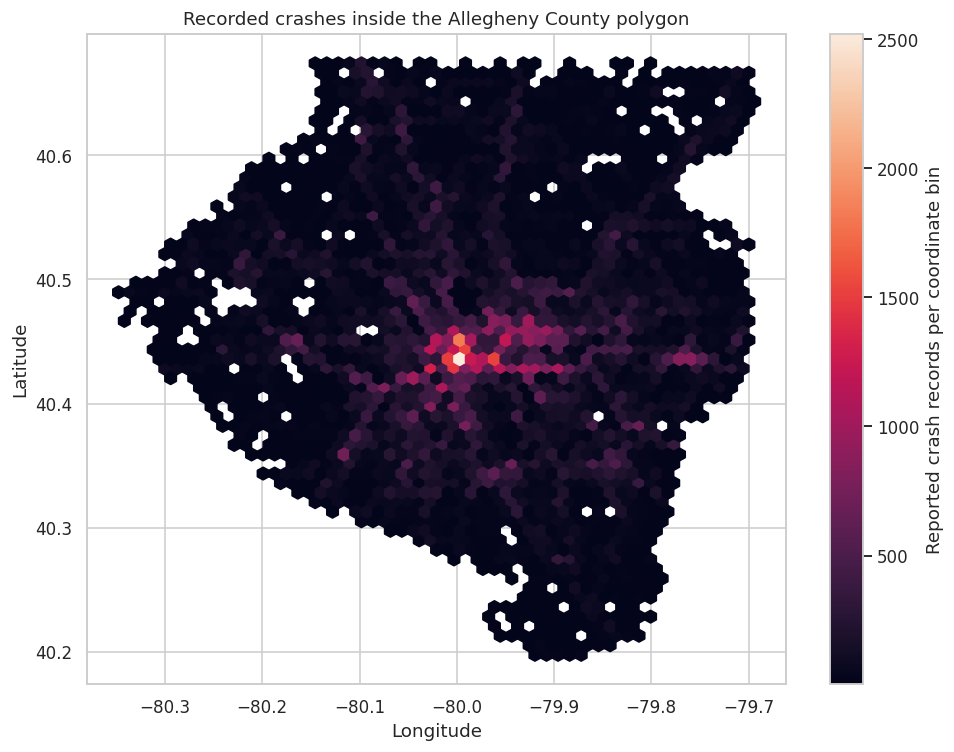

In [75]:
# Use the county polygon/coordinate-priority result from Section 13, not a rectangular extent.
geo = geo_county.rename(columns={"LAT": "DEC_LAT", "LON": "DEC_LONG"}).copy()
print(f"County-screened crash coordinates: {len(geo):,} of {len(df):,} crash records")
if len(geo):
    plt.figure(figsize=(9, 7))
    plt.hexbin(geo["DEC_LONG"], geo["DEC_LAT"], gridsize=55, mincnt=1)
    plt.colorbar(label="Reported crash records per coordinate bin")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title("Recorded crashes inside the Allegheny County polygon")
    plt.tight_layout()
    plt.show()
else:
    print("County hexbin skipped: no vetted points / polygon; no rectangular fallback.")


### 14.1 County-screened spatial layers and non-DBSCAN site screening

This section visualises recorded crashes within the actual Allegheny County boundary.

The analysis includes:

- Historical geographic concentration of all county-screened crashes.
- Serious/fatal crash concentration using only records with known severity.
- Pedestrian-related crash concentration.
- Multi-resolution grid screening to identify historically concentrated areas.

The original DBSCAN-based hotspot interpretation has been replaced with grid-based screening because density-connected clusters can combine large urban regions without identifying individual safety-priority locations.

Each crash is counted once in the corresponding spatial analysis. Placeholder coordinates and records without accepted locations are excluded.

**Important limitation:** These visualisations identify concentrations of recorded crashes. They do not measure exposure-adjusted road risk, and grid cells are not verified road segments or intersections.

Reliable site-level screening requires additional road-network matching and appropriate traffic-exposure information.

Spatial denominators: {'located_all': 238281, 'located_known_severity': 196745, 'located_unknown_severity': 41536, 'located_road_user_info': 238281}


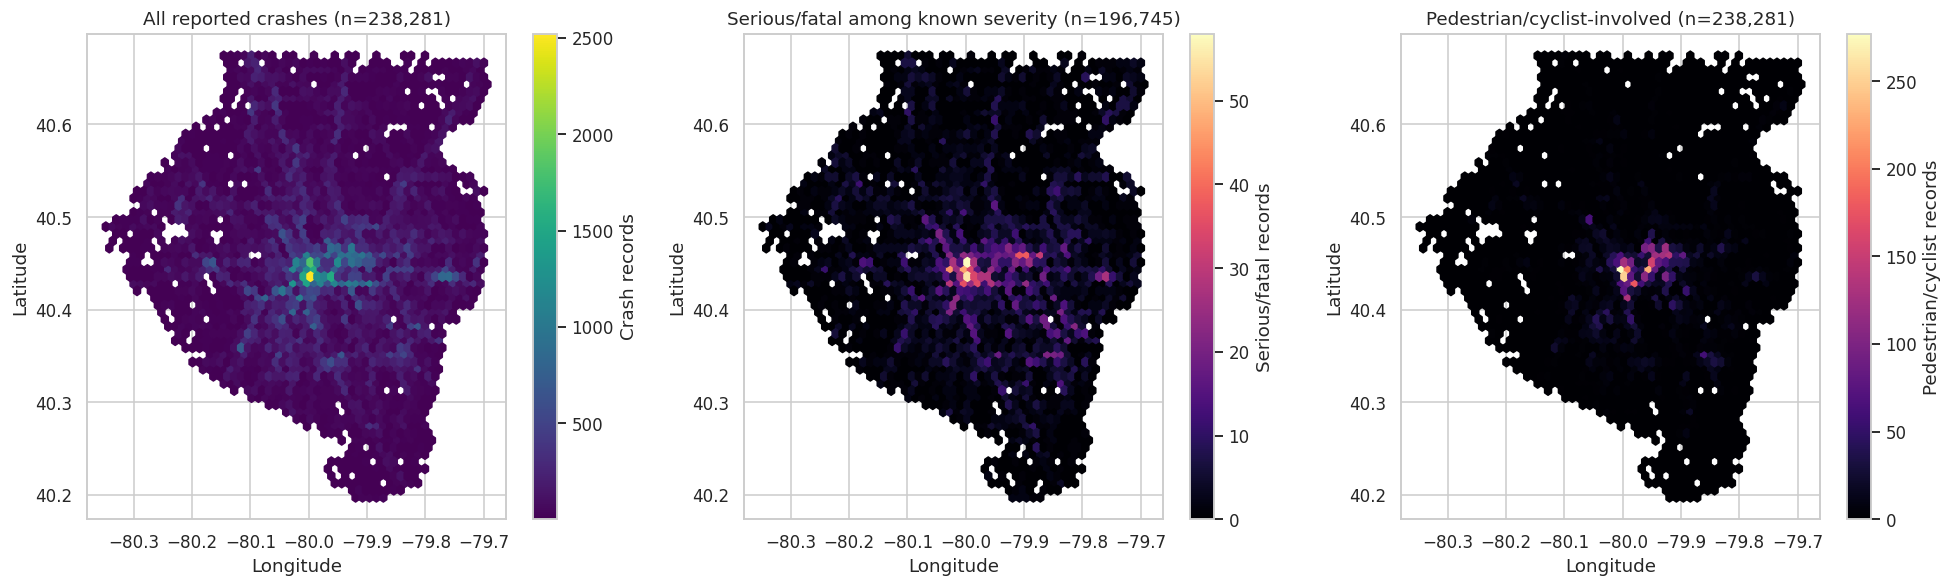

Largest recorded-crash grid cells at 2 decimal places:


,LAT_BIN,LON_BIN,crash_count,years_observed
823,40.44,-80.00,2409,21
824,40.44,-79.99,1957,21
883,40.45,-80.00,1897,21
822,40.44,-80.01,1828,21
761,40.43,-80.00,1667,21
827,40.44,-79.96,1469,21
888,40.45,-79.95,1374,21
765,40.43,-79.96,1234,21
758,40.43,-80.03,1170,21
825,40.44,-79.98,1144,21


Largest recorded-crash grid cells at 3 decimal places:


,LAT_BIN,LON_BIN,crash_count,years_observed
17921,40.444,-80.028,472,21
15041,40.429,-79.999,450,21
10464,40.396,-79.998,291,21
14478,40.426,-80.020,267,21
19081,40.450,-80.025,265,21
20007,40.454,-79.912,263,21
19952,40.454,-79.997,252,21
12412,40.411,-80.006,248,21
11219,40.402,-80.001,240,21
19145,40.450,-79.930,209,18


DBSCAN intentionally demoted: v5's dominant chained component is not a severity hotspot.


In [76]:
# Derive each layer from the SAME one-row-per-crash county-screened coordinates.
# Unknown severity is excluded from the serious/fatal denominator rather than set to 0.
geo_extended = geo_county.join(df[["SEVERE_OUTCOME", "COLLISION_LABEL",
                                    "PEDESTRIAN_INVOLVED", "BICYCLIST_INVOLVED"]], how="left")
geo_extended = geo_extended.copy()
known_geo = geo_extended.loc[geo_extended["SEVERE_OUTCOME"].notna()].copy()
known_geo["SEVERE_FLAG"] = known_geo["SEVERE_OUTCOME"].astype(int)
road_user_geo = geo_extended.loc[geo_extended["PEDESTRIAN_INVOLVED"].notna()
                                 | geo_extended["BICYCLIST_INVOLVED"].notna()].copy()
road_user_geo["VRU_FLAG"] = (
    road_user_geo["PEDESTRIAN_INVOLVED"].eq(1).fillna(False)
    | road_user_geo["BICYCLIST_INVOLVED"].eq(1).fillna(False)).astype(int)
print("Spatial denominators:", {
    "located_all": len(geo_extended), "located_known_severity": len(known_geo),
    "located_unknown_severity": len(geo_extended) - len(known_geo),
    "located_road_user_info": len(road_user_geo)})
if len(geo_extended):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    layers = [
        (geo_extended, None, "All reported crashes", "Crash records"),
        (known_geo, "SEVERE_FLAG", "Serious/fatal among known severity", "Serious/fatal records"),
        (road_user_geo, "VRU_FLAG", "Pedestrian/cyclist-involved", "Pedestrian/cyclist records")
    ]
    for ax, (layer_data, flag, title, colorbar_label) in zip(axes, layers):
        if layer_data.empty:
            ax.set(title=f"{title}: insufficient coverage")
            continue
        if flag is None:
            drawing = ax.hexbin(layer_data["LON"], layer_data["LAT"],
                                gridsize=55, mincnt=1, cmap="viridis")
        else:
            # sum of 0/1 flags = count, not an estimate of exposure-adjusted risk.
            drawing = ax.hexbin(layer_data["LON"], layer_data["LAT"],
                                C=layer_data[flag].to_numpy(),
                                reduce_C_function=np.sum, gridsize=55, mincnt=1, cmap="magma")
        fig.colorbar(drawing, ax=ax, label=colorbar_label)
        ax.set(title=f"{title} (n={len(layer_data):,})",
               xlabel="Longitude", ylabel="Latitude")
    plt.tight_layout()
    plt.show()

    # Coarse grid supports reproducible *historical concentration* screening.
    # It does not identify road segments and does not use DBSCAN's giant chained core.
    # 3 decimals represent ~100m latitude; bin-size sensitivity must be reviewed.
    for decimals in [2, 3]:
        counts = (geo_extended.assign(
            LAT_BIN=geo_extended["LAT"].round(decimals),
            LON_BIN=geo_extended["LON"].round(decimals))
            .groupby(["LAT_BIN", "LON_BIN"]).agg(
                crash_count=("CRASH_CRN", "nunique"),
                years_observed=("CRASH_YEAR", "nunique")
            ).reset_index().sort_values("crash_count", ascending=False))
        if decimals == 3:
            grid_screening = counts.copy()
        print(f"Largest recorded-crash grid cells at {decimals} decimal places:")
        display(counts.head(15))
else:
    grid_screening = pd.DataFrame()
    print("No validated county points: map and grid screening skipped.")
print("DBSCAN intentionally demoted: v5's dominant chained component is not a severity hotspot.")


## 15. Road-network and intersection attribution feasibility

A grid cell is not an intersection, and an individual crash must not be counted twice just because it lies near two roads. For the conditional count model, the preferred unit is **one unique `CRASH_CRN` allocated to exactly one reviewed `SITE_ID`**. The optional crosswalk `data/reference/street_centerlines/site_crosswalk.csv` must contain `ROUTE`, `SEGMENT`, `SITE_ID`, `SITE_TYPE` (`segment` or `intersection`) and `MATCH_QUALITY` (`verified`). Duplicate route/segment assignments are treated as **ambiguous**. Local street names alone are not sufficiently reliable to assign a site. Matching by proximity to a centerline requires reviewed geometry and distance thresholds and is **not** claimed here without the actual geometry.

In [77]:
# This makes the road-network gate quantitative without treating missing route data
# as failed matching. Only verified, unambiguous keys can support site-year modelling.
network_fields = [c for c in ["ROUTE", "SEGMENT", "OFFSET", "STREET_NAME",
                              "ROADWAY_COUNTY", "STATE_ROAD"] if c in df]
network_coverage = pd.DataFrame({
    "source_field": network_fields,
    "available_count": [int(df[c].notna().sum()) for c in network_fields],
    "percent_available": [round(100*df[c].notna().mean(), 2) for c in network_fields]
})
display(network_coverage)

def normalized_route_key(series):
    """Preserve leading zeroes and avoid joining a numeric 12 to an unrelated 0012."""
    return (series.astype("string").str.strip().str.upper()
            .replace({"": pd.NA, "NAN": pd.NA, "<NA>": pd.NA}))

site_crosswalk_path = REFERENCE_ROOT / "street_centerlines" / "site_crosswalk.csv"
crash_site_assignments = pd.DataFrame(columns=["CRASH_CRN", "CRASH_YEAR", "SITE_ID", "SITE_TYPE"])
site_match_audit = pd.DataFrame()
if site_crosswalk_path.is_file() and {"ROUTE", "SEGMENT"}.issubset(df):
    crosswalk = pd.read_csv(site_crosswalk_path, dtype="string")
    required_crosswalk = {"ROUTE", "SEGMENT", "SITE_ID", "SITE_TYPE", "MATCH_QUALITY"}
    if not required_crosswalk.issubset(crosswalk):
        print("Site crosswalk lacks required columns; no site assignment will be made:",
              sorted(required_crosswalk-set(crosswalk.columns)))
    else:
        for col in ["ROUTE", "SEGMENT"]:
            crosswalk[col] = normalized_route_key(crosswalk[col])
        cw_clean = crosswalk.loc[
            crosswalk["MATCH_QUALITY"].str.lower().eq("verified")
            & crosswalk["SITE_TYPE"].str.lower().isin(["segment", "intersection"])
        ].copy()
        ambiguity = cw_clean.duplicated(["ROUTE", "SEGMENT"], keep=False)
        cw_unique = cw_clean.loc[~ambiguity].drop_duplicates(["ROUTE", "SEGMENT"])
        src = df[["CRASH_CRN", "CRASH_YEAR", "ROUTE", "SEGMENT", "INTERSECT_TYPE"]].copy()
        for col in ["ROUTE", "SEGMENT"]:
            src[col] = normalized_route_key(src[col])
        matches = src.merge(cw_unique[["ROUTE", "SEGMENT", "SITE_ID", "SITE_TYPE"]],
                            on=["ROUTE", "SEGMENT"], how="left", validate="many_to_one")
        # A segment crash must be explicitly midblock (code 0); an intersection
        # crash must have a valid intersection code. Never assign both units.
        intersection_code = pd.to_numeric(matches["INTERSECT_TYPE"], errors="coerce")
        consistent = ((matches["SITE_TYPE"].eq("segment") & intersection_code.eq(0))
                      | (matches["SITE_TYPE"].eq("intersection")
                         & intersection_code.gt(0) & intersection_code.lt(99)))
        matched = matches.loc[matches["SITE_ID"].notna() & consistent,
                              ["CRASH_CRN", "CRASH_YEAR", "SITE_ID", "SITE_TYPE"]]
        # Enforce at-most-one site record per unique crash.
        if matched["CRASH_CRN"].duplicated().any():
            raise ValueError("A crash maps to multiple sites: unique attribution violated.")
        crash_site_assignments = matched.copy()
        site_match_audit = pd.DataFrame([
            {"status": "assigned_unique_site", "crashes": len(matched)},
            {"status": "unassigned_or_inconsistent", "crashes": len(df)-len(matched)},
            {"status": "ambiguous_crosswalk_keys", "crashes": int(ambiguity.sum())}
        ])
        print("Reviewed network crosswalk matching summary:")
        display(site_match_audit)
else:
    print("Site crosswalk or required route/segment fields absent: no network matching asserted.")


,source_field,available_count,percent_available
0,ROUTE,146488,58.88
1,SEGMENT,138584,55.70
2,OFFSET,152775,61.40
3,STREET_NAME,236494,95.05
4,ROADWAY_COUNTY,242653,97.53
5,STATE_ROAD,248809,100.00


Site crosswalk or required route/segment fields absent: no network matching asserted.


## 16. Severity-classifier training (post-crash versus restricted)

The original v4 Random Forest architecture is retained for continuity, with v6's required exclusions of unverified URBAN_RURAL and codebook groupings; results are therefore not numerically identical to the literal v4 benchmark. The stronger post-2016 model comparison is added in Section 21; it uses a consistent severity-definition period and adds collision type.

**Question:** using selected recorded conditions, can a model distinguish serious/fatal crashes from other crashes in a later time period?

The model is trained on 2004–2021 and tested on 2022–2024. This chronological split is more appropriate than randomly mixing earlier and later years when the aim is to test performance on later records.

Important limitations:
- Only crashes with known severity codes 0–4 are included.
- Features are recorded crash context, not necessarily information known before a crash.
- This is not a causal model and should not be presented as a system for preventing crashes.

### What this code does — preparing a chronological train/test split

This cell imports the scikit-learn tools needed for preprocessing, Random Forest classification and evaluation. It then chooses a small set of recorded crash-context features that will be used as model inputs.

Only records with a known binary severity outcome are retained. The data is split by year: 2004–2021 is the training period, while 2022–2024 is held back for testing. `X_train` and `X_test` contain the input features; `y_train` and `y_test` contain the outcome labels.

This chronological split tests whether a model trained on earlier records can classify records from later years. It avoids randomly mixing future years into the training set.

In [78]:
# Keep later years completely separate so the test set represents a future period.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, average_precision_score
)

model_features = [
    "CRASH_MONTH", "DAY_OF_WEEK", "SPEED_LIMIT_VALID",
    "WEATHER_GROUP", "ROAD_SURFACE_GROUP",
    "ROAD_RELATION_LABEL", "INTERSECTION_LABEL"
]
# Remove unverified historical code groups rather than silently estimating with disputed labels.
if not CODEBOOK_VERIFIED:
    model_features = [x for x in model_features if x not in {"WEATHER_GROUP", "ROAD_SURFACE_GROUP"}]
model_features = [col for col in model_features if col in df.columns]
print("Benchmark feature timing: retrospective crash circumstances; no target-derived fields or URBAN_RURAL.")

model_data = df.loc[
    df["SEVERE_OUTCOME"].notna(),
    ["CRASH_YEAR", "SEVERE_OUTCOME"] + model_features
].copy()
model_data["SEVERE_OUTCOME"] = model_data["SEVERE_OUTCOME"].astype(int)

train_mask = model_data["CRASH_YEAR"] <= 2021
test_mask = model_data["CRASH_YEAR"].between(2022, 2024)

X_train = model_data.loc[train_mask, model_features]
X_test = model_data.loc[test_mask, model_features]
y_train = model_data.loc[train_mask, "SEVERE_OUTCOME"]
y_test = model_data.loc[test_mask, "SEVERE_OUTCOME"]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Serious/fatal share in test set:", round(y_test.mean() * 100, 2), "%")

Benchmark feature timing: retrospective crash circumstances; no target-derived fields or URBAN_RURAL.
Training records: 177847
Testing records: 27697
Serious/fatal share in test set: 4.44 %


### What this code does — preprocessing, fitting and comparing the classifier

The code separates categorical features from the numeric speed-limit feature. Missing categorical values are filled with the most frequent category, then one-hot encoded so the model can use them without treating category labels as ordered numbers. Missing speed limits are filled with the training-set median.

`ColumnTransformer` applies the appropriate preprocessing to each feature type, and `Pipeline` connects preprocessing to the Random Forest. Keeping these steps in a pipeline ensures that imputation and encoding are fitted using the training data when `model.fit()` is called.

The fitted model predicts the test-set classes and probabilities. The baseline predicts the majority class (non-severe) for every test record. The final table compares baseline and model accuracy, balanced accuracy and average precision. This comparison is important because accuracy alone can be misleading when serious/fatal crashes are the minority class.

In [79]:
categorical_features = [col for col in model_features if col != "SPEED_LIMIT_VALID"]
numeric_features = [col for col in model_features if col == "SPEED_LIMIT_VALID"]

categorical_pipeline = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore"))
])
numeric_pipeline = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_pipeline, categorical_features),
    ("numeric", numeric_pipeline, numeric_features)
])

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

# A simple baseline predicts the majority class (non-severe) for every test record.
baseline_predictions = np.zeros(len(y_test), dtype=int)

results = pd.DataFrame([
    {
        "model": "Majority-class baseline",
        "accuracy": accuracy_score(y_test, baseline_predictions),
        "balanced_accuracy": balanced_accuracy_score(y_test, baseline_predictions),
        "average_precision": y_test.mean()
    },
    {
        "model": "Random Forest",
        "accuracy": accuracy_score(y_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_test, predictions),
        "average_precision": average_precision_score(y_test, probabilities)
    }
])
display(results.round(3))

,model,accuracy,balanced_accuracy,average_precision
0,Majority-class baseline,0.956,0.500,0.044
1,Random Forest,0.716,0.532,0.052


### 16.1 Post-2016 severity model comparison and ablation

The original v4 Random Forest remains above as a benchmark. This comparison focuses on 2016–2024 so the target uses the post-2016 injury-severity standard throughout. It holds out 2022–2024, compares Logistic Regression, Random Forest, and HistGradientBoosting, and tests whether adding `COLLISION_LABEL` improves the Random Forest. The feature set intentionally excludes injury counts and all direct outcome-derived fields; hour and illumination are omitted from the full-period test because they are structurally missing in 2024.

Evaluation includes average precision, ROC-AUC, balanced accuracy, Brier score, precision/recall at the top 5%, 10%, and 20% of ranked test records, a precision–recall curve, and a temporally calibrated Logistic Regression using validation years 2019–2021.

The model estimates severity conditional on a crash already being reported and its scene fields being recorded. It does not predict whether a crash will occur and is not a pre-crash warning system.

Restricted feature group: ['CRASH_MONTH', 'DAY_OF_WEEK', 'SPEED_LIMIT_VALID', 'ROAD_RELATION_LABEL', 'INTERSECTION_LABEL']
Retrospective/post-crash feature group: ['CRASH_MONTH', 'DAY_OF_WEEK', 'SPEED_LIMIT_VALID', 'ROAD_RELATION_LABEL', 'INTERSECTION_LABEL', 'COLLISION_LABEL']
Training years: 2016–2021
Testing years: 2022–2024
Training records: 58,660 | Test records: 27,697
Test serious/fatal prevalence: 4.44%


,model,test_records,test_prevalence_percent,average_precision,roc_auc,balanced_accuracy_at_0.50,brier_score_uncalibrated
3,HistGradientBoosting + collision,27697,4.4445,0.1548,0.6921,0.6333,0.2028
1,Random Forest + collision,27697,4.4445,0.1420,0.6900,0.6301,0.1711
0,Logistic Regression + collision,27697,4.4445,0.1393,0.6990,0.6381,0.2132
2,Random Forest without collision,27697,4.4445,0.0517,0.5461,0.5279,0.1995


Performance when reviewing only the highest-scored test records:


,model,top_percent_flagged,records_flagged,serious_fatal_found,precision_percent,recall_percent
0,Logistic Regression + collision,5,1385,295,21.30,23.96
1,Logistic Regression + collision,10,2770,398,14.37,32.33
2,Logistic Regression + collision,20,5540,560,10.11,45.49
3,Random Forest + collision,5,1385,302,21.81,24.53
4,Random Forest + collision,10,2770,404,14.58,32.82
5,Random Forest + collision,20,5540,551,9.95,44.76
6,Random Forest without collision,5,1385,79,5.70,6.42
7,Random Forest without collision,10,2770,158,5.70,12.84
8,Random Forest without collision,20,5540,297,5.36,24.13
9,HistGradientBoosting + collision,5,1385,310,22.38,25.18


Chronologically calibrated Logistic Regression:


,average_precision,roc_auc,brier_score
0,0.1373,0.6969,0.0405


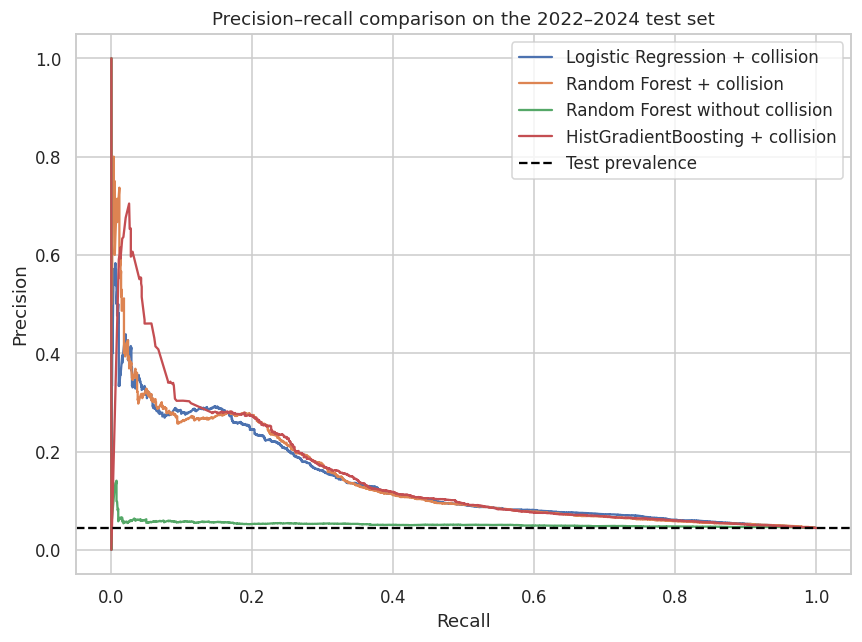

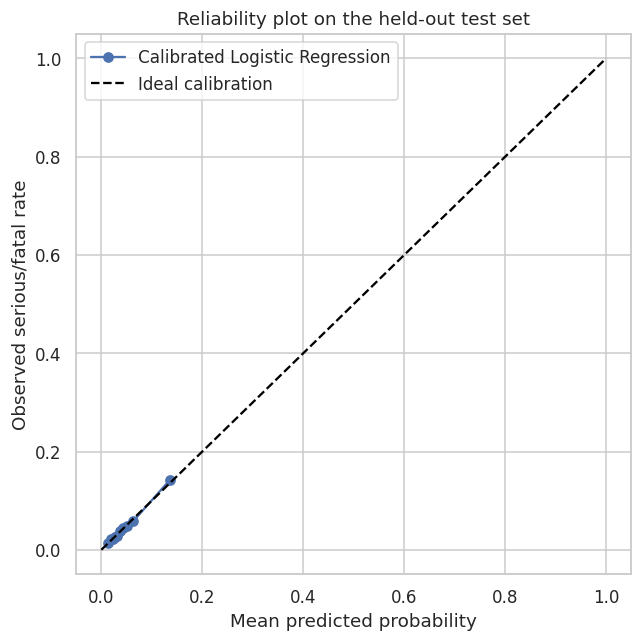

Permutation importance on a held-out test sample (larger AP drop = more useful to this model):


,source_feature,mean_average_precision_drop,std_average_precision_drop
5,COLLISION_LABEL,0.1042,0.0055
4,INTERSECTION_LABEL,0.0168,0.0107
2,SPEED_LIMIT_VALID,0.0157,0.0100
1,DAY_OF_WEEK,-0.0024,0.0016
0,CRASH_MONTH,-0.0034,0.0046
3,ROAD_RELATION_LABEL,-0.0055,0.0106


In [80]:
# Compare interpretable and nonlinear classifiers on one consistent post-2016 chronological split.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    average_precision_score, roc_auc_score, balanced_accuracy_score,
    brier_score_loss, precision_recall_curve
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
from sklearn.inspection import permutation_importance

# Use fields with broad coverage in the final test period; collision type is tested separately.
features_without_collision = [
    "CRASH_MONTH", "DAY_OF_WEEK", "SPEED_LIMIT_VALID", "WEATHER_GROUP",
    "ROAD_SURFACE_GROUP", "ROAD_RELATION_LABEL", "INTERSECTION_LABEL"
]
# Restrict unresolved historical codebook groups from training and inference.
if not CODEBOOK_VERIFIED:
    features_without_collision = [x for x in features_without_collision
                                  if x not in {"WEATHER_GROUP", "ROAD_SURFACE_GROUP"}]
features_with_collision = features_without_collision + ["COLLISION_LABEL"]
print("Restricted feature group:", features_without_collision)
print("Retrospective/post-crash feature group:", features_with_collision)
model_year = pd.to_numeric(df["CRASH_YEAR"], errors="coerce")
post_2016_model_data = df.loc[
    model_year.between(2016, 2024) & df["SEVERE_OUTCOME"].notna()
].copy()
post_2016_model_data["MODEL_YEAR"] = pd.to_numeric(
    post_2016_model_data["CRASH_YEAR"], errors="coerce"
).astype(int)

missing_model_features = [
    col for col in features_with_collision if col not in post_2016_model_data.columns
]
if missing_model_features:
    raise KeyError(f"Required model features are missing from the prepared dataset: {missing_model_features}")

train_frame = post_2016_model_data.loc[post_2016_model_data["MODEL_YEAR"] <= 2021].copy()
test_frame = post_2016_model_data.loc[post_2016_model_data["MODEL_YEAR"].between(2022, 2024)].copy()

if train_frame.empty or test_frame.empty or train_frame["SEVERE_OUTCOME"].nunique() < 2:
    print("The post-2016 chronological split does not contain enough records/classes to fit the enhanced models.")
else:
    y_train_enhanced = train_frame["SEVERE_OUTCOME"].astype(int).reset_index(drop=True)
    y_test_enhanced = test_frame["SEVERE_OUTCOME"].astype(int).reset_index(drop=True)

    def prepare_model_features(frame, feature_list):
        prepared = frame[feature_list].copy()
        for feature in feature_list:
            if feature == "SPEED_LIMIT_VALID":
                prepared[feature] = pd.to_numeric(prepared[feature], errors="coerce")
            else:
                prepared[feature] = prepared[feature].astype("string").fillna("Missing").astype(str)
        return prepared.reset_index(drop=True)

    X_train_enhanced = prepare_model_features(train_frame, features_with_collision)
    X_test_enhanced = prepare_model_features(test_frame, features_with_collision)
    X_train_ablation = prepare_model_features(train_frame, features_without_collision)
    X_test_ablation = prepare_model_features(test_frame, features_without_collision)

    def make_one_hot_encoder(dense=False):
        try:
            return OneHotEncoder(
                handle_unknown="ignore", min_frequency=25,
                sparse_output=not dense
            )
        except TypeError:
            try:
                return OneHotEncoder(
                    handle_unknown="ignore", min_frequency=25,
                    sparse=not dense
                )
            except TypeError:
                return OneHotEncoder(handle_unknown="ignore", sparse=not dense)

    def make_preprocessor(feature_list, dense=False):
        categorical = [col for col in feature_list if col != "SPEED_LIMIT_VALID"]
        numerical = [col for col in feature_list if col == "SPEED_LIMIT_VALID"]
        transformers = []
        if categorical:
            categorical_pipeline = Pipeline(steps=[
                ("impute", SimpleImputer(strategy="most_frequent")),
                ("one_hot", make_one_hot_encoder(dense=dense))
            ])
            transformers.append(("categorical", categorical_pipeline, categorical))
        if numerical:
            numeric_pipeline = Pipeline(steps=[
                ("impute", SimpleImputer(strategy="median")),
                ("scale", StandardScaler())
            ])
            transformers.append(("numeric", numeric_pipeline, numerical))
        return ColumnTransformer(
            transformers=transformers,
            remainder="drop",
            sparse_threshold=0.3
        )

    logistic_model = Pipeline(steps=[
        ("preprocess", make_preprocessor(features_with_collision)),
        ("classifier", LogisticRegression(
            max_iter=700, class_weight="balanced", solver="lbfgs", random_state=42
        ))
    ])
    random_forest_model = Pipeline(steps=[
        ("preprocess", make_preprocessor(features_with_collision)),
        ("classifier", RandomForestClassifier(
            n_estimators=180, min_samples_leaf=20,
            class_weight="balanced_subsample", random_state=42, n_jobs=-1
        ))
    ])
    random_forest_no_collision = Pipeline(steps=[
        ("preprocess", make_preprocessor(features_without_collision)),
        ("classifier", RandomForestClassifier(
            n_estimators=180, min_samples_leaf=20,
            class_weight="balanced_subsample", random_state=42, n_jobs=-1
        ))
    ])
    boosting_model = Pipeline(steps=[
        ("preprocess", make_preprocessor(features_with_collision, dense=True)),
        ("classifier", HistGradientBoostingClassifier(
            learning_rate=0.08, max_iter=160, max_leaf_nodes=31,
            min_samples_leaf=40, l2_regularization=1.0,
            early_stopping=True, random_state=42
        ))
    ])

    fitted_models = {}
    fitted_models["Logistic Regression + collision"] = logistic_model.fit(
        X_train_enhanced, y_train_enhanced
    )
    fitted_models["Random Forest + collision"] = random_forest_model.fit(
        X_train_enhanced, y_train_enhanced
    )
    fitted_models["Random Forest without collision"] = random_forest_no_collision.fit(
        X_train_ablation, y_train_enhanced
    )
    boosting_weights = compute_sample_weight("balanced", y_train_enhanced)
    fitted_models["HistGradientBoosting + collision"] = boosting_model.fit(
        X_train_enhanced, y_train_enhanced,
        classifier__sample_weight=boosting_weights
    )

    test_scores = {
        "Logistic Regression + collision": fitted_models["Logistic Regression + collision"].predict_proba(X_test_enhanced)[:, 1],
        "Random Forest + collision": fitted_models["Random Forest + collision"].predict_proba(X_test_enhanced)[:, 1],
        "Random Forest without collision": fitted_models["Random Forest without collision"].predict_proba(X_test_ablation)[:, 1],
        "HistGradientBoosting + collision": fitted_models["HistGradientBoosting + collision"].predict_proba(X_test_enhanced)[:, 1]
    }

    # Final test years are never used for fitting, calibration or hyperparameter selection.
    # Candidate hyperparameters below are carried from v5, not selected on test metrics.
    enhanced_rows = []
    for model_name, scores in test_scores.items():
        enhanced_rows.append({
            "model": model_name,
            "test_records": len(y_test_enhanced),
            "test_prevalence_percent": 100 * y_test_enhanced.mean(),
            "average_precision": average_precision_score(y_test_enhanced, scores),
            "roc_auc": roc_auc_score(y_test_enhanced, scores),
            "balanced_accuracy_at_0.50": balanced_accuracy_score(y_test_enhanced, scores >= 0.50),
            "brier_score_uncalibrated": brier_score_loss(y_test_enhanced, scores)
        })
    enhanced_results = pd.DataFrame(enhanced_rows).sort_values(
        "average_precision", ascending=False
    )
    print(f"Training years: {train_frame['MODEL_YEAR'].min()}–{train_frame['MODEL_YEAR'].max()}")
    print(f"Testing years: {test_frame['MODEL_YEAR'].min()}–{test_frame['MODEL_YEAR'].max()}")
    print(f"Training records: {len(train_frame):,} | Test records: {len(test_frame):,}")
    print(f"Test serious/fatal prevalence: {100 * y_test_enhanced.mean():.2f}%")
    display(enhanced_results.round(4))

    # Evaluate the share of the test set a safety team would review at fixed ranking budgets.
    top_k_rows = []
    for model_name, scores in test_scores.items():
        ordering = np.argsort(-scores)
        for flag_percent in [5, 10, 20]:
            top_n = max(1, int(np.ceil(len(scores) * flag_percent / 100)))
            selected = ordering[:top_n]
            true_positives = int(y_test_enhanced.iloc[selected].sum())
            top_k_rows.append({
                "model": model_name,
                "top_percent_flagged": flag_percent,
                "records_flagged": top_n,
                "serious_fatal_found": true_positives,
                "precision_percent": 100 * true_positives / top_n,
                "recall_percent": 100 * true_positives / int(y_test_enhanced.sum())
            })
    print("Performance when reviewing only the highest-scored test records:")
    display(pd.DataFrame(top_k_rows).round(2))

    # Calibrate Logistic Regression scores using strictly earlier training years to predict each validation year.
    calibration_splits = []
    train_year_values = train_frame["MODEL_YEAR"].to_numpy()
    for validation_year in [2019, 2020, 2021]:
        fit_indices = np.flatnonzero(train_year_values < validation_year)
        validation_indices = np.flatnonzero(train_year_values == validation_year)
        if len(fit_indices) and len(validation_indices):
            if y_train_enhanced.iloc[fit_indices].nunique() == 2 and y_train_enhanced.iloc[validation_indices].nunique() == 2:
                calibration_splits.append((fit_indices, validation_indices))

    calibrated_scores = None
    if len(calibration_splits) >= 2:
        calibrated_logistic = CalibratedClassifierCV(
            estimator=Pipeline(steps=[
                ("preprocess", make_preprocessor(features_with_collision)),
                ("classifier", LogisticRegression(
                    max_iter=700, class_weight="balanced", solver="lbfgs", random_state=42
                ))
            ]),
            method="sigmoid",
            cv=calibration_splits,
            ensemble=True
        )
        calibrated_logistic.fit(X_train_enhanced, y_train_enhanced)
        calibrated_scores = calibrated_logistic.predict_proba(X_test_enhanced)[:, 1]
        print("Chronologically calibrated Logistic Regression:")
        display(pd.DataFrame([{
            "average_precision": average_precision_score(y_test_enhanced, calibrated_scores),
            "roc_auc": roc_auc_score(y_test_enhanced, calibrated_scores),
            "brier_score": brier_score_loss(y_test_enhanced, calibrated_scores)
        }]).round(4))
    else:
        print("Temporal calibration skipped: fewer than two valid year-wise calibration folds were available.")

    # Plot precision–recall curves and the reliability of the temporally calibrated scores.
    plt.figure(figsize=(8, 6))
    for model_name, scores in test_scores.items():
        precision_values, recall_values, _ = precision_recall_curve(y_test_enhanced, scores)
        plt.plot(recall_values, precision_values, label=model_name)
    plt.axhline(y_test_enhanced.mean(), color="black", linestyle="--", label="Test prevalence")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision–recall comparison on the 2022–2024 test set")
    plt.legend()
    plt.tight_layout()
    plt.show()

    if calibrated_scores is not None:
        observed_rate, mean_probability = calibration_curve(
            y_test_enhanced, calibrated_scores, n_bins=10, strategy="quantile"
        )
        plt.figure(figsize=(6, 6))
        plt.plot(mean_probability, observed_rate, marker="o", label="Calibrated Logistic Regression")
        plt.plot([0, 1], [0, 1], linestyle="--", color="black", label="Ideal calibration")
        plt.xlabel("Mean predicted probability")
        plt.ylabel("Observed serious/fatal rate")
        plt.title("Reliability plot on the held-out test set")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # Measure each source field's contribution by how much test average precision falls when it is shuffled.
    permutation_sample_size = min(2500, len(X_test_enhanced))
    permutation_sample = X_test_enhanced.sample(
        n=permutation_sample_size, random_state=42
    )
    permutation_targets = y_test_enhanced.loc[permutation_sample.index]
    if permutation_targets.nunique() == 2:
        permutation_result = permutation_importance(
            fitted_models["Random Forest + collision"],
            permutation_sample,
            permutation_targets,
            scoring="average_precision",
            n_repeats=3,
            random_state=42,
            n_jobs=-1
        )
        permutation_summary = pd.DataFrame({
            "source_feature": features_with_collision,
            "mean_average_precision_drop": permutation_result.importances_mean,
            "std_average_precision_drop": permutation_result.importances_std
        }).sort_values("mean_average_precision_drop", ascending=False)
        print("Permutation importance on a held-out test sample (larger AP drop = more useful to this model):")
        display(permutation_summary.round(4))
    else:
        print("Permutation importance skipped because the sampled test records contain only one outcome class.")


## 17. Severity-model evaluation and temporal uncertainty

The classification report gives precision, recall and F1-score for each outcome class, along with overall summaries. These metrics help show whether the model identifies serious/fatal crashes rather than simply predicting the more common class.

The confusion matrix compares actual test labels with predicted labels. Its cells show correct and incorrect predictions for each class. In particular, the serious/fatal row/column helps reveal how many serious/fatal cases were missed or correctly identified. These results apply only to the held-out 2022–2024 records and should be interpreted as a limited educational modelling exercise.

Classification report for the Random Forest:
                      precision    recall  f1-score   support

Other known severity       0.96      0.73      0.83     26466
       Serious/fatal       0.05      0.33      0.09      1231

            accuracy                           0.72     27697
           macro avg       0.51      0.53      0.46     27697
        weighted avg       0.92      0.72      0.80     27697



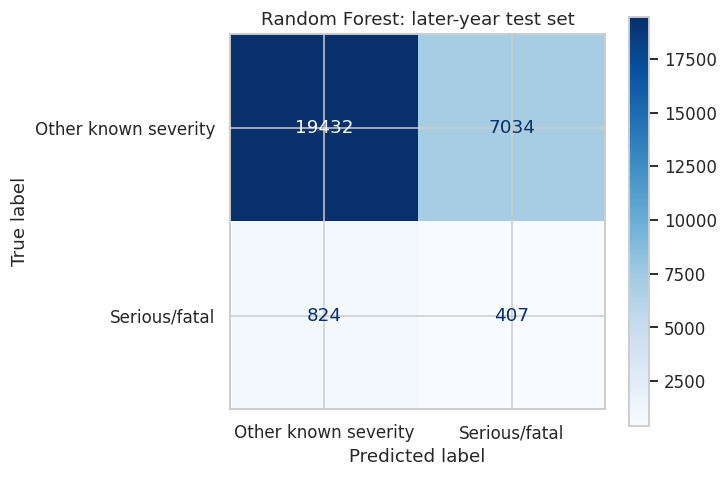

In [81]:
print("Classification report for the Random Forest:")
print(classification_report(
    y_test, predictions,
    target_names=["Other known severity", "Serious/fatal"],
    zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, predictions),
    display_labels=["Other known severity", "Serious/fatal"]
).plot(cmap="Blues", values_format="d")
plt.title("Random Forest: later-year test set")
plt.tight_layout()
plt.show()

The enhanced classifiers report **average precision (primary for the rare severe class)**, ROC-AUC, balanced accuracy at the *fixed illustrative* 0.50 threshold, and probability-calibration scores. Balanced accuracy close to 0.50 is approximately chance-level; values around 0.63 are modest improvements, not strong discrimination. For models trained using class weights, 0.50 is **not** an automatically validated policy threshold, and their uncalibrated probability scores need calibration before interpretation. The 2022–2024 test window has already been evaluated in v5 and v6 work; it is chronological but **not a wholly new external validation sample**. Do not choose hyperparameters or a threshold to maximise this test window.


Constant training-prevalence predictor = 0.0406; held-out Brier score = 0.04248


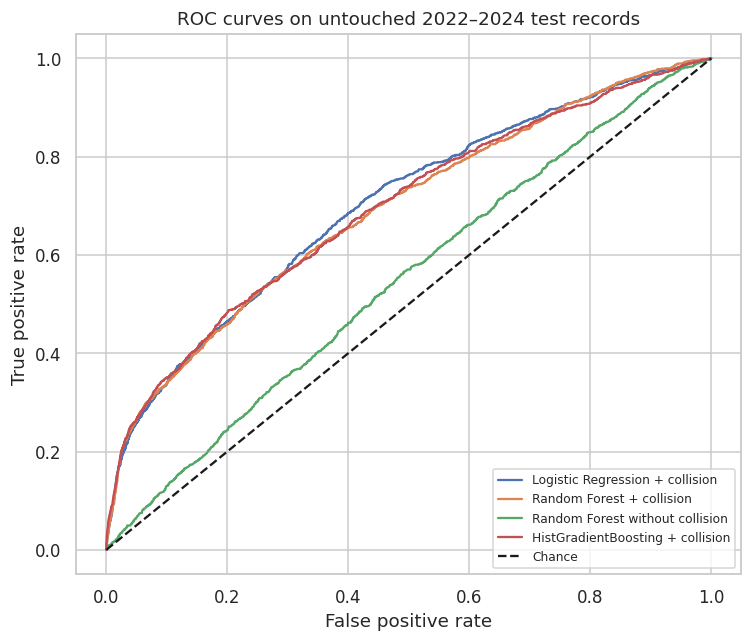

,model,threshold,tn,fp,fn,tp,precision,recall,f1,brier
0,Logistic Regression + collision,0.5,18382,8084,515,716,0.0814,0.5816,0.1428,0.2132
1,Random Forest + collision,0.5,21293,5173,670,561,0.0978,0.4557,0.1611,0.1711
2,Random Forest without collision,0.5,19001,7465,815,416,0.0528,0.3379,0.0913,0.1995
3,HistGradientBoosting + collision,0.5,18322,8144,524,707,0.0799,0.5743,0.1402,0.2028


Year-month block bootstrap 95% percentile AP intervals (descriptive):


,model,ap_2_5_percentile,ap_97_5_percentile,valid_block_replicates
0,Logistic Regression + collision,0.1216,0.1606,300
1,Random Forest + collision,0.1256,0.1621,300
2,Random Forest without collision,0.0471,0.0587,300
3,HistGradientBoosting + collision,0.1320,0.1810,300


Paired HistGB minus RF mean AP difference, 95% block interval: 0.0123 (np.float64(0.0031), np.float64(0.0225))


In [82]:
# Reuse v5 fitted models/results; do not refit against or tune on the test period.
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, mean_squared_error)

if "test_scores" not in globals() or "y_test_enhanced" not in globals():
    print("Enhanced model evaluation skipped: training did not produce held-out scores.")
else:
    train_prevalence = float(y_train_enhanced.mean())
    constant_baseline = np.full(len(y_test_enhanced), train_prevalence)
    brier_baseline = brier_score_loss(y_test_enhanced, constant_baseline)
    print(f"Constant training-prevalence predictor = {train_prevalence:.4f}; "
          f"held-out Brier score = {brier_baseline:.5f}")
    threshold_rows = []
    fig, ax = plt.subplots(figsize=(7, 6))
    for name, score in test_scores.items():
        hard = (np.asarray(score) >= 0.50).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test_enhanced, hard, labels=[0, 1]).ravel()
        threshold_rows.append({
            "model": name, "threshold": 0.5, "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "precision": precision_score(y_test_enhanced, hard, zero_division=0),
            "recall": recall_score(y_test_enhanced, hard, zero_division=0),
            "f1": f1_score(y_test_enhanced, hard, zero_division=0),
            "brier": brier_score_loss(y_test_enhanced, score)
        })
        fpr, tpr, _ = roc_curve(y_test_enhanced, score)
        ax.plot(fpr, tpr, label=name)
    ax.plot([0, 1], [0, 1], "k--", label="Chance")
    ax.set(xlabel="False positive rate", ylabel="True positive rate",
           title="ROC curves on untouched 2022–2024 test records")
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()
    threshold_results = pd.DataFrame(threshold_rows)
    display(threshold_results.round(4))

    # The public data do not provide exact crash dates. Year-month blocks are the
    # finest defensible temporal resampling units; never bootstrap crash rows iid.
    test_months = pd.to_numeric(test_frame["CRASH_MONTH"], errors="coerce").fillna(0).astype(int)
    block_id = (test_frame["MODEL_YEAR"].astype(int).astype(str) + "-"
                + test_months.astype(str).str.zfill(2)).reset_index(drop=True)
    groups = {key: np.flatnonzero(block_id.to_numpy() == key)
              for key in sorted(block_id.unique())}
    rng = np.random.default_rng(RANDOM_SEED)
    names = list(test_scores.keys())
    boot = []
    for repeat in range(300):
        chosen_blocks = rng.choice(list(groups), size=len(groups), replace=True)
        selected_rows = np.concatenate([groups[b] for b in chosen_blocks])
        yy = y_test_enhanced.iloc[selected_rows].to_numpy()
        if yy.min() == yy.max():
            continue
        row = {"iteration": repeat}
        for name in names:
            ss = np.asarray(test_scores[name])[selected_rows]
            row[name] = average_precision_score(yy, ss)
        boot.append(row)
    boot_frame = pd.DataFrame(boot)
    temporal_ap_intervals = pd.DataFrame([
        {"model": name, "ap_2_5_percentile": boot_frame[name].quantile(.025),
         "ap_97_5_percentile": boot_frame[name].quantile(.975),
         "valid_block_replicates": len(boot_frame)} for name in names
    ]) if len(boot_frame) else pd.DataFrame()
    print("Year-month block bootstrap 95% percentile AP intervals (descriptive):")
    display(temporal_ap_intervals.round(4))

    # Compare the two post-crash nonlinear models using paired block draws.
    # The 95% interval of an AP difference is more informative than point rankings.
    if len(boot_frame) and {"HistGradientBoosting + collision",
                            "Random Forest + collision"}.issubset(boot_frame):
        delta = (boot_frame["HistGradientBoosting + collision"]
                 - boot_frame["Random Forest + collision"])
        print("Paired HistGB minus RF mean AP difference, 95% block interval:",
              round(float(delta.mean()), 4),
              tuple(np.round(delta.quantile([.025, .975]).to_numpy(), 4)))


### 17.1 Supplementary unsupervised crash archetypes — evidence gate

MiniBatch K-Means is applied to a mixed feature representation: categorical crash context is one-hot encoded and the numeric speed-limit field is imputed and standardised. The model-selection check compares candidate cluster counts using a sampled silhouette score. Severity is excluded from clustering and is only used afterward to profile the discovered groups. The primary analysis uses 2016–2023 so the profiles are not dominated by the structural 2024 hour/illumination gap.

An additional independently seeded partition is compared through a sampled **adjusted Rand index (ARI)**. The groups stay supplementary regardless of their score; neither silhouette nor ARI proves geographic site risk.


Candidate cluster-count comparison:


,candidate_clusters,sampled_silhouette_score,fit_records,evaluation_sample_records
0,4,0.1172,60000,2500
1,6,0.0933,60000,2500
2,8,0.0848,60000,2500


Exploratory cluster stability (sampled adjusted Rand index): 0.826
Interpret clusters only as descriptive patterns; do not use for site screening or risk assessment.
Selected initial cluster count: 4
Cluster profiles; severity is measured after clustering, not used to form clusters:


,crash_records,known_severity_records,serious_fatal_records,serious_fatal_percent,top_COLLISION_LABEL,top_ILLUMINATION_LABEL,top_TIME_PERIOD
CRASH_ARCHETYPE,,,,,,,
0,19776,16253,829.0,5.10,Fixed object (94.4%),Daylight (46.6%),Night (36.6%)
1,17472,14881,470.0,3.16,Rear-end (47.0%),Daylight (62.6%),Morning (30.8%)
2,38811,32075,1180.0,3.68,Angle (45.0%),Daylight (97.5%),Afternoon (49.0%)
3,17603,14267,754.0,5.28,Angle (36.3%),Dark: streetlights (86.4%),Night (54.8%)


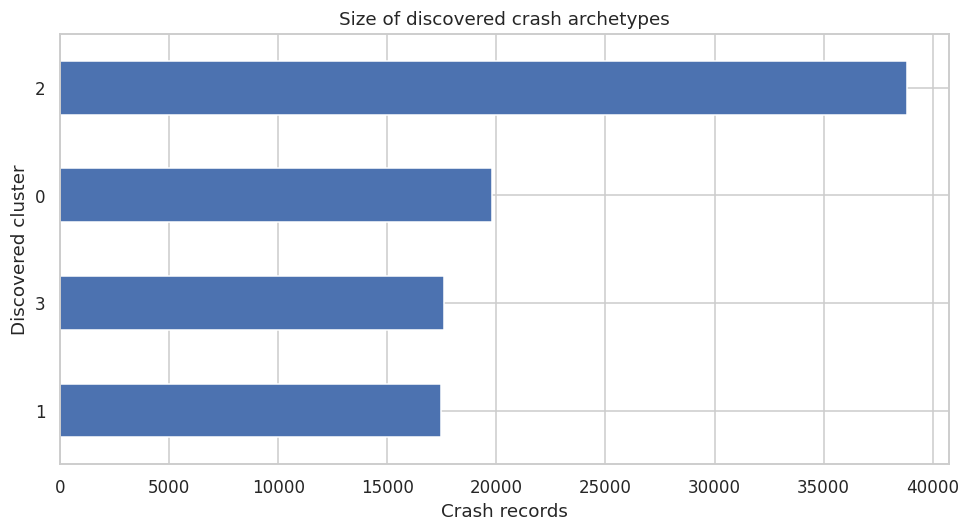

In [83]:
# Discover recurring crash-context profiles without using severity as a clustering input.
archetype_columns = [
    "CRASH_MONTH", "DAY_OF_WEEK", "SPEED_LIMIT_VALID", "WEATHER_GROUP",
    "ROAD_SURFACE_GROUP", "ILLUMINATION_LABEL", "TIME_PERIOD",
    "COLLISION_LABEL", "ROAD_RELATION_LABEL", "INTERSECTION_LABEL"
]
# Exclude unverified weather/surface categories before unsupervised encoding.
if not CODEBOOK_VERIFIED:
    archetype_columns = [x for x in archetype_columns
                         if x not in {"WEATHER_GROUP", "ROAD_SURFACE_GROUP"}]
archetype_year = pd.to_numeric(df["CRASH_YEAR"], errors="coerce")
archetype_frame = df.loc[archetype_year.between(2016, 2023), archetype_columns + ["SEVERE_OUTCOME"]].copy()

for feature in archetype_columns:
    if feature == "SPEED_LIMIT_VALID":
        archetype_frame[feature] = pd.to_numeric(archetype_frame[feature], errors="coerce")
    else:
        archetype_frame[feature] = archetype_frame[feature].astype("string").fillna("Missing").astype(str)

archetype_categorical = [col for col in archetype_columns if col != "SPEED_LIMIT_VALID"]
archetype_numeric = ["SPEED_LIMIT_VALID"]
archetype_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", Pipeline(steps=[
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("one_hot", make_one_hot_encoder(dense=False))
        ]), archetype_categorical),
        ("numeric", Pipeline(steps=[
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), archetype_numeric)
    ],
    sparse_threshold=0.3
)

if len(archetype_frame) < 100:
    print("Too few post-2016 records are available for meaningful crash archetype clustering.")
else:
    archetype_matrix = archetype_preprocessor.fit_transform(archetype_frame[archetype_columns])
    rng = np.random.default_rng(42)
    fit_size = min(60000, archetype_matrix.shape[0])
    fit_indices = rng.choice(archetype_matrix.shape[0], size=fit_size, replace=False)
    silhouette_size = min(2500, archetype_matrix.shape[0])
    silhouette_indices = rng.choice(archetype_matrix.shape[0], size=silhouette_size, replace=False)
    cluster_choice_rows = []
    candidate_models = {}

    for cluster_count in [4, 6, 8]:
        candidate_model = MiniBatchKMeans(
            n_clusters=cluster_count, random_state=42,
            batch_size=4096, n_init=5, max_iter=100
        )
        candidate_model.fit(archetype_matrix[fit_indices])
        sample_labels = candidate_model.predict(archetype_matrix[silhouette_indices])
        if len(np.unique(sample_labels)) > 1:
            silhouette_value = silhouette_score(
                archetype_matrix[silhouette_indices], sample_labels, metric="euclidean"
            )
        else:
            silhouette_value = np.nan
        cluster_choice_rows.append({
            "candidate_clusters": cluster_count,
            "sampled_silhouette_score": silhouette_value,
            "fit_records": fit_size,
            "evaluation_sample_records": silhouette_size
        })
        candidate_models[cluster_count] = candidate_model

    cluster_choice = pd.DataFrame(cluster_choice_rows).sort_values(
        "sampled_silhouette_score", ascending=False
    )
    print("Candidate cluster-count comparison:")
    display(cluster_choice.round(4))

    # v5 sampled silhouette scores were ~0.07, too weak for a firm archetype claim.
    # A minimum signal gate prevents weak partitions becoming misleading findings.
    valid_cluster_choices = cluster_choice.dropna(
        subset=["sampled_silhouette_score"])
    valid_cluster_choices = valid_cluster_choices.loc[
        valid_cluster_choices["sampled_silhouette_score"] >= 0.10]
    if len(valid_cluster_choices):
        selected_k = int(valid_cluster_choices.iloc[0]["candidate_clusters"])
        archetype_model = MiniBatchKMeans(
            n_clusters=selected_k, random_state=42,
            batch_size=4096, n_init=5, max_iter=100
        )
        archetype_model.fit(archetype_matrix)
        # A silhouette around 0.1 is weak. Check whether a second independent
        # random initialisation assigns similar cases to the same partition.
        # ARI is label-permutation invariant: 1 = identical partitions, ~0 =
        # chance-level agreement. This is an exploratory *stability diagnostic*,
        # not a claim that these groups correspond to true roadway risk types.
        from sklearn.metrics import adjusted_rand_score
        stability_replicate = MiniBatchKMeans(
            n_clusters=selected_k, random_state=RANDOM_SEED + 17,
            batch_size=4096, n_init=5, max_iter=100
        )
        stability_replicate.fit(archetype_matrix[fit_indices])
        stability_sample = archetype_matrix[silhouette_indices]
        stability_ari = adjusted_rand_score(
            archetype_model.predict(stability_sample),
            stability_replicate.predict(stability_sample)
        )
        print(f"Exploratory cluster stability (sampled adjusted Rand index): {stability_ari:.3f}")
        print("Interpret clusters only as descriptive patterns; do not use for site screening or risk assessment.")
        archetype_frame["CRASH_ARCHETYPE"] = archetype_model.labels_

        archetype_summary = archetype_frame.groupby("CRASH_ARCHETYPE").agg(
            crash_records=("SEVERE_OUTCOME", "size"),
            known_severity_records=("SEVERE_OUTCOME", "count"),
            serious_fatal_records=("SEVERE_OUTCOME", "sum"),
            serious_fatal_share=("SEVERE_OUTCOME", "mean")
        )
        archetype_summary["serious_fatal_percent"] = 100 * archetype_summary["serious_fatal_share"]

        # Profile clusters using only the columns available in archetype_frame.
        # Weather and road-surface groups may have been excluded earlier because
        # their historical codebook mappings have not yet been verified.
        #
        # This filtering ensures that excluded features are not accidentally
        # requested during post-clustering profiling, preventing KeyError.

        candidate_profile_columns = [
            "COLLISION_LABEL",
            "WEATHER_GROUP",
            "ROAD_SURFACE_GROUP",
            "ILLUMINATION_LABEL",
            "TIME_PERIOD"
        ]

        # Keep only columns actually present in the clustering DataFrame.
        available_profile_columns = [
            col for col in candidate_profile_columns
            if col in archetype_frame.columns
        ]

        for profile_column in available_profile_columns:

            profile_parts = []

            for cluster_id, group in archetype_frame.groupby("CRASH_ARCHETYPE"):

                # Identify the most frequently occurring category in each cluster.
                distribution = group[profile_column].value_counts(normalize=True)

                # Skip empty distributions to prevent indexing errors.
                if distribution.empty:
                    continue

                most_common = distribution.index[0]

                profile_parts.append({
                    "CRASH_ARCHETYPE": cluster_id,
                    f"top_{profile_column}": (
                        f"{most_common} ({100 * distribution.iloc[0]:.1f}%)"
                    )
                })

            # Append the available cluster profiles to the summary table.
            if profile_parts:
                archetype_summary = archetype_summary.join(
                    pd.DataFrame(profile_parts).set_index("CRASH_ARCHETYPE")
                )

        print(f"Selected initial cluster count: {selected_k}")
        print("Cluster profiles; severity is measured after clustering, not used to form clusters:")
        display(archetype_summary.drop(columns=["serious_fatal_share"]).round(2))

        plt.figure(figsize=(9, 5))
        archetype_summary["crash_records"].sort_values().plot(kind="barh")
        plt.xlabel("Crash records")
        plt.ylabel("Discovered cluster")
        plt.title("Size of discovered crash archetypes")
        plt.tight_layout()
        plt.show()
    else:
        print("No partition passed the minimum silhouette 0.10 exploratory gate; "
              "v5 archetypes remain unvalidated and are not prioritisation evidence.")


## 18. Conditional site-year crash-frequency modelling — distinct Task B

**Mandatory go/no-go gate:** This is **not** a crash-level classifier. Training requires (i) all eligible sites with explicit site type, (ii) a unique reviewed crash-to-site crosswalk, (iii) an annual site **exposure panel including sites with zero observed crashes**, (iv) positive AADT and site length, and (v) year-aligned roadway classes. For a repeatable workflow, put `data/reference/traffic_counts/site_year_exposure.csv` with columns `SITE_ID,CRASH_YEAR,SITE_TYPE,AADT,SEGMENT_LENGTH_MI,FACILITY_TYPE`. Each eligible `SITE_ID` must have one row for **every year 2016–2024**. Intersection exposure requires a specific reviewed measure and is **not** approximated by segment length × AADT; this first model fits **segment-only** observations.

Train on 2016–2021; hold 2022–2024 out. Fit Poisson as baseline; fit a Negative Binomial alternative only if observed training dispersion warrants it. Evaluate MAE, RMSE, mean Poisson deviance and total-count calibration on held-out site-years. Do not select a favourable model from held-out statistics. Without the complete panel, report coverage and historical counts (not per-driver risk) and **skip** frequency model training.

In [84]:
# Task B input is intentionally OPTIONAL. Grouping just the observed crashes
# could never supply the zero-count roads needed for a frequency model.
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance
from scipy.stats import poisson
site_panel = pd.DataFrame()
site_count_model = None
site_model_metrics = pd.DataFrame()
site_predictions = pd.DataFrame()
site_frequency_gate = False
exposure_path = REFERENCE_ROOT / "traffic_counts" / "site_year_exposure.csv"

if not exposure_path.is_file() or crash_site_assignments.empty:
    print("Task B SKIPPED: approved complete site-year exposure and/or unique reviewed site allocation missing.")
    if not crash_site_assignments.empty:
        print("Historical site counts only; NOT exposure-adjusted estimates:")
        display(crash_site_assignments.groupby("SITE_ID")["CRASH_CRN"].nunique()
                .sort_values(ascending=False).head(20).to_frame("reported_crashes"))
else:
    external_panel = pd.read_csv(exposure_path, dtype={"SITE_ID": "string", "SITE_TYPE": "string",
                                                       "FACILITY_TYPE": "string"})
    panel_fields = {"SITE_ID", "CRASH_YEAR", "SITE_TYPE", "AADT", "SEGMENT_LENGTH_MI", "FACILITY_TYPE"}
    if not panel_fields.issubset(external_panel):
        print("Task B SKIPPED: missing exposure columns:", sorted(panel_fields-set(external_panel.columns)))
    else:
        # Only explicitly reviewed segment sites can use a vehicle-miles exposure.
        external_panel["CRASH_YEAR"] = pd.to_numeric(external_panel["CRASH_YEAR"], errors="coerce")
        external_panel["AADT"] = pd.to_numeric(external_panel["AADT"], errors="coerce")
        external_panel["SEGMENT_LENGTH_MI"] = pd.to_numeric(
            external_panel["SEGMENT_LENGTH_MI"], errors="coerce")
        eligible = external_panel.loc[external_panel["SITE_TYPE"].str.lower().eq("segment")].copy()
        eligible = eligible.loc[eligible["CRASH_YEAR"].between(2016, 2024)]
        years_per_site = eligible.groupby("SITE_ID")["CRASH_YEAR"].agg(["nunique", "size"])
        complete_sites = years_per_site.index[(years_per_site["nunique"] == 9)
                                                   & (years_per_site["size"] == 9)]
        eligible = eligible.loc[eligible["SITE_ID"].isin(complete_sites)].copy()
        positive = eligible["AADT"].gt(0) & eligible["SEGMENT_LENGTH_MI"].gt(0)
        if (eligible.empty or not positive.all() or eligible["FACILITY_TYPE"].isna().any()
                or eligible.duplicated(["SITE_ID", "CRASH_YEAR"]).any()):
            print("Task B SKIPPED: incomplete site/year coverage, duplicate keys, "
                  "missing facility class or nonpositive AADT/length.")
        else:
            # Attribution is unique by CRN; retain only the reviewed segment allocation.
            assigned = crash_site_assignments.loc[
                crash_site_assignments["SITE_TYPE"].eq("segment")].copy()
            assigned["CRASH_YEAR"] = pd.to_numeric(assigned["CRASH_YEAR"], errors="coerce")
            assigned["SITE_ID"] = assigned["SITE_ID"].astype("string")
            observed_counts = assigned.groupby(["SITE_ID", "CRASH_YEAR"])["CRASH_CRN"].nunique()
            observed_counts.name = "OBSERVED_CRASHES"
            # Left join starts from ALL eligible sites/years, preserving true zero counts.
            site_panel = eligible.join(observed_counts, on=["SITE_ID", "CRASH_YEAR"])
            site_panel["OBSERVED_CRASHES"] = site_panel["OBSERVED_CRASHES"].fillna(0).astype(int)
            site_panel["VEHICLE_MILES_PROXY"] = (
                site_panel["AADT"] * 365.25 * site_panel["SEGMENT_LENGTH_MI"])
            if site_panel["VEHICLE_MILES_PROXY"].le(0).any():
                raise ValueError("Invalid exposure proxy after gate; no model trained.")
            print("Eligible observed 0-crash site-years:",
                  int(site_panel["OBSERVED_CRASHES"].eq(0).sum()),
                  "of", len(site_panel), "site-years")
            train_site = site_panel["CRASH_YEAR"].le(2021)
            test_site = site_panel["CRASH_YEAR"].ge(2022)
            if train_site.sum() < 30 or test_site.sum() < 10:
                print("Task B SKIPPED: not enough site-year records for a defensible fit/holdout.")
            else:
                # Feature encoding uses only roadway facility class, not outcomes.
                import statsmodels.api as sm
                facility_levels = pd.get_dummies(
                    site_panel["FACILITY_TYPE"], prefix="class", dtype=float)
                x_all = sm.add_constant(facility_levels, has_constant="add")
                # Remove one class column to avoid exact collinearity with intercept.
                x_all = x_all.drop(columns=facility_levels.columns[:1].tolist())
                x_train, x_test = x_all.loc[train_site], x_all.loc[test_site]
                y_train_site = site_panel.loc[train_site, "OBSERVED_CRASHES"]
                y_test_site = site_panel.loc[test_site, "OBSERVED_CRASHES"]
                train_offset = np.log(site_panel.loc[train_site, "VEHICLE_MILES_PROXY"])
                test_offset = np.log(site_panel.loc[test_site, "VEHICLE_MILES_PROXY"])
                site_count_model = sm.GLM(y_train_site, x_train,
                                          family=sm.families.Poisson(),
                                          offset=train_offset).fit(maxiter=200)
                mean_train = site_count_model.fittedvalues.clip(lower=1e-9)
                dispersion = float((((y_train_site - mean_train)**2 / mean_train).sum()
                                    / max(1, len(y_train_site)-len(site_count_model.params))))
                print("Poisson train Pearson dispersion:", round(dispersion, 3))
                poisson_pred = np.clip(site_count_model.predict(x_test, offset=test_offset), 1e-8, None)
                candidates = {"Poisson": poisson_pred}
                if dispersion > 1.5:
                    # NB alpha is estimated from the training subset, never from test outcomes.
                    try:
                        nb_fit = sm.NegativeBinomial(
                            y_train_site, x_train, offset=train_offset).fit(
                                disp=False, maxiter=250)
                        nb_predict = np.clip(nb_fit.predict(x_test, offset=test_offset), 1e-8, None)
                        candidates["Negative Binomial"] = nb_predict
                        print("NB train-derived dispersion alpha:",
                              float(nb_fit.params.get("alpha", np.nan)))
                    except Exception as nb_error:
                        print("NB challenger unavailable:", type(nb_error).__name__, str(nb_error)[:200])
                records = []
                for name, prediction in candidates.items():
                    records.append({
                        "model": name, "train_siteyears": int(train_site.sum()),
                        "test_siteyears": int(test_site.sum()),
                        "mae": mean_absolute_error(y_test_site, prediction),
                        "rmse": np.sqrt(mean_squared_error(y_test_site, prediction)),
                        "mean_poisson_deviance": mean_poisson_deviance(y_test_site, prediction),
                        "predicted_to_observed_total": float(prediction.sum() / max(1, y_test_site.sum()))
                    })
                site_model_metrics = pd.DataFrame(records)
                print("Held-out site-year count-model diagnostics (NO random splitting):")
                display(site_model_metrics.round(4))
                site_predictions = site_panel.loc[test_site,
                    ["SITE_ID", "CRASH_YEAR", "SITE_TYPE", "FACILITY_TYPE",
                     "OBSERVED_CRASHES", "AADT", "SEGMENT_LENGTH_MI"]].copy()
                site_predictions["POISSON_EXPECTED"] = poisson_pred
                # Poisson predictive count intervals show conditional event variation,
                # NOT confidence in model parameters or countermeasure effectiveness.
                site_predictions["POISSON_PRED_LOW_95"] = poisson.ppf(.025, poisson_pred)
                site_predictions["POISSON_PRED_HIGH_95"] = poisson.ppf(.975, poisson_pred)
                display(site_predictions.sort_values(
                    "POISSON_EXPECTED", ascending=False).head(15).round(3))
                site_frequency_gate = True


Task B SKIPPED: approved complete site-year exposure and/or unique reviewed site allocation missing.


## 19. Network screening and conditional Empirical Bayes

Only **validated** site-year records can support exposure-qualified ranking. Empirical Bayes requires an **externally approved, calibrated safety-performance function** (SPF) and compatible facility/reference population; the fitted generic Poisson challenger in Section 18 is **not automatically** such an SPF. A local `data/reference/traffic_counts/spf_site_expectations.csv` may be reviewed against the required schema in the next cell. No published EB screening is claimed if it is absent.

In [85]:
# Reviewed SPF input is per SITE_ID for a fixed BEFORE period, with an empirical
# observation history from the site-year panel. Its weights are never invented.
eb_screening = pd.DataFrame()
spf_path = REFERENCE_ROOT / "traffic_counts" / "spf_site_expectations.csv"
spf_fields = {"SITE_ID", "START_YEAR", "END_YEAR", "SPF_EXPECTED_CRASHES",
              "DISPERSION_ALPHA", "FACILITY_TYPE", "SPF_SOURCE_URL",
              "SPF_CALIBRATION_ID", "APPROVED"}
if not site_frequency_gate or not spf_path.is_file():
    print("Empirical Bayes SKIPPED: complete exposure gate and reviewed calibrated SPF are required.")
else:
    spf = pd.read_csv(spf_path, dtype={"SITE_ID": "string"})
    if not spf_fields.issubset(spf):
        print("Empirical Bayes SKIPPED: missing SPF evidence fields:", sorted(spf_fields-set(spf.columns)))
    else:
        spf["APPROVED"] = spf["APPROVED"].astype("string").str.lower().eq("true")
        numeric_spf = ["START_YEAR", "END_YEAR", "SPF_EXPECTED_CRASHES", "DISPERSION_ALPHA"]
        for col in numeric_spf:
            spf[col] = pd.to_numeric(spf[col], errors="coerce")
        # Align to the 2016–2021 historical period, leaving test years untouched.
        eligible_spf = spf.loc[(spf["APPROVED"])
            & spf["START_YEAR"].eq(2016) & spf["END_YEAR"].eq(2021)
            & spf["SPF_EXPECTED_CRASHES"].gt(0)
            & spf["DISPERSION_ALPHA"].gt(0)
            & spf["SPF_SOURCE_URL"].astype("string").str.startswith("https://")
            & spf["SPF_CALIBRATION_ID"].notna()].copy()
        if eligible_spf.empty or eligible_spf["SITE_ID"].duplicated().any():
            print("Empirical Bayes SKIPPED: no unique, approved, aligned SPF site expectations.")
        else:
            historical = (site_panel.loc[site_panel["CRASH_YEAR"].between(2016, 2021)]
                .groupby("SITE_ID")["OBSERVED_CRASHES"].sum().rename("OBSERVED_BEFORE"))
            eb_screening = eligible_spf.join(historical, on="SITE_ID", how="inner")
            if len(eb_screening):
                # Usual NB-SPF EB weight. Alpha must be calibrated to the SAME
                # observation period as the SPF expectation.
                prior = eb_screening["SPF_EXPECTED_CRASHES"]
                weight = 1 / (1 + eb_screening["DISPERSION_ALPHA"] * prior)
                eb_screening["EB_WEIGHT"] = weight
                eb_screening["EB_EXPECTED_BEFORE"] = (
                    weight*prior + (1-weight)*eb_screening["OBSERVED_BEFORE"])
                eb_screening["EXCESS_EXPECTED_BEFORE"] = (
                    eb_screening["EB_EXPECTED_BEFORE"] - prior)
                print("Conditional EB network screening (review facility/population calibration before use):")
                display(eb_screening.sort_values("EXCESS_EXPECTED_BEFORE", ascending=False).head(20))


Empirical Bayes SKIPPED: complete exposure gate and reviewed calibrated SPF are required.


## 20. Countermeasure evidence and deterministic CMF what-if arithmetic

The flagship website calculator is **not another ML model**. Once a reviewed facility-specific baseline and compatible, externally sourced crash modification factor (CMF) are available, the arithmetic is `expected_after = expected_before × CMF` and `expected_change = expected_before × (1 − CMF)`. No assumed percent reduction or invented CMF is built into this notebook. Curated candidate records live at `data/reference/cmf/curated_cmf.csv` with `COUNTERMEASURE,CMF,FACILITY_TYPE,CRASH_TYPE,SOURCE_URL,STUDY_QUALITY,CI_LOWER,CI_UPPER,APPROVED`. The primary calculation is only carried out after data and applicability review; uncertainty propagation is scenario sensitivity rather than a causal guarantee.

In [86]:
# CMF evidence must be genuinely sourced and reviewed before any arithmetic is shown
# as an intervention scenario. Baseline must refer to matching facility/crash categories.
def evaluate_cmf_scenario(expected_before, cmf, ci_lower=np.nan, ci_upper=np.nan):
    """Return deterministic CMF scenario: expected AFTER and change, not causal certainty.

    ci_lower/ci_upper describe evidence uncertainty for the CMF itself. They are
    propagated as scenario limits, not a confidence interval for a site-specific
    treatment effect. No countermeasure is automatically approved by this function.
    """
    baseline = float(expected_before)
    factor = float(cmf)
    if not np.isfinite(baseline) or baseline < 0 or not np.isfinite(factor) or factor <= 0:
        raise ValueError("Expected crashes must be nonnegative and CMF must be positive/finite.")
    if np.isfinite(ci_lower) and np.isfinite(ci_upper):
        if not (0 < ci_lower <= factor <= ci_upper):
            raise ValueError("CMF uncertainty bounds must be positive and bracket the point CMF.")
    return {
        "expected_before": baseline, "cmf": factor,
        "expected_after": baseline * factor,
        "expected_change": baseline * (1-factor),
        "after_low_cmf_scenario": baseline*ci_lower if np.isfinite(ci_lower) else np.nan,
        "after_high_cmf_scenario": baseline*ci_upper if np.isfinite(ci_upper) else np.nan
    }

cmf_evidence = pd.DataFrame()
cmf_path = REFERENCE_ROOT / "cmf" / "curated_cmf.csv"
cmf_required = {"COUNTERMEASURE", "CMF", "FACILITY_TYPE", "CRASH_TYPE",
                "SOURCE_URL", "STUDY_QUALITY", "CI_LOWER", "CI_UPPER", "APPROVED"}
if not cmf_path.is_file():
    print("No curated CMF evidence file: scenarios remain disabled; no generic CMF is assumed.")
else:
    candidate_cmf = pd.read_csv(cmf_path)
    if not cmf_required.issubset(candidate_cmf):
        print("CMF evidence file lacks:", sorted(cmf_required-set(candidate_cmf.columns)))
    else:
        for col in ["CMF", "CI_LOWER", "CI_UPPER"]:
            candidate_cmf[col] = pd.to_numeric(candidate_cmf[col], errors="coerce")
        approved = candidate_cmf["APPROVED"].astype("string").str.lower().eq("true")
        valid = (approved & candidate_cmf["CMF"].gt(0)
                 & candidate_cmf["CI_LOWER"].gt(0)
                 & candidate_cmf["CI_UPPER"].ge(candidate_cmf["CMF"])
                 & candidate_cmf["CMF"].ge(candidate_cmf["CI_LOWER"])
                 & candidate_cmf["SOURCE_URL"].astype("string").str.startswith("https://")
                 & candidate_cmf["STUDY_QUALITY"].notna()
                 & candidate_cmf["FACILITY_TYPE"].notna()
                 & candidate_cmf["CRASH_TYPE"].notna())
        cmf_evidence = candidate_cmf.loc[valid].copy()
        print("Reviewed/approved CMF entries with applicability and uncertainty:", len(cmf_evidence))
        display(cmf_evidence)
        print("Site-specific calculator remains guarded until a matching approved baseline, "
              "crash type and facility are selected in the application.")


No curated CMF evidence file: scenarios remain disabled; no generic CMF is assumed.


## 21. Evidence-based findings and interpretation

The **current-execution findings ledger in the next cell is the authoritative numerical summary** for this run. It recalculates the source counts, completeness, 2016+ association tests, geographic validity, model performance, and optional evidence-gated stages. The seven categories in the former v5 baseline remain the research context, not newly reproduced findings.

**The primary conclusions to assess after executing this notebook are:**

1. **Data integrity:** one complete 2004–2024 WPRDC extract, with year/CRN checks and SHA-256 provenance. This describes *reported crashes*, not crashes per vehicle-mile or all exposure.
2. **Severity quality:** unknown outcomes remain excluded; the 2016 severity-definition transition constrains historical comparisons. Principal severity associations use the post-2016 era.
3. **Coverage and consistency:** the 2024 time/lighting collapse, year-dependent source missingness, and injury-component discrepancies must appear in interpretations and plots.
4. **Context associations:** the statistical comparison reports post-2016 known-severity rates, effect sizes, sparse-category pooling decisions, adjusted odds ratios and uncertainty. None of this proves causality.
5. **Severity modelling:** average precision, ROC-AUC, temporal-block uncertainty, balanced accuracy and calibration have *different interpretations*. Collision type is post-crash information; a severity classifier is not a pre-crash danger forecast.
6. **Historical geography:** only polygon-vetted, single-attributed coordinates support county grid screening. Coordinate format/provenance and per-year coverage are audited; counts are not exposure-adjusted site risk.
7. **Exploratory clusters:** small silhouette scores do not justify natural crash taxonomy or site-level risk rankings. Keep K-Means supplementary unless stability is established.
8. **Intervention readiness:** site-year count models, EB and CMF scenarios remain conditional on unique eligible sites, zero-crash periods, matched exposure, calibrated SPF and applicable reviewed evidence.

**Production status:** These results remain `NOT_APPROVED_FOR_PRODUCTION` until the analytical team signs off on data, codebooks, geographic attribution, calibration and website integration. No public claim of short-horizon crash prediction or causal intervention effect is supported here.


In [87]:
# Rebuild the findings from the CURRENT execution. No copied v5 point estimates
# are treated as newly validated. Each entry includes its interpretation and a
# limitation to prevent automated export from overstating the result.
summary_rows = []
summary_rows.append({
    "finding":"Dataset integrity / provenance",
    "evidence":f"{len(df):,} reported crashes; {df['CRASH_CRN'].nunique():,} unique CRNs; {data['CRASH_YEAR'].min()}–{data['CRASH_YEAR'].max()}",
    "interpretation":"One verified 2004–2024 crash extract; rows represent recorded crashes.",
    "limitation":"No unreported crashes or vehicle-distance exposure; checksum identifies the extract.",
    "next_action":"Freeze source checksum and check reference-source versions."})
known_n=int(df["SEVERE_OUTCOME"].notna().sum())
summary_rows.append({
    "finding":"Severity definition / missingness",
    "evidence":f"{known_n:,}/{len(df):,} ({100*known_n/len(df):.2f}%) known binary outcomes; 2016 injury-code break",
    "interpretation":"Unknown severity stays missing, and post-2016 analysis is preferred.",
    "limitation":"Injury-severity definitions change across the whole historical period.",
    "next_action":"Restrict principal severe-outcome claims to the consistent reporting era."})
mask2024=pd.to_numeric(df["CRASH_YEAR"],errors="coerce").eq(2024)
valid_hour_n=int((mask2024 & df["HOUR_VALID"].notna()).sum())
light_n=int((mask2024 & df["ILLUMINATION"].notna()).sum())
summary_rows.append({
    "finding":"Time and environmental field coverage",
    "evidence":f"2024: {valid_hour_n:,}/{int(mask2024.sum()):,} valid hours; {light_n:,} nonmissing illumination values",
    "interpretation":"2024 should not be interpreted as a normal hourly/illumination year.",
    "limitation":"Reported times often heap; exact event date is not available.",
    "next_action":"Show per-year denominators and do not make near-term forecasts."})
summary_rows.append({
    "finding":"Historic codebook gate",
    "evidence":"Verified by reviewed external metadata" if CODEBOOK_VERIFIED else "Unverified 2018/2019 weather/road-code transition",
    "interpretation":"Only verified mappings enter formal grouped inference and models.",
    "limitation":"A boolean attestation is not proof of a correct mapping without manual source review.",
    "next_action":"Review original year-specific official codebooks and mapping entries."})
if len(association_results):
    strongest=association_results.sort_values("cramers_v",ascending=False).iloc[0]
    association_text=(f"{len(association_results)} valid tests (2016–2023); highest Cramér V "
        f"{strongest['cramers_v']:.3f} for {strongest['feature']}; BH q={strongest['fdr_bh_q']:.3g}")
else:
    association_text="No valid sparse-safe association test passed"
summary_rows.append({
    "finding":"Formal categorical association",
    "evidence":association_text,
    "interpretation":"Association strengths and multiplicity are reported alongside p-values.",
    "limitation":"Pooled rare levels change the tested category definition; no causal interpretation.",
    "next_action":"Review pooled-level audit for interpretability."})

summary_rows.append({
    "finding": "County-screened historical location",
    "evidence": (
        f"{len(geo_county):,} county-screened records; "
        f"{len(candidate_distance_values):,} candidate DMS "
        f"police/state comparisons; "
        f"{len(candidate_coordinate_disagreements):,} candidate "
        f"disagreements greater than 500 metres; "
        f"{int(both_ok.sum()):,} officially verified "
        f"operational coordinate pairs"
    ),
    "interpretation": (
        "The candidate DMS decoding is supported by substantial "
        "coordinate agreement. State-route decimal coordinates "
        "remain the selected mapping source until police GPS "
        "format verification is completed."
    ),
    "limitation": (
        "Candidate decoding is not official format verification. "
        "Large disagreements require manual examination. "
        "County crash concentration is not exposure-adjusted risk."
    ),
    "next_action": (
        "Review candidate disagreements, check the official "
        "GPS encoding, document the coordinate-source policy, "
        "and proceed to verified road-network attribution."
    )
})

if "enhanced_results" in globals() and len(enhanced_results):
    best=enhanced_results.sort_values("average_precision",ascending=False).iloc[0]
    machine_text=(f"{best['model']}: AP={best['average_precision']:.4f}; "
                  f"ROC-AUC={best['roc_auc']:.4f}; balanced accuracy at 0.50="
                  f"{best['balanced_accuracy_at_0.50']:.4f}")
else:
    machine_text="Enhanced severity training did not produce validated test scores"
summary_rows.append({
    "finding":"Retrospective known-crash severity ranking",
    "evidence":machine_text,
    "interpretation":"Collision type improves ranking among already reported crashes.",
    "limitation":"Not crash occurrence forecasting; 2022–2024 has been consulted in v5/v6 and uncalibrated scores are not probabilities.",
    "next_action":"Use temporal intervals and a reviewed calibrated pipeline before application deployment."})
summary_rows.append({
    "finding":"Site-year frequency, EB and CMF gates",
    "evidence":f"Site-frequency input gate={site_frequency_gate}; EB review rows={len(eb_screening)}; reviewed CMF rows={len(cmf_evidence)}",
    "interpretation":"No invented exposure, SPF, or intervention benefit is produced when inputs are absent.",
    "limitation":"Crash-only records omit zero-crash sites, exposure and validated treatment evidence.",
    "next_action":"Develop the crosswalk/site inventory and aligned AADT; then curate approved CMF entries."})
findings_ledger=pd.DataFrame(summary_rows)
print("Current-execution findings and evidence-to-decision ledger (REVIEW ONLY):")
display(findings_ledger)


Current-execution findings and evidence-to-decision ledger (REVIEW ONLY):


,finding,evidence,interpretation,limitation,next_action
0,Dataset integrity / provenance,"248,810 reported crashes; 248,810 unique CRNs;...",One verified 2004–2024 crash extract; rows rep...,No unreported crashes or vehicle-distance expo...,Freeze source checksum and check reference-sou...
1,Severity definition / missingness,"205,544/248,810 (82.61%) known binary outcomes...","Unknown severity stays missing, and post-2016 ...",Injury-severity definitions change across the ...,Restrict principal severe-outcome claims to th...
2,Time and environmental field coverage,"2024: 387/10,228 valid hours; 0 nonmissing ill...",2024 should not be interpreted as a normal hou...,Reported times often heap; exact event date is...,Show per-year denominators and do not make nea...
3,Historic codebook gate,Unverified 2018/2019 weather/road-code transition,Only verified mappings enter formal grouped in...,A boolean attestation is not proof of a correc...,Review original year-specific official codeboo...
4,Formal categorical association,4 valid tests (2016–2023); highest Cramér V 0....,Association strengths and multiplicity are rep...,Pooled rare levels change the tested category ...,Review pooled-level audit for interpretability.
5,County-screened historical location,"238,281 county-screened records; 238,517 candi...",The candidate DMS decoding is supported by sub...,Candidate decoding is not official format veri...,"Review candidate disagreements, check the offi..."
6,Retrospective known-crash severity ranking,HistGradientBoosting + collision: AP=0.1548; R...,Collision type improves ranking among already ...,Not crash occurrence forecasting; 2022–2024 ha...,Use temporal intervals and a reviewed calibrat...
7,"Site-year frequency, EB and CMF gates",Site-frequency input gate=False; EB review row...,"No invented exposure, SPF, or intervention ben...","Crash-only records omit zero-crash sites, expo...",Develop the crosswalk/site inventory and align...


## 22. Reproducibility, safe exports and release checklist

The notebook can prepare CSV/JSON summaries, verified county points, metrics and fitted pipelines for the existing EDAgent application. It **does not** train models on website requests. Every export includes source checksum, year scope, notebook version, dependency versions and review status. All initial artefacts are **`NOT_APPROVED_FOR_PRODUCTION`**, pending a separate team validation and manual promotion. To disable local output writing entirely, set `WRITE_REVIEW_OUTPUTS=False` in the export cell. Large raw crash data and private data must not be committed to Git.

The export stage now also writes sparse-category pooling and raw-coordinate encoding audits, and when temporal logistic calibration succeeds it saves the calibrated model separately from the uncalibrated classifiers. Every model remains **review only**, not production approved.


In [88]:
# Keep exports grouped by the plan's directory contract and version-tag all results.
# These are review copies, not permission to deploy automatically.
WRITE_REVIEW_OUTPUTS = True
EXPORT_MODEL_JOBLIB = True  # Review only; app must check run metadata and approval.
output_manifest = {
    "notebook": "EDA_v6.ipynb", "notebook_version": "6.1-targeted-corrections",
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "review_status": "NOT_APPROVED_FOR_PRODUCTION",
    "data": SOURCE_METADATA, "python_version": sys.version.split()[0],
    "package_versions": PACKAGE_VERSIONS,
    "severity_target": "1,2 -> 1; 0,3,4 -> 0; other/missing -> excluded",
    "severity_model_training_years": "2016-2021",
    "severity_model_final_test_years": "2022-2024",
    "county_boundary_source": COUNTY_BOUNDARY_SOURCE,
    "codebook_team_attested": CODEBOOK_VERIFIED,
    "police_gps_format_verified": police_format != "unverified",
    "police_gps_format": police_format,
    "paired_police_state_coordinates_n": int(both_ok.sum()),
    "candidate_dms_pairs_n": int(len(candidate_distance_values)),
    "candidate_dms_disagreements_over_500m_n": int(
        len(candidate_coordinate_disagreements)
    ),
    "candidate_dms_officially_verified": police_format == "dms_text",

    "test_period_reuse_notice": "2022–2024 has been examined in previous v5/v6 analyses; not fresh external validation",
    "association_inference_years": "2016–2023",
    "conditional_site_frequency_gate": site_frequency_gate,
    "spatial_rule": "actual county polygon, single CRN; no rectangular county filter",
    "limitations": ["reported crashes not exposure",
                    "no exact crash dates or near-term crash forecasting",
                    "uncertainty estimates are method dependent",
                    "no causal CMF claims without applicable reviewed external evidence"]
}
if WRITE_REVIEW_OUTPUTS:
    for folder in ["eda_summary", "spatial", "model_metrics",
                   "model_artifacts", "intervention_evidence"]:
        (OUTPUT_ROOT/folder).mkdir(parents=True, exist_ok=True)
    (OUTPUT_ROOT/"run_manifest.json").write_text(
        json.dumps(output_manifest, indent=2, default=str), encoding="utf-8")
    variable_summary.to_csv(OUTPUT_ROOT/"eda_summary"/"variable_roles.csv", index=False)
    missing_summary.to_csv(OUTPUT_ROOT/"eda_summary"/"source_missingness.csv")
    annual_severity.to_csv(OUTPUT_ROOT/"eda_summary"/"severity_by_year.csv")
    findings_ledger.to_csv(OUTPUT_ROOT/"eda_summary"/"findings_review.csv", index=False)
    if "injury_audit" in globals():
        injury_audit.to_csv(OUTPUT_ROOT/"eda_summary"/"injury_reconciliation.csv", index=False)
    if "association_results" in globals() and len(association_results):
        association_results.to_csv(OUTPUT_ROOT/"eda_summary"/"association_tests.csv", index=False)
    if "association_audit" in globals():
        association_audit.to_csv(OUTPUT_ROOT/"eda_summary"/"association_pooling_audit.csv", index=False)
    if "police_encoding_audit" in globals():
        police_encoding_audit.to_csv(OUTPUT_ROOT/"spatial"/"police_coordinate_encoding_audit.csv", index=False)

    # Export candidate-coordinate diagnostics separately from
    # officially verified operational coordinate assignments.

    candidate_coordinate_summary.to_csv(
        OUTPUT_ROOT / "spatial" / "candidate_coordinate_comparison_summary.csv",
        index=False
    )

    candidate_coordinate_disagreements.to_csv(
        OUTPUT_ROOT / "spatial" / "candidate_coordinate_disagreements_review.csv",
        index=False
    )

    if "location_audit" in globals():
        location_audit.groupby(["CRASH_YEAR","LOCATION_SOURCE"],dropna=False).size().rename("crashes").to_csv(
            OUTPUT_ROOT/"spatial"/"coordinate_coverage_by_year.csv")
    if len(geo_county):
        # This is one row per vetted crash coordinate; not an exposure-adjusted site rank.
        geo_county[["CRASH_CRN", "CRASH_YEAR", "LAT", "LON",
                    "LOCATION_SOURCE"]].to_csv(OUTPUT_ROOT/"spatial"/"county_points_review.csv", index=False)
    if len(grid_screening):
        grid_screening.to_csv(OUTPUT_ROOT/"spatial"/"historical_grid_screening.csv", index=False)
    if "enhanced_results" in globals():
        enhanced_results.to_csv(OUTPUT_ROOT/"model_metrics"/"severity_model_comparison.csv", index=False)
    if "temporal_ap_intervals" in globals() and len(temporal_ap_intervals):
        temporal_ap_intervals.to_csv(OUTPUT_ROOT/"model_metrics"/"severity_ap_temporal_intervals.csv", index=False)
    if len(site_model_metrics):
        site_model_metrics.to_csv(OUTPUT_ROOT/"model_metrics"/"conditional_site_frequency.csv", index=False)
    if len(site_predictions):
        site_predictions.to_csv(OUTPUT_ROOT/"spatial"/"conditional_site_predictions.csv", index=False)
    if len(eb_screening):
        eb_screening.to_csv(OUTPUT_ROOT/"spatial"/"approved_eb_screening_review.csv", index=False)
    if len(cmf_evidence):
        cmf_evidence.to_csv(OUTPUT_ROOT/"intervention_evidence"/"reviewed_cmf.csv", index=False)
    if EXPORT_MODEL_JOBLIB and "fitted_models" in globals():
        try:
            import joblib
            for name, estimator in fitted_models.items():
                safe_name = name.lower().replace(" ", "_").replace("+", "plus")
                joblib.dump(estimator, OUTPUT_ROOT/"model_artifacts"/(safe_name+"_review.joblib"))
            # The previously exported logistic pipeline was deliberately UNCALIBRATED.
            # Export the separate chronologically calibrated estimator when available.
            # All artefacts remain review-only until an explicit deployment review.
            if "calibrated_logistic" in globals() and "calibrated_scores" in globals() and calibrated_scores is not None:
                joblib.dump(calibrated_logistic,
                    OUTPUT_ROOT/"model_artifacts"/"logistic_regression_temporally_calibrated_review.joblib")
                print("Additional unapproved calibrated pipeline exported (NOT a production approval).")
        except ImportError:
            print("joblib not installed; model serialisation skipped.")
    print("UNAPPROVED review outputs written to:", OUTPUT_ROOT)
else:
    print("WRITE_REVIEW_OUTPUTS=False: no files written.")


Additional unapproved calibrated pipeline exported (NOT a production approval).
UNAPPROVED review outputs written to: /content/analysis/outputs


## Reproducibility checklist before release

- [ ] In Colab, upload **`2c13021f-74a9-4289-a1e5-fe0472c89881.csv`** into **`/content/`** after activating the runtime; in Git place it at **`EDAgent/data/raw/2c13021f-74a9-4289-a1e5-fe0472c89881.csv`** with the notebook at **`EDAgent/analysis/EDA_v6.ipynb`**.
- [ ] **Restart & Run All**. Check source hash, exact years 2004–2024 and unique CRNs.
- [ ] Review source-codebook provenance and unverified/mapped categories; do not invent code definitions.
- [ ] Check injury component anomalies, count meanings and missing data year by year.
- [ ] Report the 2016 severity classification change and 2024 hour/illumination coverage.
- [ ] Confirm that any drawn county map uses **GEOID 42003** polygon and both coordinate sources have been audited.
- [ ] Check one-crash-one-site matching and no duplicate counting across intersections and segments.
- [ ] Keep 2022–2024 fully untouched during training and calibration; disclose feature timing and outcome leakage.
- [ ] Review year-month block AP confidence intervals and prevent unqualified model rank claims.
- [ ] Require complete exposed zero-inclusive site-year panel before Poisson/NB; an SPF before EB; real reviewed CMFs before what-if effects.
- [ ] Check all output folder files/manifest; do **not** deploy until approval and version/metadata checks.
- [ ] Explain that reported-crash counts do not equal road-user exposure/risk, and no next-hour crash forecast is validated.

- [ ] Check `association_pooling_audit.csv`: pooled levels have defensible interpretations and all reported chi-square tests meet the minimum expected-cell condition.
- [ ] Inspect `police_coordinate_encoding_audit.csv`; where police GPS cannot be authoritatively decoded, explicitly report that source agreement is **not tested**.
- [ ] Review calibrated and uncalibrated model files **separately** and do not serve class-weighted raw scores as calibrated probabilities.
- [ ] Re-run the notebook from a clean runtime and confirm that final findings/exports, figure captions, and model metrics all reflect the same dataset.
